
# Relational Database Design for Global Logistics and Shipment Management

**Module:** 3 – Capstone Project: Relational Databases

**Case Study:** FedEx Logistics

**Dataset:** SCMS Delivery History

**Project Type:** Relational Database Design

**Objective:** To design a structured and normalized relational database
for managing logistics records, purchase orders, vendors, products,
shipments, delivery milestones, and associated costs.


### GitHub Link:-

### 1. Introduction and Business Problem

Global logistics operations require coordination among vendors, products, manufacturing sites, purchase orders, shipment methods, delivery schedules, and transportation costs. When these details are maintained in a single large dataset, repeated information can increase complexity and make it harder to maintain consistency and analyze operational performance.

This project uses the SCMS Delivery History dataset for the FedEx Logistics case study to design and implement a relational database. The project organizes logistics information into connected tables, establishes primary and foreign keys, and uses SQL to analyze shipment and delivery performance.

**Project objectives:**
- Identify the key entities and relationships represented in the dataset.
- Design a normalized relational database to organize logistics records.
- Implement the database using SQLite.
- Demonstrate database integrity and explain the schema using an Entity Relationship Diagram (ERD).
- Analyze delivery performance using SQL queries and summarize relevant findings.


### 2. Project Workflow

1. Understand the business context and project objectives.
2. Load and inspect the dataset.
3. Assess data quality and identify key attributes.
4. Identify entities and define business rules.
5. Design and normalize the relational schema.
6. Define primary keys, foreign keys, and relationships.
7. Create the Entity Relationship Diagram (ERD).
8. Implement and validate the database schema using SQL.
9. Document the design rationale and project findings.


### 3. Dataset Assessment and Design Approach
The dataset contains 10,324 transaction records and 33 original columns covering procurement, vendor, product, shipment, delivery, and financial information. Exploratory analysis was conducted to understand the dataset structure, identify business identifiers, examine missing values, assess date fields, and determine relationships among purchase orders, shipment references, products, vendors, and manufacturing sites.
The assessment identified several important design considerations. A purchase order can be associated with multiple shipments, and a shipment can contain multiple transaction lines. Products may be supplied by multiple vendors and manufactured at multiple sites. Some date fields contain placeholders rather than actual dates, and some weight and freight-cost entries contain descriptive text instead of numeric values. These values were handled cautiously to preserve the source information and avoid unsupported assumptions.
Based on these findings, the relational schema was designed, implemented in SQLite, and populated from the prepared data tables.


### Data Importing and Cleaning

### Step 1 — Load the Dataset and Inspect Its Structure

**What I am doing:** Import the CSV into a pandas DataFrame and inspect its first rows, dimensions, and column names.

**Why it matters:** Before cleaning or designing tables, I need to understand what one row represents, what information is available, and how large the dataset is.

**Expected output:** A preview of the data, number of rows and columns, and the list of fields.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/content/drive/MyDrive/Colab Notebooks/Module 3 Capstone Project/SCMS_Delivery_History_Dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Rows: 10324
Columns: 33


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


In [3]:
# Inspect dataset structure

print("Dataset Dimensions")
print("------------------")
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names")
print("------------")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")


Dataset Dimensions
------------------
Total Records: 10324
Total Columns: 33

Column Names
------------
1. ID
2. Project Code
3. PQ #
4. PO / SO #
5. ASN/DN #
6. Country
7. Managed By
8. Fulfill Via
9. Vendor INCO Term
10. Shipment Mode
11. PQ First Sent to Client Date
12. PO Sent to Vendor Date
13. Scheduled Delivery Date
14. Delivered to Client Date
15. Delivery Recorded Date
16. Product Group
17. Sub Classification
18. Vendor
19. Item Description
20. Molecule/Test Type
21. Brand
22. Dosage
23. Dosage Form
24. Unit of Measure (Per Pack)
25. Line Item Quantity
26. Line Item Value
27. Pack Price
28. Unit Price
29. Manufacturing Site
30. First Line Designation
31. Weight (Kilograms)
32. Freight Cost (USD)
33. Line Item Insurance (USD)


### Step 2 — Assess Initial Data Quality

**What I am doing:** Review data types, missing values, duplicate rows, and ID uniqueness.

**Why it matters:** These checks identify risks that could affect data cleaning, key selection, and later analysis.

In [4]:
#Data quality assessment

print("DATA TYPES")
display(df.dtypes.to_frame(name="Data Type"))

print("\nMISSING VALUES")
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        by="Missing Percentage",
        ascending=False
    )
)

print("\nDUPLICATE RECORDS")
print("Completely duplicated rows:", df.duplicated().sum())

print("\nID UNIQUENESS")
print("Unique IDs:", df["ID"].nunique())
print("Duplicate IDs:", df["ID"].duplicated().sum())


DATA TYPES


,Data Type
ID,int64
Project Code,object
PQ #,object
PO / SO #,object
ASN/DN #,object
Country,object
Managed By,object
Fulfill Via,object
Vendor INCO Term,object
Shipment Mode,object



MISSING VALUES


,Missing Count,Missing Percentage
Dosage,1736,16.82
Shipment Mode,360,3.49
Line Item Insurance (USD),287,2.78
ID,0,0.00
Project Code,0,0.00
Country,0,0.00
Managed By,0,0.00
PO / SO #,0,0.00
PQ #,0,0.00
Vendor INCO Term,0,0.00



DUPLICATE RECORDS
Completely duplicated rows: 0

ID UNIQUENESS
Unique IDs: 10324
Duplicate IDs: 0


### Step 3 — Identify Business Identifiers and Relationships

**What I am doing:** Count unique values and test how project codes, purchase orders, shipment references (ASN/DN), vendors, products, countries, and shipment modes relate to one another.

**Why it matters:** These patterns help determine which entities should become separate tables and which fields can act as identifiers.

In [5]:
# Examine business identifiers

identifier_columns = [
    "Project Code",
    "PQ #",
    "PO / SO #",
    "ASN/DN #",
    "Vendor",
    "Country",
    "Item Description",
    "Shipment Mode"
]

summary = []

for column in identifier_columns:
    summary.append({
        "Column": column,
        "Unique Values": df[column].nunique(dropna=True),
        "Missing Values": df[column].isna().sum()
    })

identifier_summary = pd.DataFrame(summary)

display(identifier_summary)

print("\nMost frequent PO / SO references")
display(df["PO / SO #"].value_counts().head(10))

print("\nMost frequent vendors")
display(df["Vendor"].value_counts().head(10))


,Column,Unique Values,Missing Values
0,Project Code,142,0
1,PQ #,1237,0
2,PO / SO #,6233,0
3,ASN/DN #,7030,0
4,Vendor,73,0
5,Country,43,0
6,Item Description,184,0
7,Shipment Mode,4,360



Most frequent PO / SO references


,count
PO / SO #,
SCMS-199289,67
SCMS-199283,63
SCMS-183950,55
SCMS-215370,38
SCMS-259075,38
SCMS-259079,33
SCMS-215410,26
SCMS-23500,26
SCMS-162440,20



Most frequent vendors


,count
Vendor,
SCMS from RDC,5404
"Orgenics, Ltd",754
S. BUYS WHOLESALER,715
Aurobindo Pharma Limited,668
"Trinity Biotech, Plc",356
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),347
PHARMACY DIRECT,326
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORATORIES),317
HETERO LABS LIMITED,277


In [6]:
# Check purchase order relationships

# How many purchase orders are associated with multiple projects?
po_project_counts = (
    df.groupby("PO / SO #")["Project Code"]
      .nunique()
)

# How many purchase orders are associated with multiple vendors?
po_vendor_counts = (
    df.groupby("PO / SO #")["Vendor"]
      .nunique()
)

# How many purchase orders are associated with multiple countries?
po_country_counts = (
    df.groupby("PO / SO #")["Country"]
      .nunique()
)

print("Purchase orders linked to multiple projects:",
      (po_project_counts > 1).sum())

print("Purchase orders linked to multiple vendors:",
      (po_vendor_counts > 1).sum())

print("Purchase orders linked to multiple countries:",
      (po_country_counts > 1).sum())

print("\nExamples of purchase orders linked to multiple vendors:")

multi_vendor_pos = po_vendor_counts[po_vendor_counts > 1].index

display(
    df[df["PO / SO #"].isin(multi_vendor_pos)][
        ["PO / SO #", "Project Code", "Vendor", "Country"]
    ].drop_duplicates().head(15)
)


Purchase orders linked to multiple projects: 0
Purchase orders linked to multiple vendors: 0
Purchase orders linked to multiple countries: 0

Examples of purchase orders linked to multiple vendors:


,PO / SO #,Project Code,Vendor,Country


In [7]:
# Validate ASN/DN references

asn_counts = df.groupby("ASN/DN #")["ID"].count()

print("Total records:", len(df))
print("Distinct ASN/DN references:", df["ASN/DN #"].nunique())

print(
    "ASN/DN references appearing more than once:",
    (asn_counts > 1).sum()
)

print("\nMost frequent ASN/DN references:")
display(df["ASN/DN #"].value_counts().head(10))


Total records: 10324
Distinct ASN/DN references: 7030
ASN/DN references appearing more than once: 1450

Most frequent ASN/DN references:


,count
ASN/DN #,
ASN-19166,54
ASN-24415,38
ASN-23875,26
ASN-32138,19
ASN-28033,17
ASN-30792,17
DN-304,17
ASN-28034,17
ASN-28036,17


In [8]:
# Validate ASN/DN and purchase order relationships

# Count distinct purchase orders for each ASN/DN reference
asn_to_po = (
    df.groupby("ASN/DN #")["PO / SO #"]
      .nunique()
)

# Count distinct ASN/DN references for each purchase order
po_to_asn = (
    df.groupby("PO / SO #")["ASN/DN #"]
      .nunique()
)

print(
    "ASN/DN references linked to multiple purchase orders:",
    (asn_to_po > 1).sum()
)

print(
    "Purchase orders linked to multiple ASN/DN references:",
    (po_to_asn > 1).sum()
)

print("\nExamples of ASN/DN references linked to multiple purchase orders:")

multi_po_asn = asn_to_po[asn_to_po > 1].index

display(
    df[df["ASN/DN #"].isin(multi_po_asn)][
        ["ASN/DN #", "PO / SO #", "Project Code", "Vendor"]
    ].drop_duplicates().head(15)
)


ASN/DN references linked to multiple purchase orders: 0
Purchase orders linked to multiple ASN/DN references: 389

Examples of ASN/DN references linked to multiple purchase orders:


,ASN/DN #,PO / SO #,Project Code,Vendor


In [9]:
# Validate product attributes

product_attributes = [
    "Product Group",
    "Sub Classification",
    "Molecule/Test Type",
    "Brand",
    "Dosage",
    "Dosage Form",
    "Unit of Measure (Per Pack)"
]

for column in product_attributes:
    variation = df.groupby("Item Description")[column].nunique(
        dropna=False
    )

    print(
        f"Item Description mapped to multiple {column} values:",
        (variation > 1).sum()
    )

print("\nExamples of product descriptions:")
display(
    df[
        ["Item Description"] + product_attributes
    ].drop_duplicates().head(10)
)


Item Description mapped to multiple Product Group values: 0
Item Description mapped to multiple Sub Classification values: 0
Item Description mapped to multiple Molecule/Test Type values: 0
Item Description mapped to multiple Brand values: 0
Item Description mapped to multiple Dosage values: 0
Item Description mapped to multiple Dosage Form values: 0
Item Description mapped to multiple Unit of Measure (Per Pack) values: 0

Examples of product descriptions:


,Item Description,Product Group,Sub Classification,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack)
0,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 T...",HRDT,HIV test,"HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30
1,"Nevirapine 10mg/ml, oral suspension, Bottle, 2...",ARV,Pediatric,Nevirapine,Generic,10mg/ml,Oral suspension,240
2,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",HRDT,HIV test,"HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100
3,"Lamivudine 150mg, tablets, 60 Tabs",ARV,Adult,Lamivudine,Generic,150mg,Tablet,60
4,"Stavudine 30mg, capsules, 60 Caps",ARV,Adult,Stavudine,Generic,30mg,Capsule,60
5,"Zidovudine 10mg/ml, oral solution, Bottle, 240 ml",ARV,Pediatric,Zidovudine,Generic,10mg/ml,Oral solution,240
6,"Efavirenz 200mg [Stocrin/Sustiva], capsule, 90...",ARV,Pediatric,Efavirenz,Stocrin/Sustiva,200mg,Capsule,90
7,"Nevirapine 200mg, tablets, 60 Tabs",ARV,Adult,Nevirapine,Generic,200mg,Tablet,60
9,"Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...",ARV,Adult,Lopinavir/Ritonavir,Aluvia,200/50mg,Tablet,120
11,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",HRDT,HIV test,"HIV 1/2, Uni-Gold HIV Kit",Uni-Gold,NaN,Test kit,20


In [10]:
#  Validate Item Description as a candidate product key

print("Total records:", len(df))

print(
    "Missing Item Descriptions:",
    df["Item Description"].isna().sum()
)

print(
    "Unique Item Descriptions:",
    df["Item Description"].nunique(dropna=True)
)

print(
    "Repeated Item Description records:",
    df["Item Description"].duplicated().sum()
)

# Check whether trimming whitespace reveals duplicate descriptions
clean_description = df["Item Description"].astype("string").str.strip()

print(
    "Unique descriptions after trimming whitespace:",
    clean_description.nunique(dropna=True)
)

print("\nDescriptions with the highest record counts:")
display(
    df["Item Description"].value_counts().head(10).to_frame(
        name="Record Count"
    )
)


Total records: 10324
Missing Item Descriptions: 0
Unique Item Descriptions: 184
Repeated Item Description records: 10140
Unique descriptions after trimming whitespace: 184

Descriptions with the highest record counts:


,Record Count
Item Description,
"Efavirenz 600mg, tablets, 30 Tabs",755
"Nevirapine 200mg, tablets, 60 Tabs",623
"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",597
"Lamivudine/Nevirapine/Zidovudine 150/200/300mg, tablets, 60 Tabs",580
"HIV 1/2, Determine Complete HIV Kit, 100 Tests",577
"Lamivudine 150mg, tablets, 60 Tabs",378
"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",369
"Zidovudine 300mg, tablets, 60 Tabs",317
"Lamivudine/Tenofovir Disoproxil Fumarate 300/300mg, tablets, 30 Tabs",301


In [11]:
# Check project attributes

project_attributes = ["Managed By"]

for column in project_attributes:
    variation = df.groupby("Project Code")[column].nunique(
        dropna=False
    )
    print(
        f"Project Codes mapped to multiple {column} values:",
        (variation > 1).sum()
    )

print("\nSample project records:")
display(
    df[["Project Code", "Managed By"]]
    .drop_duplicates()
    .head(10)
)


Project Codes mapped to multiple Managed By values: 3

Sample project records:


,Project Code,Managed By
0,100-CI-T01,PMO - US
1,108-VN-T01,PMO - US
5,112-NG-T01,PMO - US
6,110-ZM-T01,PMO - US
7,109-TZ-T01,PMO - US
12,102-NG-T01,PMO - US
13,107-RW-T01,PMO - US
14,106-HT-T01,PMO - US
15,113-ZW-T01,PMO - US
21,104-CI-T01,PMO - US


In [12]:
# Check vendor and INCO term consistency

vendor_inco_counts = (
    df.groupby("Vendor")["Vendor INCO Term"]
      .nunique(dropna=False)
)

print(
    "Vendors mapped to multiple INCO terms:",
    (vendor_inco_counts > 1).sum()
)

print("\nVendors with multiple INCO terms:")

multi_inco_vendors = vendor_inco_counts[
    vendor_inco_counts > 1
].index

display(
    df[df["Vendor"].isin(multi_inco_vendors)][
        ["Vendor", "Vendor INCO Term"]
    ]
    .drop_duplicates()
    .sort_values(["Vendor", "Vendor INCO Term"])
    .head(20)
)

print("\nSample vendor and INCO term records:")

display(
    df[["Vendor", "Vendor INCO Term"]]
    .drop_duplicates()
    .head(10)
)


Vendors mapped to multiple INCO terms: 23

Vendors with multiple INCO terms:


,Vendor,Vendor INCO Term
9,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),CIP
3022,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),EXW
23,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),FCA
2698,"ABBVIE, SRL (FORMALLY ABBOTT LABORATORIES INTE...",DDP
3296,"ABBVIE, SRL (FORMALLY ABBOTT LABORATORIES INTE...",EXW
16,ACCOUN NIGERIA LIMITED,CIP
776,ACCOUN NIGERIA LIMITED,DDU
2734,ASPEN PHARMACARE,CIP
3323,ASPEN PHARMACARE,DAP
2717,ASPEN PHARMACARE,DDP



Sample vendor and INCO term records:


,Vendor,Vendor INCO Term
0,RANBAXY Fine Chemicals LTD.,EXW
1,Aurobindo Pharma Limited,EXW
2,Abbott GmbH & Co. KG,FCA
3,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,EXW
6,MERCK SHARP & DOHME IDEA GMBH (FORMALLY MERCK ...,DDU
9,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),CIP
11,"Trinity Biotech, Plc",EXW
12,EY Laboratories,EXW
13,CIPLA LIMITED,EXW
14,Abbott GmbH & Co. KG,EXW


In [13]:
# Check shipment mode consistency

asn_mode_counts = (
    df.groupby("ASN/DN #")["Shipment Mode"]
      .nunique(dropna=False)
)

print(
    "ASN/DN references linked to multiple shipment modes:",
    (asn_mode_counts > 1).sum()
)

print(
    "ASN/DN references with missing shipment mode:",
    df.loc[
        df["Shipment Mode"].isna(),
        "ASN/DN #"
    ].nunique()
)

print("\nShipment mode distribution:")
display(
    df["Shipment Mode"]
      .value_counts(dropna=False)
      .to_frame(name="Record Count")
)

print("\nExamples of shipment mode by ASN/DN reference:")
display(
    df[["ASN/DN #", "Shipment Mode"]]
      .drop_duplicates()
      .head(15)
)


ASN/DN references linked to multiple shipment modes: 0
ASN/DN references with missing shipment mode: 226

Shipment mode distribution:


,Record Count
Shipment Mode,
Air,6113
Truck,2830
Air Charter,650
Ocean,371
NaN,360



Examples of shipment mode by ASN/DN reference:


,ASN/DN #,Shipment Mode
0,ASN-8,Air
1,ASN-85,Air
2,ASN-14,Air
3,ASN-50,Air
4,ASN-55,Air
5,ASN-57,Air
6,ASN-130,Air
7,ASN-94,Air
8,ASN-93,Air
9,ASN-199,Air


### Step 4 — Inspect and Clean Date Fields

**What I am doing:** Inspect date formats and placeholders, create a working copy, convert valid dates to datetime values, check conversion results, and calculate delivery delay.

**Why it matters:** Date arithmetic is only reliable when the values are interpreted as dates rather than mixed text.

In [14]:
# Inspect delivery date fields

date_columns = [
    "PQ First Sent to Client Date",
    "PO Sent to Vendor Date",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

print("Sample date values:")
display(df[date_columns].head(10))

print("\nData type of each date column:")
display(df[date_columns].dtypes.to_frame(name="Current Data Type"))

print("\nNumber of distinct values in each date column:")
display(df[date_columns].nunique().to_frame(name="Unique Values"))


Sample date values:


,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date
0,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06
1,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06
2,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06
3,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06
4,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06
5,Pre-PQ Process,Date Not Captured,28-Sep-06,28-Sep-06,28-Sep-06
6,Pre-PQ Process,Date Not Captured,8-Jan-07,8-Jan-07,8-Jan-07
7,Pre-PQ Process,Date Not Captured,24-Nov-06,24-Nov-06,24-Nov-06
8,Pre-PQ Process,Date Not Captured,7-Dec-06,7-Dec-06,7-Dec-06
9,Pre-PQ Process,11/13/06,30-Jan-07,30-Jan-07,30-Jan-07



Data type of each date column:


,Current Data Type
PQ First Sent to Client Date,object
PO Sent to Vendor Date,object
Scheduled Delivery Date,object
Delivered to Client Date,object
Delivery Recorded Date,object



Number of distinct values in each date column:


,Unique Values
PQ First Sent to Client Date,765
PO Sent to Vendor Date,897
Scheduled Delivery Date,2006
Delivered to Client Date,2093
Delivery Recorded Date,2042


In [15]:
# Identify date formats and text placeholders

date_columns = [
    "PQ First Sent to Client Date",
    "PO Sent to Vendor Date",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

for column in date_columns:
    print(f"\n--- {column} ---")

    values = df[column].astype("string").str.strip()

    print("Missing values:", df[column].isna().sum())
    print("Distinct values:", values.nunique(dropna=True))
    print("Most frequent values:")
    print(values.value_counts(dropna=False).head(10))



--- PQ First Sent to Client Date ---
Missing values: 0
Distinct values: 765
Most frequent values:
PQ First Sent to Client Date
Pre-PQ Process       2476
Date Not Captured     205
9/11/14               205
7/11/13               173
4/30/14               123
11/6/09                98
11/21/11               90
3/10/11                89
3/18/10                78
8/31/10                75
Name: count, dtype: Int64

--- PO Sent to Vendor Date ---
Missing values: 0
Distinct values: 897
Most frequent values:
PO Sent to Vendor Date
N/A - From RDC       5404
Date Not Captured     328
8/27/14                80
3/19/10                78
8/29/14                76
10/9/14                71
12/2/13                67
9/24/10                53
2/20/15                43
5/11/15                40
Name: count, dtype: Int64

--- Scheduled Delivery Date ---
Missing values: 0
Distinct values: 2006
Most frequent values:
Scheduled Delivery Date
29-Aug-14    97
16-Mar-12    83
27-Aug-14    63
31-May-10    62
3

In [16]:
# Create a separate working copy

df_clean = df.copy()

date_columns = [
    "PQ First Sent to Client Date",
    "PO Sent to Vendor Date",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

# Convert known text placeholders to missing values
placeholders = [
    "Pre-PQ Process",
    "Date Not Captured",
    "N/A - From RDC"
]

for column in date_columns:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
        .replace(placeholders, pd.NA)
    )

print("Working copy created successfully.")
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after handling placeholders:")
display(df_clean[date_columns].isna().sum().to_frame(
    name="Missing Values"
))


Working copy created successfully.
Original dataset shape: (10324, 33)
Cleaned dataset shape: (10324, 33)

Missing values after handling placeholders:


,Missing Values
PQ First Sent to Client Date,2681
PO Sent to Vendor Date,5732
Scheduled Delivery Date,0
Delivered to Client Date,0
Delivery Recorded Date,0


In [17]:
#  Convert valid date values

for column in date_columns:
    df_clean[column] = pd.to_datetime(
        df_clean[column],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

print("Date conversion completed.")

print("\nUpdated data types:")
display(df_clean[date_columns].dtypes.to_frame(
    name="Data Type"
))

print("\nMissing values after date conversion:")
display(df_clean[date_columns].isna().sum().to_frame(
    name="Missing Values"
))


Date conversion completed.

Updated data types:


,Data Type
PQ First Sent to Client Date,datetime64[ns]
PO Sent to Vendor Date,datetime64[ns]
Scheduled Delivery Date,datetime64[ns]
Delivered to Client Date,datetime64[ns]
Delivery Recorded Date,datetime64[ns]



Missing values after date conversion:


,Missing Values
PQ First Sent to Client Date,2681
PO Sent to Vendor Date,5732
Scheduled Delivery Date,0
Delivered to Client Date,0
Delivery Recorded Date,0


In [18]:
#  Compare original values with converted dates

for column in date_columns:
    original_values = df[column].astype("string").str.strip()

    converted_values = df_clean[column]

    placeholders = [
        "Pre-PQ Process",
        "Date Not Captured",
        "N/A - From RDC"
    ]

    expected_placeholders = original_values.isin(placeholders)

    failed_conversion = (
        original_values.notna()
        & ~expected_placeholders
        & converted_values.isna()
    )

    print(f"\n--- {column} ---")
    print("Original missing values:", df[column].isna().sum())
    print("Known placeholders:", expected_placeholders.sum())
    print("Failed date conversions:", failed_conversion.sum())

    if failed_conversion.any():
        print("Examples of values that failed conversion:")
        display(original_values[failed_conversion].value_counts().head(10))



--- PQ First Sent to Client Date ---
Original missing values: 0
Known placeholders: 2681
Failed date conversions: 0

--- PO Sent to Vendor Date ---
Original missing values: 0
Known placeholders: 5732
Failed date conversions: 0

--- Scheduled Delivery Date ---
Original missing values: 0
Known placeholders: 0
Failed date conversions: 0

--- Delivered to Client Date ---
Original missing values: 0
Known placeholders: 0
Failed date conversions: 0

--- Delivery Recorded Date ---
Original missing values: 0
Known placeholders: 0
Failed date conversions: 0


In [19]:
# Calculate delivery delay

df_clean["Delivery Delay Days"] = (
    df_clean["Delivered to Client Date"]
    - df_clean["Scheduled Delivery Date"]
).dt.days

print("Delivery delay calculation completed.")

print("\nDelivery delay summary:")
display(
    df_clean["Delivery Delay Days"]
    .describe()
    .to_frame(name="Delivery Delay Days")
)

print("\nDelivery timing categories:")

df_clean["Delivery Status"] = np.select(
    [
        df_clean["Delivery Delay Days"] < 0,
        df_clean["Delivery Delay Days"] == 0,
        df_clean["Delivery Delay Days"] > 0
    ],
    [
        "Early",
        "On Schedule",
        "Late"
    ],
    default="Unknown"
)

display(
    df_clean["Delivery Status"]
    .value_counts()
    .to_frame(name="Record Count")
)


Delivery delay calculation completed.

Delivery delay summary:


,Delivery Delay Days
count,10324.000000
mean,-6.023537
std,27.233640
min,-372.000000
25%,-3.000000
50%,0.000000
75%,0.000000
max,192.000000



Delivery timing categories:


,Record Count
Delivery Status,
On Schedule,6324
Early,2814
Late,1186


In [20]:
# Validate delivery date sequences

scheduled = df_clean["Scheduled Delivery Date"]
delivered = df_clean["Delivered to Client Date"]
recorded = df_clean["Delivery Recorded Date"]

print(
    "Delivered before scheduled date:",
    (delivered < scheduled).sum()
)

print(
    "Delivered after scheduled date:",
    (delivered > scheduled).sum()
)

print(
    "Delivery recorded before actual delivery:",
    (recorded < delivered).sum()
)

print(
    "Delivery recorded on actual delivery date:",
    (recorded == delivered).sum()
)

print(
    "Delivery recorded after actual delivery:",
    (recorded > delivered).sum()
)


Delivered before scheduled date: 2814
Delivered after scheduled date: 1186
Delivery recorded before actual delivery: 3
Delivery recorded on actual delivery date: 8413
Delivery recorded after actual delivery: 1908


In [21]:
# Identify project management inconsistencies

project_manager_counts = (
    df.groupby("Project Code")["Managed By"]
      .nunique(dropna=False)
)

inconsistent_projects = project_manager_counts[
    project_manager_counts > 1
].index

print("Project codes with multiple managers:",
      len(inconsistent_projects))

display(
    df[df["Project Code"].isin(inconsistent_projects)][
        ["Project Code", "Managed By"]
    ]
    .drop_duplicates()
    .sort_values(["Project Code", "Managed By"])
)


Project codes with multiple managers: 3


,Project Code,Managed By
3395,106-HT-T30,Haiti Field Office
2684,106-HT-T30,PMO - US
2692,116-ZA-T30,PMO - US
2819,116-ZA-T30,South Africa Field Office
5832,117-ET-T30,Ethiopia Field Office
2762,117-ET-T30,PMO - US


### Step 5 — Review Numeric Fields and Clean Weight/Freight Values

**What I am doing:** Identify numeric fields, find text values in weight and freight-cost columns, convert valid numbers, and review unusual or non-positive values.

**Why it matters:** Numeric analysis requires numeric types, but descriptive source values should not be misrepresented as numbers.

In [22]:
# Inspect quantity, price, weight and cost fields

numeric_columns = [
    "Unit of Measure (Per Pack)",
    "Line Item Quantity",
    "Line Item Value",
    "Pack Price",
    "Unit Price",
    "Weight (Kilograms)",
    "Freight Cost (USD)",
    "Line Item Insurance (USD)"
]

print("Current data types:")
display(df[numeric_columns].dtypes.to_frame(name="Data Type"))

print("\nMissing values:")
display(df[numeric_columns].isna().sum().to_frame(
    name="Missing Values"
))

print("\nSample records:")
display(df[numeric_columns].head(10))


Current data types:


,Data Type
Unit of Measure (Per Pack),int64
Line Item Quantity,int64
Line Item Value,float64
Pack Price,float64
Unit Price,float64
Weight (Kilograms),object
Freight Cost (USD),object
Line Item Insurance (USD),float64



Missing values:


,Missing Values
Unit of Measure (Per Pack),0
Line Item Quantity,0
Line Item Value,0
Pack Price,0
Unit Price,0
Weight (Kilograms),0
Freight Cost (USD),0
Line Item Insurance (USD),287



Sample records:


,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,30,19,551.00,29.00,0.97,13,780.34,NaN
1,240,1000,6200.00,6.20,0.03,358,4521.5,NaN
2,100,500,40000.00,80.00,0.80,171,1653.78,NaN
3,60,31920,127360.80,3.99,0.07,1855,16007.06,NaN
4,60,38000,121600.00,3.20,0.05,7590,45450.08,NaN
5,240,416,2225.60,5.35,0.02,504,5920.42,NaN
6,90,135,4374.00,32.40,0.36,328,Freight Included in Commodity Cost,NaN
7,60,16667,60834.55,3.65,0.06,1478,6212.41,NaN
8,60,273,532.35,1.95,0.03,See ASN-93 (ID#:1281),See ASN-93 (ID#:1281),NaN
9,120,2800,115080.00,41.10,0.34,643,Freight Included in Commodity Cost,NaN


In [23]:
# Identify non-numeric values in weight and freight cost

for column in ["Weight (Kilograms)", "Freight Cost (USD)"]:
    numeric_values = pd.to_numeric(df[column], errors="coerce")

    invalid_values = (
        df[column].notna()
        & numeric_values.isna()
    )

    print(f"\n--- {column} ---")
    print("Non-numeric records:", invalid_values.sum())

    if invalid_values.any():
        print("Examples of non-numeric values:")
        display(
            df.loc[invalid_values, column]
              .value_counts()
              .head(15)
              .to_frame(name="Record Count")
        )



--- Weight (Kilograms) ---
Non-numeric records: 3952
Examples of non-numeric values:


,Record Count
Weight (Kilograms),
Weight Captured Separately,1507
See DN-304 (ID#:10589),16
See ASN-32231 (ID#:13648),14
See ASN-31750 (ID#:19272),14
See ASN-28279 (ID#:13547),13
See DN-3015 (ID#:82554),12
See ASN-26738 (ID#:15115),10
See DN-3561 (ID#:82654),10
See DN-2035 (ID#:82356),10



--- Freight Cost (USD) ---
Non-numeric records: 4126
Examples of non-numeric values:


,Record Count
Freight Cost (USD),
Freight Included in Commodity Cost,1442
Invoiced Separately,239
See DN-304 (ID#:10589),16
See ASN-32231 (ID#:13648),14
See ASN-31750 (ID#:19272),14
See ASN-28279 (ID#:13547),13
See DN-3015 (ID#:82554),12
See ASN-26738 (ID#:15115),10
See DN-3561 (ID#:82654),10


In [24]:
# Clean weight and freight cost fields

# Preserve original text values for traceability
df_clean["Weight Original"] = df["Weight (Kilograms)"].astype("string")
df_clean["Freight Cost Original"] = df["Freight Cost (USD)"].astype("string")

# Convert valid numeric values; non-numeric entries become NaN
df_clean["Weight (Kilograms)"] = pd.to_numeric(
    df["Weight (Kilograms)"],
    errors="coerce"
)

df_clean["Freight Cost (USD)"] = pd.to_numeric(
    df["Freight Cost (USD)"],
    errors="coerce"
)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nNumeric field data types:")
display(
    df_clean[
        ["Weight (Kilograms)", "Freight Cost (USD)"]
    ].dtypes.to_frame(name="Data Type")
)

print("\nMissing values after conversion:")
display(
    df_clean[
        ["Weight (Kilograms)", "Freight Cost (USD)"]
    ].isna().sum().to_frame(name="Missing Values")
)


Original dataset shape: (10324, 33)
Cleaned dataset shape: (10324, 37)

Numeric field data types:


,Data Type
Weight (Kilograms),float64
Freight Cost (USD),float64



Missing values after conversion:


,Missing Values
Weight (Kilograms),3952
Freight Cost (USD),4126


In [25]:
# Validate numeric conversions

for column in ["Weight (Kilograms)", "Freight Cost (USD)"]:
    print(f"\n--- {column} ---")

    print("Valid numeric records:", df_clean[column].notna().sum())
    print("Missing/non-numeric records:", df_clean[column].isna().sum())

    print("\nNumeric summary:")
    display(df_clean[column].describe().to_frame(name="Statistics"))

print("\nExamples of values that could not be converted:")

display(
    df_clean.loc[
        df_clean["Weight (Kilograms)"].isna(),
        ["Weight Original"]
    ].drop_duplicates().head(10)
)

display(
    df_clean.loc[
        df_clean["Freight Cost (USD)"].isna(),
        ["Freight Cost Original"]
    ].drop_duplicates().head(10)
)



--- Weight (Kilograms) ---
Valid numeric records: 6372
Missing/non-numeric records: 3952

Numeric summary:


,Statistics
count,6372.000000
mean,3424.441306
std,13526.968270
min,0.000000
25%,206.750000
50%,1047.000000
75%,3334.000000
max,857354.000000



--- Freight Cost (USD) ---
Valid numeric records: 6198
Missing/non-numeric records: 4126

Numeric summary:


,Statistics
count,6198.000000
mean,11103.234819
std,15813.026692
min,0.750000
25%,2131.120000
50%,5869.655000
75%,14406.570000
max,289653.200000



Examples of values that could not be converted:


,Weight Original
8,See ASN-93 (ID#:1281)
12,Weight Captured Separately
86,See ASN-3562 (ID#:960)
94,See ASN-3675 (ID#:1046)
140,See ASN-242 (ID#:64)
150,See ASN-744 (ID#:1356)
151,See ASN-781 (ID#:115)
200,See ASN-2274 (ID#:610)
257,See ASN-4332 (ID#:1115)
276,See ASN-55 (ID#:16)


,Freight Cost Original
6,Freight Included in Commodity Cost
8,See ASN-93 (ID#:1281)
12,Invoiced Separately
86,See ASN-3562 (ID#:960)
94,See ASN-3675 (ID#:1046)
140,See ASN-242 (ID#:64)
150,See ASN-744 (ID#:1356)
151,See ASN-781 (ID#:115)
200,See ASN-2274 (ID#:610)
257,See ASN-4332 (ID#:1115)


In [26]:
# Check zero, negative and unusually high values

for column in ["Weight (Kilograms)", "Freight Cost (USD)"]:
    series = df_clean[column].dropna()

    print(f"\n--- {column} ---")
    print("Zero values:", (series == 0).sum())
    print("Negative values:", (series < 0).sum())

    # Use the 99th percentile as a screening threshold
    threshold = series.quantile(0.99)

    print("99th percentile:", round(threshold, 2))
    print("Values above 99th percentile:", (series > threshold).sum())

    print("\nFive highest values:")
    display(
        df_clean.nlargest(5, column)[
            ["ID", column, "ASN/DN #", "PO / SO #"]
        ]
    )



--- Weight (Kilograms) ---
Zero values: 1
Negative values: 0
99th percentile: 33448.88
Values above 99th percentile: 64

Five highest values:


,ID,Weight (Kilograms),ASN/DN #,PO / SO #
417,3972,857354.0,ASN-161,SCMS-291
779,7953,291096.0,ASN-69,SCMS-107
661,6608,205503.0,ASN-70,SCMS-108
4922,52999,154780.0,ASN-6101,SCMS-64530
7441,83304,112027.0,DN-4096,SO-49710



--- Freight Cost (USD) ---
Zero values: 0
Negative values: 0
99th percentile: 78072.73
Values above 99th percentile: 62

Five highest values:


,ID,Freight Cost (USD),ASN/DN #,PO / SO #
4062,37835,289653.20,ASN-21423,SCMS-198220
4307,42000,241407.27,ASN-20969,SCMS-184980
8850,85005,194623.44,DN-4052,SO-48892
4218,40665,161962.32,ASN-16201,SCMS-148510
6848,82554,161712.87,DN-3015,SO-44400


### Step 6 — Validate Transaction, Purchase-Order, and Shipment Relationships

**What I am doing:** Check repeated transaction combinations, purchase-order attributes, ASN/DN relationships, shipment modes, scheduled dates, and candidate identifiers.

**Why it matters:** These checks help distinguish transaction-line records from purchase-order and shipment-level entities.

In [27]:
# Validate purchase order relationships

po_summary = (
    df.groupby("PO / SO #")
      .agg(
          Record_Count=("ID", "count"),
          Distinct_Products=("Item Description", "nunique"),
          Distinct_ASN_DN=("ASN/DN #", "nunique"),
          Distinct_Vendors=("Vendor", "nunique"),
          Distinct_Projects=("Project Code", "nunique")
      )
)

print("Total purchase orders:", len(po_summary))

print(
    "Purchase orders with multiple product descriptions:",
    (po_summary["Distinct_Products"] > 1).sum()
)

print(
    "Purchase orders with multiple ASN/DN references:",
    (po_summary["Distinct_ASN_DN"] > 1).sum()
)

print(
    "Purchase orders with multiple records:",
    (po_summary["Record_Count"] > 1).sum()
)

print("\nExamples of purchase orders with multiple products:")
display(
    po_summary[
        po_summary["Distinct_Products"] > 1
    ].sort_values("Record_Count", ascending=False).head(10)
)


Total purchase orders: 6233
Purchase orders with multiple product descriptions: 1140
Purchase orders with multiple ASN/DN references: 389
Purchase orders with multiple records: 1693

Examples of purchase orders with multiple products:


,Record_Count,Distinct_Products,Distinct_ASN_DN,Distinct_Vendors,Distinct_Projects
PO / SO #,,,,,
SCMS-199289,67,17,4,1,1
SCMS-199283,63,15,5,1,1
SCMS-183950,55,23,2,1,1
SCMS-259075,38,19,4,1,1
SCMS-215370,38,20,1,1,1
SCMS-259079,33,18,4,1,1
SCMS-215410,26,17,1,1,1
SCMS-23500,26,25,6,1,1
SCMS-259078,20,18,3,1,1


In [28]:
# Validate ASN/DN and product relationships

asn_summary = (
    df.groupby("ASN/DN #")
      .agg(
          Record_Count=("ID", "count"),
          Distinct_Products=("Item Description", "nunique"),
          Distinct_PO=("PO / SO #", "nunique")
      )
)

product_asn_counts = (
    df.groupby("Item Description")["ASN/DN #"]
      .nunique()
)

print("Total ASN/DN references:", len(asn_summary))

print(
    "ASN/DN references with multiple products:",
    (asn_summary["Distinct_Products"] > 1).sum()
)

print(
    "ASN/DN references with multiple purchase orders:",
    (asn_summary["Distinct_PO"] > 1).sum()
)

print(
    "Products appearing across multiple ASN/DN references:",
    (product_asn_counts > 1).sum()
)

print("\nExamples of ASN/DN references with multiple products:")

display(
    asn_summary[
        asn_summary["Distinct_Products"] > 1
    ]
    .sort_values("Record_Count", ascending=False)
    .head(10)
)


Total ASN/DN references: 7030
ASN/DN references with multiple products: 1121
ASN/DN references with multiple purchase orders: 0
Products appearing across multiple ASN/DN references: 159

Examples of ASN/DN references with multiple products:


,Record_Count,Distinct_Products,Distinct_PO
ASN/DN #,,,
ASN-19166,54,23,1
ASN-24415,38,20,1
ASN-23875,26,17,1
ASN-32138,19,19,1
ASN-28034,17,17,1
DN-304,17,14,1
ASN-28036,17,16,1
ASN-30792,17,17,1
ASN-28033,17,17,1


In [29]:
# Check shipment modes within purchase orders

po_mode_counts = (
    df.groupby("PO / SO #")["Shipment Mode"]
      .nunique(dropna=False)
)

print(
    "Purchase orders associated with multiple shipment modes:",
    (po_mode_counts > 1).sum()
)

print(
    "Purchase orders with missing shipment mode in at least one record:",
    df.groupby("PO / SO #")["Shipment Mode"]
      .apply(lambda x: x.isna().any())
      .sum()
)

print("\nExamples of purchase orders with multiple shipment modes:")

multi_mode_pos = po_mode_counts[po_mode_counts > 1].index

display(
    df[df["PO / SO #"].isin(multi_mode_pos)][
        ["PO / SO #", "ASN/DN #", "Shipment Mode"]
    ]
    .drop_duplicates()
    .sort_values(["PO / SO #", "ASN/DN #"])
    .head(20)
)


Purchase orders associated with multiple shipment modes: 0
Purchase orders with missing shipment mode in at least one record: 220

Examples of purchase orders with multiple shipment modes:


,PO / SO #,ASN/DN #,Shipment Mode


In [30]:
# Check date variation within purchase orders

date_columns = [
    "PQ First Sent to Client Date",
    "PO Sent to Vendor Date",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

for column in date_columns:
    date_counts = (
        df_clean.groupby("PO / SO #")[column]
        .nunique(dropna=False)
    )

    print(f"\n{column}")
    print(
        "Purchase orders with multiple values:",
        (date_counts > 1).sum()
    )

print("\nExamples of purchase orders with multiple scheduled delivery dates:")

scheduled_counts = (
    df_clean.groupby("PO / SO #")["Scheduled Delivery Date"]
    .nunique(dropna=False)
)

multi_date_pos = scheduled_counts[scheduled_counts > 1].index

display(
    df_clean[df_clean["PO / SO #"].isin(multi_date_pos)][
        ["PO / SO #", "ASN/DN #", "Scheduled Delivery Date"]
    ]
    .drop_duplicates()
    .sort_values(["PO / SO #", "Scheduled Delivery Date"])
    .head(20)
)



PQ First Sent to Client Date
Purchase orders with multiple values: 0

PO Sent to Vendor Date
Purchase orders with multiple values: 0

Scheduled Delivery Date
Purchase orders with multiple values: 37

Delivered to Client Date
Purchase orders with multiple values: 227

Delivery Recorded Date
Purchase orders with multiple values: 231

Examples of purchase orders with multiple scheduled delivery dates:


,PO / SO #,ASN/DN #,Scheduled Delivery Date
3219,SCMS-104120,ASN-11009,2011-05-31
3997,SCMS-104120,ASN-11026,2011-06-02
3904,SCMS-126390,ASN-13437,2012-01-04
4570,SCMS-126390,ASN-13435,2012-01-06
6007,SCMS-149400,ASN-15429,2012-07-12
4221,SCMS-149400,ASN-15430,2012-07-18
6357,SCMS-149400,ASN-15431,2012-07-18
5030,SCMS-149400,ASN-15428,2012-07-23
5102,SCMS-149400,ASN-15427,2012-07-23
4186,SCMS-155700,ASN-17019,2012-12-11


In [31]:
# Check uniqueness of transaction combinations

print("Total records:", len(df))
print("Unique IDs:", df["ID"].nunique())

transaction_columns = [
    "PO / SO #",
    "ASN/DN #",
    "Item Description"
]

combination_counts = (
    df.groupby(transaction_columns, dropna=False)
      .size()
      .reset_index(name="Record Count")
)

print(
    "Distinct PO + ASN/DN + Product combinations:",
    len(combination_counts)
)

print(
    "Combinations appearing more than once:",
    (combination_counts["Record Count"] > 1).sum()
)

print("\nExamples of repeated combinations:")

display(
    combination_counts[
        combination_counts["Record Count"] > 1
    ]
    .sort_values("Record Count", ascending=False)
    .head(10)
)


Total records: 10324
Unique IDs: 10324
Distinct PO + ASN/DN + Product combinations: 9610
Combinations appearing more than once: 543

Examples of repeated combinations:


,PO / SO #,ASN/DN #,Item Description,Record Count
3134,SCMS-280210,ASN-31750,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",15
3135,SCMS-280220,ASN-32231,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",15
2565,SCMS-253260,ASN-28279,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",14
2389,SCMS-239410,ASN-26738,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",11
1995,SCMS-224840,ASN-24721,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",10
3016,SCMS-272140,ASN-31129,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",6
3017,SCMS-272150,ASN-31765,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",5
4931,SO-1291,DN-686,"HIV 1/2, Determine HIV Kit, without Lancets, 1...",5
1710,SCMS-200920,ASN-21751,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",5
1254,SCMS-183950,ASN-19166,"Lamivudine 150mg [Epivir], tablets, 60 Tabs",4


In [32]:
#  Investigate repeated transaction combinations

transaction_columns = [
    "PO / SO #",
    "ASN/DN #",
    "Item Description"
]

# Identify combinations that occur more than once
combination_counts = (
    df.groupby(transaction_columns, dropna=False)["ID"]
      .transform("size")
)

repeated_records = df.loc[combination_counts > 1].copy()

print("Records belonging to repeated combinations:",
      len(repeated_records))

# Check whether repeated combinations differ across other attributes
comparison_columns = [
    "Line Item Quantity",
    "Line Item Value",
    "Pack Price",
    "Unit Price",
    "Manufacturing Site",
    "Weight (Kilograms)",
    "Freight Cost (USD)",
    "Line Item Insurance (USD)"
]

variation_summary = (
    repeated_records
    .groupby(transaction_columns, dropna=False)[comparison_columns]
    .nunique(dropna=False)
)

print("\nRepeated combinations with variation in each attribute:")

for column in comparison_columns:
    print(
        f"{column}:",
        (variation_summary[column] > 1).sum()
    )

print("\nExamples of repeated combinations with their original attributes:")

display(
    repeated_records[
        ["ID"] + transaction_columns + comparison_columns
    ]
    .sort_values(transaction_columns)
    .head(20)
)


Records belonging to repeated combinations: 1257

Repeated combinations with variation in each attribute:
Line Item Quantity: 535
Line Item Value: 535
Pack Price: 44
Unit Price: 38
Manufacturing Site: 337
Weight (Kilograms): 417
Freight Cost (USD): 403
Line Item Insurance (USD): 532

Examples of repeated combinations with their original attributes:


,ID,PO / SO #,ASN/DN #,Item Description,Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
3922,35352,SCMS-126490,ASN-14125,"Didanosine 250mg, delayed-release capsules, 30...",1185,15405.00,13.00,0.43,"Aurobindo Unit III, India",See ASN-14125 (ID#:22658),See ASN-14125 (ID#:22658),25.42
4987,54461,SCMS-126490,ASN-14125,"Didanosine 250mg, delayed-release capsules, 30...",754,9802.00,13.00,0.43,"Aurobindo Unit III, India",See ASN-14125 (ID#:22658),See ASN-14125 (ID#:22658),16.17
5333,60841,SCMS-126490,ASN-14125,"Didanosine 250mg, delayed-release capsules, 30...",784,10192.00,13.00,0.43,"Aurobindo Unit III, India",See ASN-14125 (ID#:22658),See ASN-14125 (ID#:22658),16.82
4522,46005,SCMS-129510,ASN-15328,"Lamivudine 10mg/ml, oral solution, Bottle, 240 ml",9565,18651.75,1.95,0.01,"Cipla, Goa, India",6490,3010.89,26.15
6440,79841,SCMS-129510,ASN-15328,"Lamivudine 10mg/ml, oral solution, Bottle, 240 ml",7420,14469.00,1.95,0.01,"Cipla, Goa, India",See ASN-15328 (ID#:46005),See ASN-15328 (ID#:46005),20.29
156,1502,SCMS-13900,ASN-990,"Tenofovir Disoproxil Fumarate 300mg [Viread], ...",1609,27353.00,17.00,0.57,"Aspen-OSD, Port Elizabeth, SA",157,7922.24,43.76
682,6837,SCMS-13900,ASN-990,"Tenofovir Disoproxil Fumarate 300mg [Viread], ...",84,0.84,0.01,0.00,"Aspen-OSD, Port Elizabeth, SA",See ASN-990 (ID#:1502),See ASN-990 (ID#:1502),0.00
307,2927,SCMS-14140,ASN-1028,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",4500,144000.00,32.00,1.60,"Trinity Biotech, Plc",2300,38425.29,230.40
431,4192,SCMS-14140,ASN-1028,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",2450,78400.00,32.00,1.60,"Trinity Biotech, Plc",See ASN-1028 (ID#:2927),See ASN-1028 (ID#:2927),125.44
917,9487,SCMS-14150,ASN-1085,"HIV 1/2, Capillus HIV Kit, 100 Tests",463,64357.00,139.00,1.39,"Trinity Biotech, Plc",450,4360.83,102.97


In [33]:
# Validate product catalogue uniqueness

product_columns = [
    "Item Description",
    "Product Group",
    "Sub Classification",
    "Molecule/Test Type",
    "Brand",
    "Dosage",
    "Dosage Form",
    "Unit of Measure (Per Pack)"
]

product_catalogue = df[product_columns].drop_duplicates()

print("Total transaction records:", len(df))
print("Unique item descriptions:", df["Item Description"].nunique())
print("Unique combinations of product attributes:", len(product_catalogue))

# Check whether each description maps to multiple attribute combinations
attributes_per_description = (
    df.groupby("Item Description", dropna=False)[
        product_columns[1:]
    ]
    .apply(lambda group: len(group.drop_duplicates()))
)

print(
    "Item descriptions linked to multiple attribute combinations:",
    (attributes_per_description > 1).sum()
)

print("\nExamples of product catalogue records:")
display(product_catalogue.head(15))

print("\nDescriptions with multiple attribute combinations:")
display(
    attributes_per_description[
        attributes_per_description > 1
    ].to_frame(name="Attribute Combinations")
)


Total transaction records: 10324
Unique item descriptions: 184
Unique combinations of product attributes: 184
Item descriptions linked to multiple attribute combinations: 0

Examples of product catalogue records:


,Item Description,Product Group,Sub Classification,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack)
0,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 T...",HRDT,HIV test,"HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30
1,"Nevirapine 10mg/ml, oral suspension, Bottle, 2...",ARV,Pediatric,Nevirapine,Generic,10mg/ml,Oral suspension,240
2,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",HRDT,HIV test,"HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100
3,"Lamivudine 150mg, tablets, 60 Tabs",ARV,Adult,Lamivudine,Generic,150mg,Tablet,60
4,"Stavudine 30mg, capsules, 60 Caps",ARV,Adult,Stavudine,Generic,30mg,Capsule,60
5,"Zidovudine 10mg/ml, oral solution, Bottle, 240 ml",ARV,Pediatric,Zidovudine,Generic,10mg/ml,Oral solution,240
6,"Efavirenz 200mg [Stocrin/Sustiva], capsule, 90...",ARV,Pediatric,Efavirenz,Stocrin/Sustiva,200mg,Capsule,90
7,"Nevirapine 200mg, tablets, 60 Tabs",ARV,Adult,Nevirapine,Generic,200mg,Tablet,60
9,"Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...",ARV,Adult,Lopinavir/Ritonavir,Aluvia,200/50mg,Tablet,120
11,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",HRDT,HIV test,"HIV 1/2, Uni-Gold HIV Kit",Uni-Gold,NaN,Test kit,20



Descriptions with multiple attribute combinations:


,Attribute Combinations
Item Description,


In [34]:
#  Validate vendor and manufacturing-site relationships

vendor_site_counts = (
    df.groupby("Vendor")["Manufacturing Site"]
      .nunique(dropna=False)
)

print("Total unique vendors:", df["Vendor"].nunique())

print(
    "Vendors associated with multiple manufacturing sites:",
    (vendor_site_counts > 1).sum()
)

print("\nExamples of vendors with multiple manufacturing sites:")

multi_site_vendors = vendor_site_counts[
    vendor_site_counts > 1
].index

display(
    df[df["Vendor"].isin(multi_site_vendors)][
        ["Vendor", "Manufacturing Site"]
    ]
    .drop_duplicates()
    .sort_values(["Vendor", "Manufacturing Site"])
    .head(20)
)

print("\nManufacturing site summary:")

print(
    "Total unique manufacturing sites:",
    df["Manufacturing Site"].nunique()
)


Total unique vendors: 73
Vendors associated with multiple manufacturing sites: 33

Examples of vendors with multiple manufacturing sites:


,Vendor,Manufacturing Site
138,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),ABBSP
120,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),ABBVIE (Abbott) France
89,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),ABBVIE (Abbott) Logis. UK
9,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),ABBVIE (Abbott) St. P'burg USA
10,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),ABBVIE Ludwigshafen Germany
3296,"ABBVIE, SRL (FORMALLY ABBOTT LABORATORIES INTE...",ABBVIE (Abbott) St. P'burg USA
2698,"ABBVIE, SRL (FORMALLY ABBOTT LABORATORIES INTE...",ABBVIE Labs North Chicago US
776,ACCOUN NIGERIA LIMITED,ABBVIE (Abbott) Japan Co. Ltd.
16,ACCOUN NIGERIA LIMITED,ABBVIE GmbH & Co.KG Wiesbaden
2867,AMSTELFARMA B.V.,"Medochemie Factory A, CY"



Manufacturing site summary:
Total unique manufacturing sites: 88


In [35]:
# Validate vendor-product relationships

vendor_product_counts = (
    df.groupby("Vendor")["Item Description"]
      .nunique()
)

product_vendor_counts = (
    df.groupby("Item Description")["Vendor"]
      .nunique()
)

print("Total unique vendors:", df["Vendor"].nunique())
print("Total unique products:", df["Item Description"].nunique())

print(
    "Vendors supplying multiple products:",
    (vendor_product_counts > 1).sum()
)

print(
    "Products supplied by multiple vendors:",
    (product_vendor_counts > 1).sum()
)

print("\nTop 10 vendors by number of distinct products:")
display(
    vendor_product_counts
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="Distinct Products")
)

print("\nTop 10 products by number of distinct vendors:")
display(
    product_vendor_counts
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="Distinct Vendors")
)


Total unique vendors: 73
Total unique products: 184
Vendors supplying multiple products: 44
Products supplied by multiple vendors: 117

Top 10 vendors by number of distinct products:


,Distinct Products
Vendor,
SCMS from RDC,92
S. BUYS WHOLESALER,60
Aurobindo Pharma Limited,43
CIPLA LIMITED,26
PHARMACY DIRECT,25
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORATORIES),22
"JSI R&T INSTITUTE, INC.",22
HETERO LABS LIMITED,17
"Orgenics, Ltd",11



Top 10 products by number of distinct vendors:


,Distinct Vendors
Item Description,
"Nevirapine 200mg, tablets, 60 Tabs",10
"Efavirenz 600mg, tablets, 30 Tabs",10
"HIV 1/2, Determine Complete HIV Kit, 100 Tests",9
"Lamivudine 150mg, tablets, 60 Tabs",9
"Zidovudine 300mg, tablets, 60 Tabs",9
"Abacavir 300mg, tablets, 60 Tabs",7
"Tenofovir Disoproxil Fumarate 300mg [Viread], tablets, 30 Tabs",7
"Lopinavir/Ritonavir 80/20mg/ml [Kaletra], oral solution, cool, Bottle 5 x 60 ml",7
"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",7


In [36]:
# Validate product and manufacturing-site relationships

product_site_counts = (
    df.groupby("Item Description")["Manufacturing Site"]
      .nunique()
)

site_product_counts = (
    df.groupby("Manufacturing Site")["Item Description"]
      .nunique()
)

print("Total unique products:", df["Item Description"].nunique())
print("Total unique manufacturing sites:",
      df["Manufacturing Site"].nunique())

print(
    "Products associated with multiple manufacturing sites:",
    (product_site_counts > 1).sum()
)

print(
    "Manufacturing sites associated with multiple products:",
    (site_product_counts > 1).sum()
)

print("\nTop 10 products by number of manufacturing sites:")
display(
    product_site_counts
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="Distinct Manufacturing Sites")
)

print("\nTop 10 manufacturing sites by number of products:")
display(
    site_product_counts
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="Distinct Products")
)


Total unique products: 184
Total unique manufacturing sites: 88
Products associated with multiple manufacturing sites: 76
Manufacturing sites associated with multiple products: 47

Top 10 products by number of manufacturing sites:


,Distinct Manufacturing Sites
Item Description,
"Nevirapine 200mg, tablets, 60 Tabs",9
"Efavirenz 600mg, tablets, 30 Tabs",9
"Lamivudine 150mg, tablets, 60 Tabs",7
"Lamivudine/Tenofovir Disoproxil Fumarate 300/300mg, tablets, 30 Tabs",7
"Lamivudine/Nevirapine/Zidovudine 150/200/300mg, tablets, 60 Tabs",7
"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",6
"Efavirenz/Emtricitabine/Tenofovir Disoproxil Fumarate 600/200/300mg, tablets, 30 Tabs",5
"Zidovudine 300mg, tablets, 60 Tabs",5
"HIV 1/2, Determine Complete HIV Kit, 100 Tests",4



Top 10 manufacturing sites by number of products:


,Distinct Products
Manufacturing Site,
"Aurobindo Unit III, India",44
"Cipla, Goa, India",25
Mylan (formerly Matrix) Nashik,25
Hetero Unit III Hyderabad IN,17
"BMS Meymac, France",12
"Strides, Bangalore, India.",12
Bristol-Myers Squibb Anagni IT,9
"Alere Medical Co., Ltd.",9
"Aurobindo Unit VII, IN",7


In [37]:
# Final validation of shipment reference identifiers

print("Missing PO / SO references:", df["PO / SO #"].isna().sum())
print("Missing ASN/DN references:", df["ASN/DN #"].isna().sum())

asn_po_counts = (
    df.groupby("ASN/DN #", dropna=False)["PO / SO #"]
      .nunique(dropna=False)
)

print(
    "ASN/DN references linked to multiple purchase orders:",
    (asn_po_counts > 1).sum()
)

print(
    "ASN/DN references linked to exactly one purchase order:",
    (asn_po_counts == 1).sum()
)

print("\nExamples of ASN/DN references with multiple purchase orders:")
display(
    df[df["ASN/DN #"].isin(
        asn_po_counts[asn_po_counts > 1].index
    )][["ASN/DN #", "PO / SO #"]]
    .drop_duplicates()
    .head(10)
)


Missing PO / SO references: 0
Missing ASN/DN references: 0
ASN/DN references linked to multiple purchase orders: 0
ASN/DN references linked to exactly one purchase order: 7030

Examples of ASN/DN references with multiple purchase orders:


,ASN/DN #,PO / SO #


In [38]:
shipment_attributes = [
    "Shipment Mode",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

for col in shipment_attributes:
    counts = (
        df_clean.groupby("ASN/DN #")[col]
        .nunique(dropna=False)
    )

    print(f"\n{col}")
    print("ASN/DN references with multiple values:", (counts > 1).sum())
    print("ASN/DN references with one consistent value:", (counts == 1).sum())



Shipment Mode
ASN/DN references with multiple values: 0
ASN/DN references with one consistent value: 7030

Scheduled Delivery Date
ASN/DN references with multiple values: 10
ASN/DN references with one consistent value: 7020

Delivered to Client Date
ASN/DN references with multiple values: 0
ASN/DN references with one consistent value: 7030

Delivery Recorded Date
ASN/DN references with multiple values: 0
ASN/DN references with one consistent value: 7030


In [39]:
# Identify ASN/DN references with multiple scheduled delivery dates
scheduled_counts = (
    df_clean.groupby("ASN/DN #")["Scheduled Delivery Date"]
    .nunique(dropna=False)
)

inconsistent_asn = scheduled_counts[scheduled_counts > 1].index

# Display all records for those references
inconsistent_records = df_clean[
    df_clean["ASN/DN #"].isin(inconsistent_asn)
][[
    "ID",
    "PO / SO #",
    "ASN/DN #",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Delivery Recorded Date",
    "Item Description"
]].sort_values(["ASN/DN #", "Scheduled Delivery Date"])

print("Number of inconsistent ASN/DN references:", len(inconsistent_asn))
print("Number of affected records:", len(inconsistent_records))

display(inconsistent_records)

Number of inconsistent ASN/DN references: 10
Number of affected records: 72


,ID,PO / SO #,ASN/DN #,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Item Description
3452,26786,SCMS-183950,ASN-19166,2013-04-15,2013-04-16,2013-04-16,"Lamivudine 10mg/ml, oral solution, Bottle, 240 ml"
2819,15241,SCMS-183950,ASN-19166,2013-04-16,2013-04-16,2013-04-16,"Efavirenz 600mg, tablets, 30 Tabs"
2988,18762,SCMS-183950,ASN-19166,2013-04-16,2013-04-16,2013-04-16,"Zidovudine 300mg, tablets, 60 Tabs"
3133,21338,SCMS-183950,ASN-19166,2013-04-16,2013-04-16,2013-04-16,"Lamivudine/Zidovudine 150/300mg [Combivir], ta..."
3427,26208,SCMS-183950,ASN-19166,2013-04-16,2013-04-16,2013-04-16,"Efavirenz 600mg, tablets, 30 Tabs"
...,...,...,...,...,...,...,...
3722,31670,SCMS-83790,ASN-9477,2011-02-01,2011-03-10,2011-03-10,"Efavirenz 200mg, capsule, 90 Caps"
3309,24187,SCMS-83830,ASN-9486,2011-02-01,2011-03-04,2011-03-04,"Efavirenz 600mg, tablets, 30 Tabs"
3726,31740,SCMS-83830,ASN-9486,2011-03-04,2011-03-04,2011-03-04,"Lamivudine 10mg/ml, oral solution w/syringe, B..."
3558,28542,SCMS-83770,ASN-9945,2011-04-07,2011-04-26,2011-04-26,"Zidovudine 300mg, tablets, 60 Tabs"


In [40]:
# Summarize scheduled-date differences by ASN/DN reference
date_variation = (
    df_clean[df_clean["ASN/DN #"].isin(inconsistent_asn)]
    .groupby("ASN/DN #")
    .agg(
        Purchase_Order=("PO / SO #", "nunique"),
        Records=("ID", "count"),
        Products=("Item Description", "nunique"),
        Scheduled_Dates=("Scheduled Delivery Date", "nunique"),
        Scheduled_Date_List=(
            "Scheduled Delivery Date",
            lambda x: sorted(x.dropna().dt.strftime("%Y-%m-%d").unique())
        )
    )
    .reset_index()
)

display(date_variation)

,ASN/DN #,Purchase_Order,Records,Products,Scheduled_Dates,Scheduled_Date_List
0,ASN-19166,1,54,23,2,"[2013-04-15, 2013-04-16]"
1,ASN-26928,1,2,2,2,"[2014-07-30, 2014-08-13]"
2,ASN-29386,1,2,2,2,"[2014-12-19, 2014-12-24]"
3,ASN-5446,1,2,1,2,"[2009-09-14, 2009-09-30]"
4,ASN-5458,1,2,2,2,"[2009-10-27, 2009-10-29]"
5,ASN-9179,1,2,2,2,"[2011-01-06, 2011-01-31]"
6,ASN-9195,1,2,2,2,"[2010-12-31, 2011-01-31]"
7,ASN-9477,1,2,2,2,"[2011-01-06, 2011-02-01]"
8,ASN-9486,1,2,2,2,"[2011-02-01, 2011-03-04]"
9,ASN-9945,1,2,2,2,"[2011-04-07, 2011-04-26]"


In [41]:
# Identify inconsistent ASN/DN references directly to prevent NameError
scheduled_counts = (
    df_clean.groupby("ASN/DN #")["Scheduled Delivery Date"]
    .nunique(dropna=False)
)
inconsistent_asn = scheduled_counts[scheduled_counts > 1].index

# Check whether the same product has multiple scheduled delivery dates within an ASN/DN reference
product_date_variation = (
    df_clean[df_clean["ASN/DN #"].isin(inconsistent_asn)]
    .groupby(["ASN/DN #", "Item Description"])
    .agg(
        Records=("ID", "count"),
        Scheduled_Dates=("Scheduled Delivery Date", "nunique"),
        Scheduled_Date_List=(
            "Scheduled Delivery Date",
            lambda x: sorted(
                x.dropna().dt.strftime("%Y-%m-%d").unique()
            )
        )
    )
    .reset_index()
)

# Filter combinations with multiple scheduled dates
same_product_multiple_dates = product_date_variation[
    product_date_variation["Scheduled_Dates"] > 1
]

print(
    "ASN/DN-product combinations with multiple scheduled dates:",
    len(same_product_multiple_dates)
)

display(same_product_multiple_dates)

ASN/DN-product combinations with multiple scheduled dates: 2


,ASN/DN #,Item Description,Records,Scheduled_Dates,Scheduled_Date_List
8,ASN-19166,"Lamivudine 10mg/ml, oral solution, Bottle, 240 ml",2,2,"[2013-04-15, 2013-04-16]"
27,ASN-5446,"Efavirenz 600mg, tablets, 30 Tabs",2,2,"[2009-09-14, 2009-09-30]"


In [42]:
# Inspect all records for the two affected ASN/DN-product combinations

affected_combinations = [
    ("ASN-19166", "Lamivudine 10mg/ml, oral solution, Bottle, 240 ml"),
    ("ASN-5446", "Efavirenz 600mg, tablets, 30 Tabs")
]

mask = df_clean.apply(
    lambda row: (row["ASN/DN #"], row["Item Description"])
    in affected_combinations,
    axis=1
)

columns_to_check = [
    "ID",
    "PO / SO #",
    "ASN/DN #",
    "Item Description",
    "Scheduled Delivery Date",
    "Delivered to Client Date",
    "Line Item Quantity",
    "Line Item Value",
    "Pack Price",
    "Unit Price"
]

display(
    df_clean.loc[mask, columns_to_check]
    .sort_values(["ASN/DN #", "Scheduled Delivery Date"])
)

,ID,PO / SO #,ASN/DN #,Item Description,Scheduled Delivery Date,Delivered to Client Date,Line Item Quantity,Line Item Value,Pack Price,Unit Price
3452,26786,SCMS-183950,ASN-19166,"Lamivudine 10mg/ml, oral solution, Bottle, 240 ml",2013-04-15,2013-04-16,43,317.79,7.39,0.03
4591,47089,SCMS-183950,ASN-19166,"Lamivudine 10mg/ml, oral solution, Bottle, 240 ml",2013-04-16,2013-04-16,517,2812.74,5.44,0.02
3815,33403,SCMS-49631,ASN-5446,"Efavirenz 600mg, tablets, 30 Tabs",2009-09-14,2009-09-30,6387,121664.04,19.05,0.64
5827,68893,SCMS-49631,ASN-5446,"Efavirenz 600mg, tablets, 30 Tabs",2009-09-30,2009-09-30,15328,291978.46,19.05,0.64


### Step 7 — Check Entity-Level Attributes and Functional Dependencies

**What I am doing:** Test whether attributes such as country, project manager, vendor, product details, and purchase-request dates remain consistent for each proposed identifier.

**Why it matters:** In a normalized design, attributes should be stored with the entity they describe. Inconsistent mappings need investigation before the schema is finalized.

In [43]:
# Validate purchase-order-level attributes

po_attributes = [
    "Project Code",
    "Country",
    "Vendor",
    "Managed By",
    "Fulfill Via",
    "Vendor INCO Term",
    "PQ #",
    "PQ First Sent to Client Date",
    "PO Sent to Vendor Date"
]

for col in po_attributes:
    counts = (
        df_clean.groupby("PO / SO #")[col]
        .nunique(dropna=False)
    )

    print(f"\n{col}")
    print("Purchase orders with multiple values:", (counts > 1).sum())
    print("Purchase orders with one consistent value:", (counts == 1).sum())


Project Code
Purchase orders with multiple values: 0
Purchase orders with one consistent value: 6233

Country
Purchase orders with multiple values: 0
Purchase orders with one consistent value: 6233

Vendor
Purchase orders with multiple values: 0
Purchase orders with one consistent value: 6233

Managed By
Purchase orders with multiple values: 0
Purchase orders with one consistent value: 6233

Fulfill Via
Purchase orders with multiple values: 0
Purchase orders with one consistent value: 6233

Vendor INCO Term
Purchase orders with multiple values: 0
Purchase orders with one consistent value: 6233

PQ #
Purchase orders with multiple values: 0
Purchase orders with one consistent value: 6233

PQ First Sent to Client Date
Purchase orders with multiple values: 0
Purchase orders with one consistent value: 6233

PO Sent to Vendor Date
Purchase orders with multiple values: 0
Purchase orders with one consistent value: 6233


In [44]:
# Check project-level relationships

project_attributes = [
    "Country",
    "Managed By"
]

for col in project_attributes:
    counts = (
        df_clean.groupby("Project Code")[col]
        .nunique(dropna=False)
    )

    print(f"\nProject Code -> {col}")
    print("Projects with multiple values:", (counts > 1).sum())
    print("Projects with one consistent value:", (counts == 1).sum())

# Display projects with multiple Managed By values
manager_counts = (
    df_clean.groupby("Project Code")["Managed By"]
    .nunique(dropna=False)
)

multiple_managers = manager_counts[manager_counts > 1].index

print("\nProject Codes with multiple Managed By values:")

display(
    df_clean[df_clean["Project Code"].isin(multiple_managers)]
    [["Project Code", "Country", "Managed By"]]
    .drop_duplicates()
    .sort_values(["Project Code", "Managed By"])
)


Project Code -> Country
Projects with multiple values: 0
Projects with one consistent value: 142

Project Code -> Managed By
Projects with multiple values: 3
Projects with one consistent value: 139

Project Codes with multiple Managed By values:


,Project Code,Country,Managed By
3395,106-HT-T30,Haiti,Haiti Field Office
2684,106-HT-T30,Haiti,PMO - US
2692,116-ZA-T30,South Africa,PMO - US
2819,116-ZA-T30,South Africa,South Africa Field Office
5832,117-ET-T30,Ethiopia,Ethiopia Field Office
2762,117-ET-T30,Ethiopia,PMO - US


In [45]:
#  Validate the PQ # to Purchase Order relationship

pq_po_counts = (
    df_clean.groupby("PQ #")["PO / SO #"]
    .nunique(dropna=False)
)

print("Unique PQ numbers:", df_clean["PQ #"].nunique())
print(
    "PQ numbers linked to multiple purchase orders:",
    (pq_po_counts > 1).sum()
)
print(
    "PQ numbers linked to exactly one purchase order:",
    (pq_po_counts == 1).sum()
)

# Display examples, if multiple purchase orders exist for a PQ number
multiple_po_pq = pq_po_counts[pq_po_counts > 1].index

display(
    df_clean[df_clean["PQ #"].isin(multiple_po_pq)]
    [["PQ #", "PO / SO #", "Project Code", "Vendor"]]
    .drop_duplicates()
    .sort_values(["PQ #", "PO / SO #"])
    .head(20)
)

Unique PQ numbers: 1237
PQ numbers linked to multiple purchase orders: 790
PQ numbers linked to exactly one purchase order: 447


,PQ #,PO / SO #,Project Code,Vendor
6783,FPQ-10015,SO-42470,107-RW-T30,SCMS from RDC
7267,FPQ-10015,SO-42480,107-RW-T30,SCMS from RDC
6472,FPQ-10044,SCMS-149130,101-CD-T30,"Trinity Biotech, Plc"
5808,FPQ-10044,SCMS-149140,101-CD-T30,"Orgenics, Ltd"
7250,FPQ-10048,SO-42570,900-UG-T30,SCMS from RDC
6784,FPQ-10048,SO-42580,900-UG-T30,SCMS from RDC
7251,FPQ-10048,SO-42581,900-UG-T30,SCMS from RDC
6806,FPQ-10048,SO-42590,900-UG-T30,SCMS from RDC
7247,FPQ-10048,SO-42600,900-UG-T30,SCMS from RDC
6801,FPQ-10048,SO-42610,900-UG-T30,SCMS from RDC


In [46]:
#  Validate PQ-level attributes

pq_attributes = [
    "Project Code",
    "Country",
    "Managed By",
    "Vendor"
]

for col in pq_attributes:
    counts = (
        df_clean.groupby("PQ #")[col]
        .nunique(dropna=False)
    )

    print(f"\nPQ # -> {col}")
    print("PQ numbers with multiple values:", (counts > 1).sum())
    print("PQ numbers with one consistent value:", (counts == 1).sum())

# Inspect PQ numbers associated with multiple projects
project_counts = (
    df_clean.groupby("PQ #")["Project Code"]
    .nunique(dropna=False)
)

multiple_projects = project_counts[project_counts > 1].index

print("\nExamples of PQ numbers associated with multiple projects:")

display(
    df_clean[df_clean["PQ #"].isin(multiple_projects)]
    [["PQ #", "PO / SO #", "Project Code", "Country", "Vendor"]]
    .drop_duplicates()
    .sort_values(["PQ #", "PO / SO #"])
    .head(20)
)


PQ # -> Project Code
PQ numbers with multiple values: 2
PQ numbers with one consistent value: 1235

PQ # -> Country
PQ numbers with multiple values: 1
PQ numbers with one consistent value: 1236

PQ # -> Managed By
PQ numbers with multiple values: 0
PQ numbers with one consistent value: 1237

PQ # -> Vendor
PQ numbers with multiple values: 326
PQ numbers with one consistent value: 911

Examples of PQ numbers associated with multiple projects:


,PQ #,PO / SO #,Project Code,Country,Vendor
3533,FPQ-10394,SCMS-156500,900-TZ-T30,Tanzania,Aurobindo Pharma Limited
5751,FPQ-10394,SCMS-156520,109-TZ-T30,Tanzania,Aurobindo Pharma Limited
2763,FPQ-10394,SCMS-156530,900-TZ-T30,Tanzania,HETERO LABS LIMITED
605,Pre-PQ Process,DSCM-10090,106-HT-T01,Haiti,IDA FOUNDATION
129,Pre-PQ Process,SCMS-1,100-CI-T01,Côte d'Ivoire,BIO-RAD LABORATORIES (FRANCE)
297,Pre-PQ Process,SCMS-10060,108-VN-T01,Vietnam,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)
544,Pre-PQ Process,SCMS-10070,104-CI-T01,Côte d'Ivoire,BRISTOL-MYERS SQUIBB
24,Pre-PQ Process,SCMS-10080,100-HT-T01,Haiti,"Orgenics, Ltd"
25,Pre-PQ Process,SCMS-10130,100-HT-T01,Haiti,Orasure Technologies Inc.
155,Pre-PQ Process,SCMS-10240,109-TZ-T01,Tanzania,"Standard Diagnostics, Inc."


In [47]:
#  Separate actual PQ numbers from placeholder values

pq_clean = df_clean[
    df_clean["PQ #"].astype("string").str.strip().ne("Pre-PQ Process")
].copy()

print("Total records in dataset:", len(df_clean))
print("Records with actual/non-placeholder PQ values:", len(pq_clean))
print("Records excluded as Pre-PQ Process:", len(df_clean) - len(pq_clean))
print("Distinct actual/non-placeholder PQ values:", pq_clean["PQ #"].nunique())

# Recheck relationships for the remaining PQ values
for col in ["Project Code", "Country", "Managed By", "Vendor"]:
    counts = pq_clean.groupby("PQ #")[col].nunique(dropna=False)

    print(f"\nPQ # -> {col}")
    print("PQ numbers with multiple values:", (counts > 1).sum())
    print("PQ numbers with one consistent value:", (counts == 1).sum())

# Inspect any remaining PQ numbers linked to multiple projects or countries
for col in ["Project Code", "Country"]:
    counts = pq_clean.groupby("PQ #")[col].nunique(dropna=False)
    multiple = counts[counts > 1].index

    print(f"\nPQ numbers with multiple {col} values:")
    display(
        pq_clean[pq_clean["PQ #"].isin(multiple)]
        [["PQ #", "PO / SO #", "Project Code", "Country", "Vendor"]]
        .drop_duplicates()
        .sort_values(["PQ #", "PO / SO #"])
    )

Total records in dataset: 10324
Records with actual/non-placeholder PQ values: 7643
Records excluded as Pre-PQ Process: 2681
Distinct actual/non-placeholder PQ values: 1236

PQ # -> Project Code
PQ numbers with multiple values: 1
PQ numbers with one consistent value: 1235

PQ # -> Country
PQ numbers with multiple values: 0
PQ numbers with one consistent value: 1236

PQ # -> Managed By
PQ numbers with multiple values: 0
PQ numbers with one consistent value: 1236

PQ # -> Vendor
PQ numbers with multiple values: 325
PQ numbers with one consistent value: 911

PQ numbers with multiple Project Code values:


,PQ #,PO / SO #,Project Code,Country,Vendor
3533,FPQ-10394,SCMS-156500,900-TZ-T30,Tanzania,Aurobindo Pharma Limited
5751,FPQ-10394,SCMS-156520,109-TZ-T30,Tanzania,Aurobindo Pharma Limited
2763,FPQ-10394,SCMS-156530,900-TZ-T30,Tanzania,HETERO LABS LIMITED



PQ numbers with multiple Country values:


,PQ #,PO / SO #,Project Code,Country,Vendor


In [48]:
#  Validate dates associated with actual PQ numbers

pq_date_attributes = [
    "PQ First Sent to Client Date",
    "PO Sent to Vendor Date"
]

for col in pq_date_attributes:
    counts = (
        pq_clean.groupby("PQ #")[col]
        .nunique(dropna=False)
    )

    print(f"\nPQ # -> {col}")
    print("PQ numbers with multiple values:", (counts > 1).sum())
    print("PQ numbers with one consistent value:", (counts == 1).sum())

    multiple = counts[counts > 1].index

    display(
        pq_clean[pq_clean["PQ #"].isin(multiple)]
        [["PQ #", "PO / SO #", col]]
        .drop_duplicates()
        .sort_values(["PQ #", "PO / SO #"])
        .head(15)
    )



PQ # -> PQ First Sent to Client Date
PQ numbers with multiple values: 0
PQ numbers with one consistent value: 1236


,PQ #,PO / SO #,PQ First Sent to Client Date



PQ # -> PO Sent to Vendor Date
PQ numbers with multiple values: 191
PQ numbers with one consistent value: 1045


,PQ #,PO / SO #,PO Sent to Vendor Date
2936,FPQ-10104,SCMS-153770,2012-07-31
3661,FPQ-10104,SCMS-153780,2012-07-31
3021,FPQ-10104,SCMS-153790,2012-08-21
5260,FPQ-10223,SCMS-152840,2012-07-16
3420,FPQ-10223,SCMS-152910,2012-07-16
3619,FPQ-10223,SCMS-152930,2012-07-18
6361,FPQ-10223,SCMS-152950,2012-07-16
4794,FPQ-10223,SCMS-152980,2012-07-16
3524,FPQ-10268,SCMS-154460,2012-07-30
4977,FPQ-10268,SCMS-154470,2012-07-27


In [49]:
#  Check completeness of the PQ first-sent date

pq_date_summary = (
    pq_clean.groupby("PQ #")
    .agg(
        Records=("ID", "count"),
        Purchase_Orders=("PO / SO #", "nunique"),
        Missing_PQ_First_Sent_Date=(
            "PQ First Sent to Client Date",
            lambda x: x.isna().sum()
        ),
        PQ_First_Sent_Date=(
            "PQ First Sent to Client Date",
            "first"
        )
    )
    .reset_index()
)

print("Distinct actual PQ numbers:", len(pq_date_summary))
print(
    "PQ numbers with missing first-sent date:",
    pq_date_summary["PQ_First_Sent_Date"].isna().sum()
)
print(
    "PQ numbers with a recorded first-sent date:",
    pq_date_summary["PQ_First_Sent_Date"].notna().sum()
)

print("\nExamples of PQ numbers with missing dates:")

display(
    pq_date_summary[
        pq_date_summary["PQ_First_Sent_Date"].isna()
    ].head(15)
)

Distinct actual PQ numbers: 1236
PQ numbers with missing first-sent date: 0
PQ numbers with a recorded first-sent date: 1236

Examples of PQ numbers with missing dates:


,PQ #,Records,Purchase_Orders,Missing_PQ_First_Sent_Date,PQ_First_Sent_Date


In [50]:
#  Validate the purchase-order identifier

print("Total source records:", len(df_clean))
print("Unique purchase-order references:", df_clean["PO / SO #"].nunique())
print("Missing purchase-order references:", df_clean["PO / SO #"].isna().sum())

# Check whether purchase-order references contain leading/trailing spaces
po_values = df_clean["PO / SO #"].astype("string")

print(
    "Purchase-order references with leading/trailing spaces:",
    (po_values != po_values.str.strip()).sum()
)

# Check whether trimming spaces would merge distinct references
print(
    "Unique references after trimming:",
    po_values.str.strip().nunique()
)

Total source records: 10324
Unique purchase-order references: 6233
Missing purchase-order references: 0
Purchase-order references with leading/trailing spaces: 0
Unique references after trimming: 6233


In [51]:
#  Validate vendor identifiers and names

vendor_values = df_clean["Vendor"].astype("string")

print("Total source records:", len(df_clean))
print("Unique vendor names:", df_clean["Vendor"].nunique())
print("Missing vendor names:", df_clean["Vendor"].isna().sum())

print(
    "Vendor names with leading/trailing spaces:",
    (vendor_values != vendor_values.str.strip()).sum()
)

print(
    "Unique vendor names after trimming:",
    vendor_values.str.strip().nunique()
)

print(
    "Unique vendor names after trimming and case normalization:",
    vendor_values.str.strip().str.casefold().nunique()
)

Total source records: 10324
Unique vendor names: 73
Missing vendor names: 0
Vendor names with leading/trailing spaces: 0
Unique vendor names after trimming: 73
Unique vendor names after trimming and case normalization: 73


In [52]:
#  Validate country names

country_values = df_clean["Country"].astype("string")

print("Total source records:", len(df_clean))
print("Unique country names:", df_clean["Country"].nunique())
print("Missing country names:", df_clean["Country"].isna().sum())

print(
    "Country names with leading/trailing spaces:",
    (country_values != country_values.str.strip()).sum()
)

print(
    "Unique country names after trimming:",
    country_values.str.strip().nunique()
)

print(
    "Unique country names after trimming and case normalization:",
    country_values.str.strip().str.casefold().nunique()
)

Total source records: 10324
Unique country names: 43
Missing country names: 0
Country names with leading/trailing spaces: 0
Unique country names after trimming: 43
Unique country names after trimming and case normalization: 43


In [53]:
#  Validate product descriptions

product_values = df_clean["Item Description"].astype("string")

print("Total source records:", len(df_clean))
print("Unique item descriptions:", df_clean["Item Description"].nunique())
print("Missing item descriptions:", df_clean["Item Description"].isna().sum())

print(
    "Descriptions with leading/trailing spaces:",
    (product_values != product_values.str.strip()).sum()
)

print(
    "Unique descriptions after trimming:",
    product_values.str.strip().nunique()
)

print(
    "Unique descriptions after trimming and case normalization:",
    product_values.str.strip().str.casefold().nunique()
)

Total source records: 10324
Unique item descriptions: 184
Missing item descriptions: 0
Descriptions with leading/trailing spaces: 0
Unique descriptions after trimming: 184
Unique descriptions after trimming and case normalization: 184


In [54]:
# Validate manufacturing-site names

site_values = df_clean["Manufacturing Site"].astype("string")

print("Total source records:", len(df_clean))
print("Unique manufacturing sites:", df_clean["Manufacturing Site"].nunique())
print("Missing manufacturing sites:", df_clean["Manufacturing Site"].isna().sum())

print(
    "Site names with leading/trailing spaces:",
    (site_values != site_values.str.strip()).sum()
)

print(
    "Unique site names after trimming:",
    site_values.str.strip().nunique()
)

print(
    "Unique site names after trimming and case normalization:",
    site_values.str.strip().str.casefold().nunique()
)

Total source records: 10324
Unique manufacturing sites: 88
Missing manufacturing sites: 0
Site names with leading/trailing spaces: 0
Unique site names after trimming: 88
Unique site names after trimming and case normalization: 88


In [55]:
#  Validate shipment modes

mode_values = df_clean["Shipment Mode"].astype("string")

print("Total source records:", len(df_clean))
print("Unique non-missing shipment modes:", df_clean["Shipment Mode"].nunique())
print("Missing shipment modes:", df_clean["Shipment Mode"].isna().sum())

print(
    "Values with leading/trailing spaces:",
    (mode_values.notna() & (mode_values != mode_values.str.strip())).sum()
)

print("\nShipment mode frequencies, including missing values:")
display(
    df_clean["Shipment Mode"]
    .value_counts(dropna=False)
    .rename_axis("Shipment Mode")
    .reset_index(name="Record Count")
)

Total source records: 10324
Unique non-missing shipment modes: 4
Missing shipment modes: 360
Values with leading/trailing spaces: 0

Shipment mode frequencies, including missing values:


,Shipment Mode,Record Count
0,Air,6113
1,Truck,2830
2,Air Charter,650
3,Ocean,371
4,NaN,360


In [56]:
#  Investigate missing shipment modes by ASN/DN reference

mode_by_asn = (
    df_clean.groupby("ASN/DN #")["Shipment Mode"]
    .agg(
        Total_Records="size",
        Missing_Modes=lambda x: x.isna().sum(),
        Known_Modes=lambda x: x.nunique()
    )
    .reset_index()
)

# References with missing modes but at least one known mode
resolvable_asn = mode_by_asn[
    (mode_by_asn["Missing_Modes"] > 0) &
    (mode_by_asn["Known_Modes"] == 1)
]

# References where all records have missing modes
fully_missing_asn = mode_by_asn[
    (mode_by_asn["Missing_Modes"] == mode_by_asn["Total_Records"])
]

print(
    "ASN/DN references with missing modes but a known mode:",
    len(resolvable_asn)
)

print(
    "Records potentially resolvable from another record:",
    resolvable_asn["Missing_Modes"].sum()
)

print(
    "ASN/DN references with all shipment modes missing:",
    len(fully_missing_asn)
)

print(
    "Records in references with all modes missing:",
    fully_missing_asn["Total_Records"].sum()
)

display(resolvable_asn.head(15))

ASN/DN references with missing modes but a known mode: 0
Records potentially resolvable from another record: 0
ASN/DN references with all shipment modes missing: 226
Records in references with all modes missing: 360


,ASN/DN #,Total_Records,Missing_Modes,Known_Modes


In [57]:
#  Validate Fulfill Via

fulfill_values = df_clean["Fulfill Via"].astype("string")

print("Total source records:", len(df_clean))
print("Unique non-missing Fulfill Via values:", df_clean["Fulfill Via"].nunique())
print("Missing Fulfill Via values:", df_clean["Fulfill Via"].isna().sum())

print(
    "Values with leading/trailing spaces:",
    (
        fulfill_values.notna() &
        (fulfill_values != fulfill_values.str.strip())
    ).sum()
)

print("\nFulfill Via frequencies, including missing values:")

display(
    df_clean["Fulfill Via"]
    .value_counts(dropna=False)
    .rename_axis("Fulfill Via")
    .reset_index(name="Record Count")
)

Total source records: 10324
Unique non-missing Fulfill Via values: 2
Missing Fulfill Via values: 0
Values with leading/trailing spaces: 0

Fulfill Via frequencies, including missing values:


,Fulfill Via,Record Count
0,From RDC,5404
1,Direct Drop,4920


In [58]:
#  Validate Vendor INCO Term

inco_values = df_clean["Vendor INCO Term"].astype("string")

print("Total source records:", len(df_clean))
print("Unique non-missing INCO terms:", df_clean["Vendor INCO Term"].nunique())
print("Missing INCO terms:", df_clean["Vendor INCO Term"].isna().sum())

print(
    "Values with leading/trailing spaces:",
    (
        inco_values.notna() &
        (inco_values != inco_values.str.strip())
    ).sum()
)

print("\nVendor INCO Term frequencies, including missing values:")

display(
    df_clean["Vendor INCO Term"]
    .value_counts(dropna=False)
    .rename_axis("Vendor INCO Term")
    .reset_index(name="Record Count")
)

Total source records: 10324
Unique non-missing INCO terms: 8
Missing INCO terms: 0
Values with leading/trailing spaces: 0

Vendor INCO Term frequencies, including missing values:


,Vendor INCO Term,Record Count
0,N/A - From RDC,5404
1,EXW,2778
2,DDP,1443
3,FCA,397
4,CIP,275
5,DDU,15
6,DAP,9
7,CIF,3


In [59]:
#  Validate Product Group and Sub Classification

attributes = ["Product Group", "Sub Classification"]

for col in attributes:
    values = df_clean[col].astype("string")

    print(f"\n--- {col} ---")
    print("Unique non-missing values:", df_clean[col].nunique())
    print("Missing values:", df_clean[col].isna().sum())

    print(
        "Values with leading/trailing spaces:",
        (
            values.notna() &
            (values != values.str.strip())
        ).sum()
    )

    print("\nValue frequencies:")
    display(
        df_clean[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="Record Count")
    )


--- Product Group ---
Unique non-missing values: 5
Missing values: 0
Values with leading/trailing spaces: 0

Value frequencies:


,Product Group,Record Count
0,ARV,8550
1,HRDT,1728
2,ANTM,22
3,ACT,16
4,MRDT,8



--- Sub Classification ---
Unique non-missing values: 6
Missing values: 0
Values with leading/trailing spaces: 0

Value frequencies:


,Sub Classification,Record Count
0,Adult,6595
1,Pediatric,1955
2,HIV test,1567
3,HIV test - Ancillary,161
4,Malaria,30
5,ACT,16


In [60]:
#  Validate remaining product attributes

product_attributes = [
    "Molecule/Test Type",
    "Brand",
    "Dosage",
    "Dosage Form",
    "Unit of Measure (Per Pack)"
]

for col in product_attributes:
    values = df_clean[col].astype("string")

    print(f"\n--- {col} ---")
    print("Unique non-missing values:", df_clean[col].nunique())
    print("Missing values:", df_clean[col].isna().sum())

    print(
        "Values with leading/trailing spaces:",
        (
            values.notna() &
            (values != values.str.strip())
        ).sum()
    )


--- Molecule/Test Type ---
Unique non-missing values: 86
Missing values: 0
Values with leading/trailing spaces: 0

--- Brand ---
Unique non-missing values: 48
Missing values: 0
Values with leading/trailing spaces: 0

--- Dosage ---
Unique non-missing values: 54
Missing values: 1736
Values with leading/trailing spaces: 0

--- Dosage Form ---
Unique non-missing values: 17
Missing values: 0
Values with leading/trailing spaces: 0

--- Unit of Measure (Per Pack) ---
Unique non-missing values: 31
Missing values: 0
Values with leading/trailing spaces: 0


In [61]:
#  Investigate missing Dosage values

missing_dosage = df_clean[
    df_clean["Dosage"].isna()
]

print("Records with missing Dosage:", len(missing_dosage))
print(
    "Distinct products with missing Dosage:",
    missing_dosage["Item Description"].nunique()
)

print("\nMissing Dosage by Product Group:")

display(
    missing_dosage["Product Group"]
    .value_counts(dropna=False)
    .rename_axis("Product Group")
    .reset_index(name="Records with Missing Dosage")
)

print("\nProducts with missing Dosage:")

display(
    missing_dosage.groupby(
        ["Item Description", "Product Group", "Sub Classification"],
        dropna=False
    )
    .size()
    .reset_index(name="Records with Missing Dosage")
    .sort_values("Records with Missing Dosage", ascending=False)
    .head(20)
)

Records with missing Dosage: 1736
Distinct products with missing Dosage: 46

Missing Dosage by Product Group:


,Product Group,Records with Missing Dosage
0,HRDT,1728
1,MRDT,8



Products with missing Dosage:


,Item Description,Product Group,Sub Classification,Records with Missing Dosage
13,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",HRDT,HIV test,577
32,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",HRDT,HIV test,369
14,"HIV 1/2, Determine HIV Kit, without Lancets, 1...",HRDT,HIV test,139
31,"HIV 1/2, Stat-Pak HIV, Kit, 20 Tests",HRDT,HIV test,98
9,"HIV 1/2, Bioline 3.0 Kit, Lancets, Capillary p...",HRDT,HIV test,86
28,"HIV 1/2, SKB Colloidal Gold, Diagnostic Kit, A...",HRDT,HIV test,69
37,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",HRDT,HIV test - Ancillary,65
25,"HIV 1/2, OraQuick Advance HIV Rapid Antibody K...",HRDT,HIV test,47
5,"Chase Buffer, Determine, 100 Tests, 2.5ml x 1 ...",HRDT,HIV test - Ancillary,40
11,"HIV 1/2, Capillus HIV Kit, 100 Tests",HRDT,HIV test,35


In [62]:
#  Check dosage completeness by product

dosage_by_product = (
    df_clean.groupby(
        ["Item Description", "Product Group", "Sub Classification"],
        dropna=False
    )
    .agg(
        Total_Records=("ID", "count"),
        Missing_Dosage=("Dosage", lambda x: x.isna().sum()),
        Recorded_Dosage=("Dosage", lambda x: x.notna().sum()),
        Distinct_Dosage_Values=("Dosage", "nunique")
    )
    .reset_index()
)

# Keep products with at least one missing dosage value
dosage_by_product = dosage_by_product[
    dosage_by_product["Missing_Dosage"] > 0
].copy()

dosage_by_product["Missing_Dosage_Percent"] = (
    dosage_by_product["Missing_Dosage"]
    / dosage_by_product["Total_Records"] * 100
).round(2)

print("Products with at least one missing dosage:", len(dosage_by_product))
print(
    "Products where dosage is missing in every record:",
    (
        dosage_by_product["Missing_Dosage"]
        == dosage_by_product["Total_Records"]
    ).sum()
)
print(
    "Products with both missing and recorded dosage:",
    (
        (dosage_by_product["Missing_Dosage"] > 0)
        & (dosage_by_product["Recorded_Dosage"] > 0)
    ).sum()
)

display(
    dosage_by_product.sort_values(
        ["Missing_Dosage", "Item Description"],
        ascending=[False, True]
    )
)

Products with at least one missing dosage: 46
Products where dosage is missing in every record: 46
Products with both missing and recorded dosage: 0


,Item Description,Product Group,Sub Classification,Total_Records,Missing_Dosage,Recorded_Dosage,Distinct_Dosage_Values,Missing_Dosage_Percent
70,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",HRDT,HIV test,577,577,0,0,100.0
89,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",HRDT,HIV test,369,369,0,0,100.0
71,"HIV 1/2, Determine HIV Kit, without Lancets, 1...",HRDT,HIV test,139,139,0,0,100.0
88,"HIV 1/2, Stat-Pak HIV, Kit, 20 Tests",HRDT,HIV test,98,98,0,0,100.0
66,"HIV 1/2, Bioline 3.0 Kit, Lancets, Capillary p...",HRDT,HIV test,86,86,0,0,100.0
85,"HIV 1/2, SKB Colloidal Gold, Diagnostic Kit, A...",HRDT,HIV test,69,69,0,0,100.0
94,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",HRDT,HIV test - Ancillary,65,65,0,0,100.0
82,"HIV 1/2, OraQuick Advance HIV Rapid Antibody K...",HRDT,HIV test,47,47,0,0,100.0
30,"Chase Buffer, Determine, 100 Tests, 2.5ml x 1 ...",HRDT,HIV test - Ancillary,40,40,0,0,100.0
68,"HIV 1/2, Capillus HIV Kit, 100 Tests",HRDT,HIV test,35,35,0,0,100.0


### Step 8 — Validate Quantities, Prices, and Financial Fields

**What I am doing:** Check numeric completeness, zero prices, insurance values, and whether quantity multiplied by pack price is close to the recorded line-item value.

**Why it matters:** Financial inconsistencies can affect later interpretation and should be understood before building the database.

In [63]:
#  Validate numeric transaction attributes

numeric_columns = [
    "Unit of Measure (Per Pack)",
    "Line Item Quantity",
    "Line Item Value",
    "Pack Price",
    "Unit Price",
    "Line Item Insurance (USD)"
]

for col in numeric_columns:
    values = df_clean[col]

    print(f"\n--- {col} ---")
    print("Data type:", values.dtype)
    print("Missing values:", values.isna().sum())
    print("Zero values:", (values == 0).sum())
    print("Negative values:", (values < 0).sum())

    print("\nDescriptive statistics:")
    display(values.describe().to_frame(name="Value"))


--- Unit of Measure (Per Pack) ---
Data type: int64
Missing values: 0
Zero values: 0
Negative values: 0

Descriptive statistics:


,Value
count,10324.000000
mean,77.990895
std,76.579764
min,1.000000
25%,30.000000
50%,60.000000
75%,90.000000
max,1000.000000



--- Line Item Quantity ---
Data type: int64
Missing values: 0
Zero values: 0
Negative values: 0

Descriptive statistics:


,Value
count,10324.000000
mean,18332.534870
std,40035.302961
min,1.000000
25%,408.000000
50%,3000.000000
75%,17039.750000
max,619999.000000



--- Line Item Value ---
Data type: float64
Missing values: 0
Zero values: 17
Negative values: 0

Descriptive statistics:


...

,Value
count,10324.000000
mean,21.910241
std,45.609223
min,0.000000
25%,4.120000
50%,9.300000
75%,23.592500
max,1345.640000



--- Unit Price ---
Data type: float64
Missing values: 0
Zero values: 103
Negative values: 0

Descriptive statistics:


,Value
count,10324.000000
mean,0.611701
std,3.275808
min,0.000000
25%,0.080000
50%,0.160000
75%,0.470000
max,238.650000



--- Line Item Insurance (USD) ---
Data type: float64
Missing values: 287
Zero values: 54
Negative values: 0

Descriptive statistics:


,Value
count,10037.000000
mean,240.117626
std,500.190568
min,0.000000
25%,6.510000
50%,47.040000
75%,252.400000
max,7708.440000


In [64]:
#  Inspect zero prices and missing/zero insurance

price_columns = [
    "Line Item Value",
    "Pack Price",
    "Unit Price"
]

for col in price_columns:
    print(f"\n--- Zero values in {col} ---")

    zero_records = df_clean[df_clean[col] == 0]

    print("Number of zero-value records:", len(zero_records))

    display(
        zero_records[
            [
                "ID",
                "PO / SO #",
                "ASN/DN #",
                "Item Description",
                "Line Item Quantity",
                "Line Item Value",
                "Pack Price",
                "Unit Price"
            ]
        ].head(10)
    )

print("\n--- Missing or zero insurance ---")

insurance_issues = df_clean[
    df_clean["Line Item Insurance (USD)"].isna()
    | (df_clean["Line Item Insurance (USD)"] == 0)
]

print("Records with missing or zero insurance:", len(insurance_issues))

display(
    insurance_issues[
        [
            "ID",
            "PO / SO #",
            "ASN/DN #",
            "Item Description",
            "Line Item Value",
            "Line Item Insurance (USD)"
        ]
    ].head(20)
)


--- Zero values in Line Item Value ---
Number of zero-value records: 17


,ID,PO / SO #,ASN/DN #,Item Description,Line Item Quantity,Line Item Value,Pack Price,Unit Price
1284,10910,SO-1446,DN-504,"Abacavir 20mg/ml, [DON] oral solution, Bottle,...",3119,0.0,0.0,0.0
2398,12522,SO-18330,DN-1002,"Ritonavir 100mg [Norvir], capsules, cool, 4 x ...",180,0.0,0.0,0.0
2750,14079,SCMS-189360,ASN-21229,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",2915,0.0,0.0,0.0
2915,17135,SCMS-189360,ASN-21230,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",3053,0.0,0.0,0.0
3023,19405,SCMS-189360,ASN-21234,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",3039,0.0,0.0,0.0
3338,24653,SCMS-189360,ASN-21231,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",3029,0.0,0.0,0.0
5128,56899,SCMS-189360,ASN-21235,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",2330,0.0,0.0,0.0
5362,61493,SCMS-202330,ASN-22277,"Chase Buffer, Determine, 100 Tests, 2.5ml x 1 ...",112,0.0,0.0,0.0
5628,65555,SCMS-189360,ASN-21233,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",3015,0.0,0.0,0.0
5765,67769,SCMS-202330,ASN-22277,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",112,0.0,0.0,0.0



--- Zero values in Pack Price ---
Number of zero-value records: 18


,ID,PO / SO #,ASN/DN #,Item Description,Line Item Quantity,Line Item Value,Pack Price,Unit Price
1284,10910,SO-1446,DN-504,"Abacavir 20mg/ml, [DON] oral solution, Bottle,...",3119,0.00,0.0,0.0
2398,12522,SO-18330,DN-1002,"Ritonavir 100mg [Norvir], capsules, cool, 4 x ...",180,0.00,0.0,0.0
2750,14079,SCMS-189360,ASN-21229,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",2915,0.00,0.0,0.0
2915,17135,SCMS-189360,ASN-21230,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",3053,0.00,0.0,0.0
3023,19405,SCMS-189360,ASN-21234,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",3039,0.00,0.0,0.0
3338,24653,SCMS-189360,ASN-21231,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",3029,0.00,0.0,0.0
4599,47301,SCMS-264880,ASN-29746,"Lamivudine/Nevirapine/Zidovudine 30/50/60mg, d...",814,0.01,0.0,0.0
5128,56899,SCMS-189360,ASN-21235,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",2330,0.00,0.0,0.0
5362,61493,SCMS-202330,ASN-22277,"Chase Buffer, Determine, 100 Tests, 2.5ml x 1 ...",112,0.00,0.0,0.0
5628,65555,SCMS-189360,ASN-21233,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",3015,0.00,0.0,0.0



--- Zero values in Unit Price ---
Number of zero-value records: 103


,ID,PO / SO #,ASN/DN #,Item Description,Line Item Quantity,Line Item Value,Pack Price,Unit Price
34,284,SCMS-14630,ASN-1253,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",1500,15.00,0.01,0.0
35,305,SCMS-15550,ASN-1269,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",650,6.50,0.01,0.0
40,398,SCMS-18480,ASN-1502,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",240,2.40,0.01,0.0
41,399,SCMS-18500,ASN-2117,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",213,2.13,0.01,0.0
52,465,SCMS-21540,ASN-2011,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",5498,54.98,0.01,0.0
170,1634,SCMS-18240,ASN-1789,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",4300,43.00,0.01,0.0
173,1643,SCMS-18420,ASN-1469,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",70,0.70,0.01,0.0
179,1660,SCMS-18870,ASN-2435,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",1634,16.34,0.01,0.0
185,1719,SCMS-21270,ASN-1668,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",250,2.50,0.01,0.0
189,1730,SCMS-21580,ASN-1797,"HIV, Lancet, Safety, for HIV Test kits, 100 Pcs",1130,11.30,0.01,0.0



--- Missing or zero insurance ---
Records with missing or zero insurance: 341


,ID,PO / SO #,ASN/DN #,Item Description,Line Item Value,Line Item Insurance (USD)
0,1,SCMS-4,ASN-8,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 T...",551.00,NaN
1,3,SCMS-13,ASN-85,"Nevirapine 10mg/ml, oral suspension, Bottle, 2...",6200.00,NaN
2,4,SCMS-20,ASN-14,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",40000.00,NaN
3,15,SCMS-78,ASN-50,"Lamivudine 150mg, tablets, 60 Tabs",127360.80,NaN
4,16,SCMS-81,ASN-55,"Stavudine 30mg, capsules, 60 Caps",121600.00,NaN
5,23,SCMS-87,ASN-57,"Zidovudine 10mg/ml, oral solution, Bottle, 240 ml",2225.60,NaN
6,44,SCMS-139,ASN-130,"Efavirenz 200mg [Stocrin/Sustiva], capsule, 90...",4374.00,NaN
7,45,SCMS-140,ASN-94,"Nevirapine 200mg, tablets, 60 Tabs",60834.55,NaN
8,46,SCMS-156,ASN-93,"Stavudine 30mg, capsules, 60 Caps",532.35,NaN
9,47,SCMS-165,ASN-199,"Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...",115080.00,NaN


In [65]:
#  Validate the relationship between quantity, pack price, and line item value

df_clean["Calculated Line Item Value"] = (
    df_clean["Line Item Quantity"] * df_clean["Pack Price"]
)

df_clean["Value Difference"] = (
    df_clean["Line Item Value"] -
    df_clean["Calculated Line Item Value"]
).round(2)

# Allow a small difference for rounding
df_clean["Value Check"] = df_clean["Value Difference"].abs() <= 0.02

print("Total records:", len(df_clean))
print("Records matching the calculation:", df_clean["Value Check"].sum())
print("Records with a difference:", (~df_clean["Value Check"]).sum())

print("\n--- Sample records with differences ---")
display(
    df_clean.loc[
        ~df_clean["Value Check"],
        [
            "ID",
            "Item Description",
            "Line Item Quantity",
            "Line Item Value",
            "Pack Price",
            "Calculated Line Item Value",
            "Value Difference"
        ]
    ].head(20)
)


Total records: 10324
Records matching the calculation: 9801
Records with a difference: 523

--- Sample records with differences ---


,ID,Item Description,Line Item Quantity,Line Item Value,Pack Price,Calculated Line Item Value,Value Difference
42,400,"HIV 1/2, Capillus HIV Kit, 100 Tests",63,13399.25,212.69,13399.47,-0.22
53,466,"HIV 1/2, Uni-Gold HIV Kit, 20 Tests",15,691.42,46.09,691.35,0.07
222,2148,"#109440**HIV 1/2, INSTI HIV Antibody Individua...",5000,12706.65,2.54,12700.00,6.65
517,5175,"Saquinavir 200mg [Invirase], capsules, 270 Caps",820,73074.13,89.11,73070.20,3.93
671,6670,"Didanosine EC 250mg [Videx EC], delayed-releas...",44,859.65,19.54,859.76,-0.11
772,7868,"Saquinavir 200mg [Invirase], capsules, 270 Caps",5178,461436.41,89.11,461411.58,24.83
968,10063,"#109440**HIV 1/2, INSTI HIV Antibody Individua...",5000,13398.72,2.68,13400.00,-1.28
2692,13064,"Abacavir 300mg, tablets, 60 Tabs",25,1246.30,49.85,1246.25,0.05
2696,13115,Emtricitabine/Tenofovir Disoproxil Fumarate 20...,13,438.41,33.72,438.36,0.05
2702,13231,"Zidovudine 300mg, tablets, 60 Tabs",14,389.56,27.83,389.62,-0.06


In [66]:
# Inspect the largest price-calculation differences

df_clean["Absolute Value Difference"] = (
    df_clean["Value Difference"].abs()
)

largest_differences = (
    df_clean.loc[
        ~df_clean["Value Check"],
        [
            "ID",
            "PO / SO #",
            "ASN/DN #",
            "Item Description",
            "Line Item Quantity",
            "Line Item Value",
            "Pack Price",
            "Unit Price",
            "Calculated Line Item Value",
            "Value Difference",
            "Absolute Value Difference"
        ]
    ]
    .sort_values("Absolute Value Difference", ascending=False)
)

print("Largest 20 discrepancies:")
display(largest_differences.head(20))


Largest 20 discrepancies:


,ID,PO / SO #,ASN/DN #,Item Description,Line Item Quantity,Line Item Value,Pack Price,Unit Price,Calculated Line Item Value,Value Difference,Absolute Value Difference
3427,26208,SCMS-183950,ASN-19166,"Efavirenz 600mg, tablets, 30 Tabs",22333,359064.74,16.08,0.54,359114.64,-49.90,49.90
3272,23509,SCMS-49641,ASN-5157,"Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...",8000,375880.98,46.99,0.39,375920.00,-39.02,39.02
3582,28862,SCMS-49642,ASN-5242,"Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...",8000,375880.98,46.99,0.39,375920.00,-39.02,39.02
5183,57876,SCMS-50360,ASN-5451,"Lamivudine 150mg, tablets, 60 Tabs",8146,79058.92,9.71,0.16,79097.66,-38.74,38.74
4825,51397,SCMS-183950,ASN-19166,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",6658,94179.41,14.15,0.24,94210.70,-31.29,31.29
3962,36053,SCMS-50941,ASN-5498,"Efavirenz 50mg, capsule, 30 Caps",6690,26864.85,4.02,0.13,26893.80,-28.95,28.95
6557,81961,SCMS-183950,ASN-19166,"Stavudine 30mg, capsules, 60 Caps",9227,37157.67,4.03,0.07,37184.81,-27.14,27.14
772,7868,SCMS-46510,ASN-4696,"Saquinavir 200mg [Invirase], capsules, 270 Caps",5178,461436.41,89.11,0.33,461411.58,24.83,24.83
4717,49359,SCMS-266770,ASN-30174,Efavirenz/Emtricitabine/Tenofovir Disoproxil F...,5000,185776.90,37.16,1.24,185800.00,-23.10,23.10
6560,81988,SCMS-70130,ASN-7086,"Lamivudine 10mg/ml, oral solution w/syringe, B...",16500,50631.92,3.07,0.01,50655.00,-23.08,23.08


In [67]:
#  Categorize financial discrepancies by absolute difference

df_clean["Difference Category"] = pd.cut(
    df_clean["Absolute Value Difference"],
    bins=[-np.inf, 0.02, 1, 10, np.inf],
    labels=[
        "Within $0.02",
        "Over $0.02 to $1",
        "Over $1 to $10",
        "Over $10"
    ]
)

print("Discrepancy category counts:")
display(
    df_clean["Difference Category"]
    .value_counts()
    .sort_index()
    .rename_axis("Difference Category")
    .reset_index(name="Record Count")
)

print("\nLargest absolute difference:")
print(df_clean["Absolute Value Difference"].max())

print("\nMean absolute difference among mismatched records:")
print(
    df_clean.loc[
        ~df_clean["Value Check"],
        "Absolute Value Difference"
    ].mean()
)


Discrepancy category counts:


,Difference Category,Record Count
0,Within $0.02,9801
1,Over $0.02 to $1,397
2,Over $1 to $10,102
3,Over $10,24



Largest absolute difference:
49.9

Mean absolute difference among mismatched records:
1.8520458891013385


### Step 9 — Finalize Source-Data Validation and Mapping

**What I am doing:** Confirm that cleaning preserved the transaction-line count, review source columns, and check remaining key relationships and attributes used for normalization.

**Why it matters:** These checks provide a final evidence base for deciding the tables, keys, and relationships.

In [68]:
# Final integrity check for transaction-line records

print("Original dataset rows:", len(df))
print("Clean dataset rows:", len(df_clean))

print("\nPrimary key validation:")
print("Missing IDs:", df_clean["ID"].isna().sum())
print("Duplicate IDs:", df_clean["ID"].duplicated().sum())
print("Unique IDs:", df_clean["ID"].nunique())

print("\nTransaction reference validation:")
print("Missing PO/SO references:", df_clean["PO / SO #"].isna().sum())
print("Missing ASN/DN references:", df_clean["ASN/DN #"].isna().sum())

print("\nRow preservation:")
print("Same row count:", len(df) == len(df_clean))
print("Same ID set:", set(df["ID"]) == set(df_clean["ID"]))


Original dataset rows: 10324
Clean dataset rows: 10324

Primary key validation:
Missing IDs: 0
Duplicate IDs: 0
Unique IDs: 10324

Transaction reference validation:
Missing PO/SO references: 0
Missing ASN/DN references: 0

Row preservation:
Same row count: True
Same ID set: True


In [69]:
#  Review all source columns for database mapping

for number, column in enumerate(df_clean.columns, start=1):
    print(f"{number}. {column}")


1. ID
2. Project Code
3. PQ #
4. PO / SO #
5. ASN/DN #
6. Country
7. Managed By
8. Fulfill Via
9. Vendor INCO Term
10. Shipment Mode
11. PQ First Sent to Client Date
12. PO Sent to Vendor Date
13. Scheduled Delivery Date
14. Delivered to Client Date
15. Delivery Recorded Date
16. Product Group
17. Sub Classification
18. Vendor
19. Item Description
20. Molecule/Test Type
21. Brand
22. Dosage
23. Dosage Form
24. Unit of Measure (Per Pack)
25. Line Item Quantity
26. Line Item Value
27. Pack Price
28. Unit Price
29. Manufacturing Site
30. First Line Designation
31. Weight (Kilograms)
32. Freight Cost (USD)
33. Line Item Insurance (USD)
34. Delivery Delay Days
35. Delivery Status
36. Weight Original
37. Freight Cost Original
38. Calculated Line Item Value
39. Value Difference
40. Value Check
41. Absolute Value Difference
42. Difference Category


In [70]:
#  Check whether First Line Designation is consistent per product

designation_check = (
    df_clean.groupby("Item Description", dropna=False)
    ["First Line Designation"]
    .nunique(dropna=False)
    .reset_index(name="Distinct Designation Count")
)

print("Total distinct products:", len(designation_check))

print(
    "Products with multiple designation values:",
    (designation_check["Distinct Designation Count"] > 1).sum()
)

print("\nProducts with multiple designation values:")
display(
    designation_check[
        designation_check["Distinct Designation Count"] > 1
    ]
)

print("\nDesignation value counts:")
display(
    df_clean["First Line Designation"]
    .value_counts(dropna=False)
    .rename_axis("First Line Designation")
    .reset_index(name="Record Count")
)


Total distinct products: 184
Products with multiple designation values: 116

Products with multiple designation values:


,Item Description,Distinct Designation Count
1,"#108853** HIV, Genie II HIV-1/HIV-2 Kit, 40 Tests",2
5,"Abacavir 20mg/ml [Ziagen], oral solution, Bott...",2
7,"Abacavir 20mg/ml, oral solution w/syringe, Bot...",2
8,"Abacavir 20mg/ml, oral solution, Bottle, 240 ml",2
9,"Abacavir 300mg [Ziagen], tablets, Blister 6 x ...",2
...,...,...
179,"Zidovudine 10mg/ml [Retrovir], solution for IV...",2
180,"Zidovudine 10mg/ml, oral solution w/syringe, B...",2
181,"Zidovudine 10mg/ml, oral solution, Bottle, 240 ml",2
182,"Zidovudine 300mg [Retrovir], tablets, 60 Tabs",2



Designation value counts:


,First Line Designation,Record Count
0,Yes,7030
1,No,3294


In [71]:
# Check First Line Designation consistency per purchase order

designation_by_po = (
    df_clean.groupby("PO / SO #")["First Line Designation"]
    .nunique(dropna=False)
    .reset_index(name="Distinct Designation Count")
)

print("Total purchase orders:", len(designation_by_po))

print(
    "Purchase orders with multiple designation values:",
    (designation_by_po["Distinct Designation Count"] > 1).sum()
)

print("\nExamples of purchase orders with multiple values:")
multiple_designations = designation_by_po[
    designation_by_po["Distinct Designation Count"] > 1
]

display(multiple_designations.head(10))

if not multiple_designations.empty:
    sample_po_numbers = multiple_designations["PO / SO #"].head(5)

    display(
        df_clean.loc[
            df_clean["PO / SO #"].isin(sample_po_numbers),
            [
                "PO / SO #",
                "ASN/DN #",
                "Item Description",
                "First Line Designation"
            ]
        ].sort_values(["PO / SO #", "ASN/DN #"])
    )


Total purchase orders: 6233
Purchase orders with multiple designation values: 1391

Examples of purchase orders with multiple values:


,PO / SO #,Distinct Designation Count
3,SCMS-100140,2
34,SCMS-103,2
43,SCMS-103290,2
44,SCMS-103291,2
124,SCMS-105530,2
125,SCMS-105540,2
144,SCMS-107630,2
172,SCMS-109450,2
227,SCMS-117230,2
228,SCMS-117370,2


,PO / SO #,ASN/DN #,Item Description,First Line Designation
3251,SCMS-100140,ASN-10007,"Didanosine 25mg [Videx], chewable tablets, 60 ...",Yes
5873,SCMS-100140,ASN-10007,"Didanosine 50mg [Videx], chewable tablets, 60 ...",No
526,SCMS-103,ASN-61,"Lamivudine 150mg, tablets, 60 Tabs",Yes
527,SCMS-103,ASN-61,"Stavudine 30mg, capsules, 60 Caps",No
2924,SCMS-103290,ASN-10811,"Didanosine EC 250mg [Videx EC], delayed-releas...",Yes
4978,SCMS-103290,ASN-10811,"Didanosine EC 400mg [Videx EC], delayed-releas...",No
3516,SCMS-103291,ASN-11005,"Didanosine EC 250mg [Videx EC], delayed-releas...",Yes
4524,SCMS-103291,ASN-11005,"Didanosine EC 400mg [Videx EC], delayed-releas...",No
5345,SCMS-105530,ASN-11955,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",Yes
6236,SCMS-105530,ASN-11955,"Lamivudine/Nevirapine/Stavudine 150/200/30mg, ...",No


In [72]:
# Check product and manufacturing-site completeness

columns_to_check = [
    "Item Description",
    "Manufacturing Site"
]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print("Missing records:", df_clean[col].isna().sum())
    print("Distinct values:", df_clean[col].nunique(dropna=True))
    print("Blank or whitespace-only records:",
          df_clean[col].astype("string").str.strip().eq("").sum())

# Check whether each product description maps to multiple manufacturing sites
product_site_counts = (
    df_clean.groupby("Item Description")["Manufacturing Site"]
    .nunique(dropna=False)
)

print("\nProducts linked to multiple manufacturing-site values:",
      (product_site_counts > 1).sum())

# Check whether each manufacturing site is associated with multiple products
site_product_counts = (
    df_clean.groupby("Manufacturing Site")["Item Description"]
    .nunique(dropna=False)
)

print("Manufacturing sites linked to multiple products:",
      (site_product_counts > 1).sum())



--- Item Description ---
Missing records: 0
Distinct values: 184
Blank or whitespace-only records: 0

--- Manufacturing Site ---
Missing records: 0
Distinct values: 88
Blank or whitespace-only records: 0

Products linked to multiple manufacturing-site values: 76
Manufacturing sites linked to multiple products: 47


In [73]:
# Count unique product–manufacturing-site combinations

product_site_pairs = df_clean[
    ["Item Description", "Manufacturing Site"]
].drop_duplicates()

print(
    "Unique product–manufacturing-site combinations:",
    len(product_site_pairs)
)

print(
    "Repeated records beyond unique combinations:",
    len(df_clean) - len(product_site_pairs)
)

print("\nProducts linked to the greatest number of manufacturing sites:")
display(
    product_site_pairs.groupby("Item Description")
    ["Manufacturing Site"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Number of Manufacturing Sites")
)

print("\nManufacturing sites linked to the greatest number of products:")
display(
    product_site_pairs.groupby("Manufacturing Site")
    ["Item Description"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Number of Products")
)


Unique product–manufacturing-site combinations: 330
Repeated records beyond unique combinations: 9994

Products linked to the greatest number of manufacturing sites:


,Item Description,Number of Manufacturing Sites
0,"Nevirapine 200mg, tablets, 60 Tabs",9
1,"Efavirenz 600mg, tablets, 30 Tabs",9
2,"Lamivudine 150mg, tablets, 60 Tabs",7
3,Lamivudine/Tenofovir Disoproxil Fumarate 300/3...,7
4,Lamivudine/Nevirapine/Zidovudine 150/200/300mg...,7
5,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",6
6,Efavirenz/Emtricitabine/Tenofovir Disoproxil F...,5
7,"Zidovudine 300mg, tablets, 60 Tabs",5
8,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",4
9,Efavirenz/Lamivudine/Tenofovir Disoproxil Fuma...,4



Manufacturing sites linked to the greatest number of products:


,Manufacturing Site,Number of Products
0,"Aurobindo Unit III, India",44
1,"Cipla, Goa, India",25
2,Mylan (formerly Matrix) Nashik,25
3,Hetero Unit III Hyderabad IN,17
4,"BMS Meymac, France",12
5,"Strides, Bangalore, India.",12
6,Bristol-Myers Squibb Anagni IT,9
7,"Alere Medical Co., Ltd.",9
8,"Aurobindo Unit VII, IN",7
9,"Emcure Plot No.P-2, I.T-B.T. Park, Phase II, M...",6


In [74]:
# Count unique vendor–product combinations

vendor_product_pairs = df_clean[
    ["Vendor", "Item Description"]
].drop_duplicates()

print("Unique vendors:", df_clean["Vendor"].nunique())
print("Unique products:", df_clean["Item Description"].nunique())

print(
    "Unique vendor–product combinations:",
    len(vendor_product_pairs)
)

print(
    "Repeated records beyond unique combinations:",
    len(df_clean) - len(vendor_product_pairs)
)

print("\nVendors supplying the greatest number of products:")
display(
    vendor_product_pairs.groupby("Vendor")["Item Description"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Number of Products")
)

print("\nProducts supplied by the greatest number of vendors:")
display(
    vendor_product_pairs.groupby("Item Description")["Vendor"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Number of Vendors")
)


Unique vendors: 73
Unique products: 184
Unique vendor–product combinations: 481
Repeated records beyond unique combinations: 9843

Vendors supplying the greatest number of products:


,Vendor,Number of Products
0,SCMS from RDC,92
1,S. BUYS WHOLESALER,60
2,Aurobindo Pharma Limited,43
3,CIPLA LIMITED,26
4,PHARMACY DIRECT,25
5,MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...,22
6,"JSI R&T INSTITUTE, INC.",22
7,HETERO LABS LIMITED,17
8,"Orgenics, Ltd",11
9,STRIDES ARCOLAB LIMITED,10



Products supplied by the greatest number of vendors:


,Item Description,Number of Vendors
0,"Nevirapine 200mg, tablets, 60 Tabs",10
1,"Efavirenz 600mg, tablets, 30 Tabs",10
2,"HIV 1/2, Determine Complete HIV Kit, 100 Tests",9
3,"Lamivudine 150mg, tablets, 60 Tabs",9
4,"Zidovudine 300mg, tablets, 60 Tabs",9
5,"Abacavir 300mg, tablets, 60 Tabs",7
6,"Tenofovir Disoproxil Fumarate 300mg [Viread], ...",7
7,"Lopinavir/Ritonavir 80/20mg/ml [Kaletra], oral...",7
8,"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",7
9,"Tenofovir Disoproxil Fumarate 300mg, tablets, ...",7


In [75]:
#  Validate purchase-order relationships

po_relationships = (
    df_clean.groupby("PO / SO #")
    .agg(
        Distinct_Vendors=("Vendor", "nunique"),
        Distinct_Projects=("Project Code", "nunique"),
        Distinct_Countries=("Country", "nunique"),
        Distinct_Fulfill_Methods=("Fulfill Via", "nunique"),
        Distinct_INCO_Terms=("Vendor INCO Term", "nunique")
    )
    .reset_index()
)

checks = [
    "Distinct_Vendors",
    "Distinct_Projects",
    "Distinct_Countries",
    "Distinct_Fulfill_Methods",
    "Distinct_INCO_Terms"
]

for col in checks:
    print(
        f"{col}:",
        (po_relationships[col] > 1).sum(),
        "purchase orders have multiple values"
    )

print("\nPurchase orders with any inconsistent relationship:")
inconsistent = po_relationships[
    (po_relationships[checks] > 1).any(axis=1)
]

display(inconsistent.head(20))


Distinct_Vendors: 0 purchase orders have multiple values
Distinct_Projects: 0 purchase orders have multiple values
Distinct_Countries: 0 purchase orders have multiple values
Distinct_Fulfill_Methods: 0 purchase orders have multiple values
Distinct_INCO_Terms: 0 purchase orders have multiple values

Purchase orders with any inconsistent relationship:


,PO / SO #,Distinct_Vendors,Distinct_Projects,Distinct_Countries,Distinct_Fulfill_Methods,Distinct_INCO_Terms


In [76]:
#  Validate project-to-country relationships

project_relationships = (
    df_clean.groupby("Project Code")
    .agg(
        Distinct_Countries=("Country", "nunique"),
        Distinct_Managers=("Managed By", "nunique"),
        Purchase_Order_Count=("PO / SO #", "nunique")
    )
    .reset_index()
)

print("Total projects:", len(project_relationships))

print(
    "Projects associated with multiple countries:",
    (project_relationships["Distinct_Countries"] > 1).sum()
)

print(
    "Projects associated with multiple managers:",
    (project_relationships["Distinct_Managers"] > 1).sum()
)

print("\nProjects associated with multiple managers:")
display(
    project_relationships[
        project_relationships["Distinct_Managers"] > 1
    ]
)


Total projects: 142
Projects associated with multiple countries: 0
Projects associated with multiple managers: 3

Projects associated with multiple managers:


,Project Code,Distinct_Countries,Distinct_Managers,Purchase_Order_Count
62,106-HT-T30,1,2,291
81,116-ZA-T30,1,2,100
83,117-ET-T30,1,2,91


In [77]:
#  Validate purchase-order to PQ relationships

pq_by_po = (
    df_clean.groupby("PO / SO #")
    .agg(
        Distinct_PQ_Values=("PQ #", "nunique"),
        PQ_Values=("PQ #", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
        Project_Count=("Project Code", "nunique")
    )
    .reset_index()
)

print("Total purchase orders:", len(pq_by_po))

print(
    "Purchase orders with multiple PQ values:",
    (pq_by_po["Distinct_PQ_Values"] > 1).sum()
)

print(
    "Purchase orders with one or more missing PQ values:",
    df_clean.groupby("PO / SO #")["PQ #"].apply(
        lambda x: x.isna().any()
    ).sum()
)

print("\nPurchase orders using the Pre-PQ Process placeholder:")
display(
    pq_by_po[
        pq_by_po["PQ_Values"].str.contains(
            "Pre-PQ Process", na=False
        )
    ].head(10)
)

print("\nPurchase orders with multiple PQ values:")
display(
    pq_by_po[pq_by_po["Distinct_PQ_Values"] > 1].head(10)
)


Total purchase orders: 6233
Purchase orders with multiple PQ values: 0
Purchase orders with one or more missing PQ values: 0

Purchase orders using the Pre-PQ Process placeholder:


,PO / SO #,Distinct_PQ_Values,PQ_Values,Project_Count
0,DSCM-10090,1,Pre-PQ Process,1
1,SCMS-1,1,Pre-PQ Process,1
10,SCMS-10060,1,Pre-PQ Process,1
18,SCMS-10070,1,Pre-PQ Process,1
19,SCMS-10080,1,Pre-PQ Process,1
25,SCMS-10130,1,Pre-PQ Process,1
28,SCMS-10240,1,Pre-PQ Process,1
29,SCMS-10250,1,Pre-PQ Process,1
30,SCMS-10260,1,Pre-PQ Process,1
31,SCMS-10270,1,Pre-PQ Process,1



Purchase orders with multiple PQ values:


,PO / SO #,Distinct_PQ_Values,PQ_Values,Project_Count


In [78]:
#  Separate actual PQ references from placeholder values

po_pq = df_clean[["PO / SO #", "PQ #"]].drop_duplicates()

placeholder_pos = po_pq[
    po_pq["PQ #"].eq("Pre-PQ Process")
]

actual_pq_pos = po_pq[
    po_pq["PQ #"].notna()
    & po_pq["PQ #"].ne("Pre-PQ Process")
]

print("Total distinct purchase orders:", po_pq["PO / SO #"].nunique())

print(
    "Purchase orders with actual PQ numbers:",
    actual_pq_pos["PO / SO #"].nunique()
)

print(
    "Purchase orders with Pre-PQ Process placeholder:",
    placeholder_pos["PO / SO #"].nunique()
)

print(
    "Distinct actual PQ numbers:",
    actual_pq_pos["PQ #"].nunique()
)

print(
    "Total purchase orders accounted for:",
    actual_pq_pos["PO / SO #"].nunique()
    + placeholder_pos["PO / SO #"].nunique()
)


Total distinct purchase orders: 6233
Purchase orders with actual PQ numbers: 4531
Purchase orders with Pre-PQ Process placeholder: 1702
Distinct actual PQ numbers: 1236
Total purchase orders accounted for: 6233


In [79]:
#  Validate actual PQ numbers and their request dates

actual_pq = df_clean[
    df_clean["PQ #"].notna()
    & df_clean["PQ #"].ne("Pre-PQ Process")
].copy()

pq_date_check = (
    actual_pq.groupby("PQ #")
    .agg(
        Distinct_Request_Dates=(
            "PQ First Sent to Client Date",
            lambda x: x.nunique(dropna=False)
        ),
        Record_Count=("ID", "count"),
        Purchase_Order_Count=("PO / SO #", "nunique")
    )
    .reset_index()
)

print("Distinct actual PQ numbers:", len(pq_date_check))

print(
    "PQ numbers with multiple request-date values:",
    (pq_date_check["Distinct_Request_Dates"] > 1).sum()
)

print(
    "PQ numbers with multiple purchase orders:",
    (pq_date_check["Purchase_Order_Count"] > 1).sum()
)

print("\nPQ numbers with inconsistent request dates:")
display(
    pq_date_check[
        pq_date_check["Distinct_Request_Dates"] > 1
    ].head(10)
)


Distinct actual PQ numbers: 1236
PQ numbers with multiple request-date values: 0
PQ numbers with multiple purchase orders: 789

PQ numbers with inconsistent request dates:


,PQ #,Distinct_Request_Dates,Record_Count,Purchase_Order_Count


### Step 10 — Distinguish Shipment-Level Records from Transaction Lines

**What I am doing:** Examine how shipment references connect to purchase orders and transaction lines, summarize lines per shipment, and test possible transaction-line keys.

**Why it matters:** One shipment can contain multiple products or lines. Shipment-level analysis must avoid counting the same shipment repeatedly.

In [80]:
#  Validate shipment-to-transaction-line relationships

shipment_check = (
    df_clean.groupby("ASN/DN #")
    .agg(
        Distinct_PO=("PO / SO #", "nunique"),
        Distinct_Shipment_Modes=("Shipment Mode", "nunique"),
        Distinct_Delivery_Dates=("Delivered to Client Date", "nunique"),
        Distinct_Recorded_Dates=("Delivery Recorded Date", "nunique"),
        Distinct_Scheduled_Dates=("Scheduled Delivery Date", "nunique"),
        Transaction_Line_Count=("ID", "count")
    )
    .reset_index()
)

print("Total distinct shipments:", len(shipment_check))

print(
    "Shipments linked to multiple purchase orders:",
    (shipment_check["Distinct_PO"] > 1).sum()
)

print(
    "Shipments with multiple shipment modes:",
    (shipment_check["Distinct_Shipment_Modes"] > 1).sum()
)

print(
    "Shipments with multiple delivered dates:",
    (shipment_check["Distinct_Delivery_Dates"] > 1).sum()
)

print(
    "Shipments with multiple recorded dates:",
    (shipment_check["Distinct_Recorded_Dates"] > 1).sum()
)

print(
    "Shipments with multiple scheduled delivery dates:",
    (shipment_check["Distinct_Scheduled_Dates"] > 1).sum()
)

print("\nTransaction lines per shipment:")
display(
    shipment_check["Transaction_Line_Count"]
    .describe()
    .to_frame("Value")
)


Total distinct shipments: 7030
Shipments linked to multiple purchase orders: 0
Shipments with multiple shipment modes: 0
Shipments with multiple delivered dates: 0
Shipments with multiple recorded dates: 0
Shipments with multiple scheduled delivery dates: 10

Transaction lines per shipment:


,Value
count,7030.000000
mean,1.468563
std,1.635977
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,54.000000


In [81]:
#  Validate purchase order to shipment relationships

po_shipment_counts = (
    df_clean.groupby("PO / SO #")
    .agg(
        Shipment_Count=("ASN/DN #", "nunique"),
        Transaction_Line_Count=("ID", "count")
    )
    .reset_index()
)

print("Total purchase orders:", len(po_shipment_counts))

print(
    "Purchase orders with multiple shipments:",
    (po_shipment_counts["Shipment_Count"] > 1).sum()
)

print(
    "Purchase orders with only one shipment:",
    (po_shipment_counts["Shipment_Count"] == 1).sum()
)

print("\nShipment count per purchase order:")
display(
    po_shipment_counts["Shipment_Count"]
    .describe()
    .to_frame("Value")
)

print("\nPurchase orders with the most shipments:")
display(
    po_shipment_counts
    .sort_values("Shipment_Count", ascending=False)
    .head(10)
)


Total purchase orders: 6233
Purchase orders with multiple shipments: 389
Purchase orders with only one shipment: 5844

Shipment count per purchase order:


,Value
count,6233.000000
mean,1.127868
std,0.689771
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,20.000000



Purchase orders with the most shipments:


,PO / SO #,Shipment_Count,Transaction_Line_Count
672,SCMS-162440,20,20
1003,SCMS-196561,16,16
1489,SCMS-240830,11,11
2503,SCMS-68980,11,11
1108,SCMS-204300,10,11
2659,SCMS-83770,10,12
2660,SCMS-83790,10,13
2663,SCMS-83830,10,11
1616,SCMS-260700,10,10
2500,SCMS-68950,9,9


In [82]:
#  Summarize transaction lines by shipment

shipment_summary = (
    df_clean.groupby("ASN/DN #")
    .agg(
        Transaction_Line_Count=("ID", "count"),
        Total_Quantity=("Line Item Quantity", "sum"),
        Total_Line_Item_Value=("Line Item Value", "sum")
    )
    .reset_index()
)

print("Total shipments:", len(shipment_summary))

print("\nTransaction lines per shipment:")
display(
    shipment_summary["Transaction_Line_Count"]
    .describe()
    .to_frame("Value")
)

print("\nTotal quantity per shipment:")
display(
    shipment_summary["Total_Quantity"]
    .describe()
    .to_frame("Value")
)

print("\nShipments with the highest transaction-line values:")
display(
    shipment_summary
    .sort_values("Total_Line_Item_Value", ascending=False)
    .head(10)
)


Total shipments: 7030

Transaction lines per shipment:


,Value
count,7030.000000
mean,1.468563
std,1.635977
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,54.000000



Total quantity per shipment:


,Value
count,7030.000000
mean,26922.487909
std,57836.574780
min,1.000000
25%,1000.000000
50%,5277.000000
75%,26961.500000
max,834063.000000



Shipments with the highest transaction-line values:


,ASN/DN #,Transaction_Line_Count,Total_Quantity,Total_Line_Item_Value
6376,DN-4096,3,834063,8140454.88
6453,DN-4191,2,742448,7127500.80
6176,DN-3819,3,633780,6832148.40
6037,DN-3628,5,634076,6558618.40
6547,DN-4316,4,664883,6235623.37
6395,DN-4112,3,624814,6098184.64
6454,DN-4192,1,600906,5768697.60
6502,DN-4257,2,598197,5742691.20
6002,DN-3588,3,512000,5708800.00
6290,DN-3957,3,500206,5265288.46


In [83]:
#  Test potential business keys for transaction lines

candidate_keys = {
    "PO / SO # + ASN/DN # + Item Description": [
        "PO / SO #", "ASN/DN #", "Item Description"
    ],
    "ASN/DN # + Item Description": [
        "ASN/DN #", "Item Description"
    ],
    "PO / SO # + ASN/DN # + Item Description + Scheduled Delivery Date": [
        "PO / SO #", "ASN/DN #",
        "Item Description", "Scheduled Delivery Date"
    ]
}

for key_name, columns in candidate_keys.items():
    duplicate_rows = df_clean.duplicated(subset=columns, keep=False).sum()
    distinct_combinations = df_clean[columns].drop_duplicates().shape[0]

    print(f"\n{key_name}")
    print("Distinct combinations:", distinct_combinations)
    print("Rows belonging to repeated combinations:", duplicate_rows)

print("\nOriginal ID validation:")
print("Unique IDs:", df_clean["ID"].nunique())
print("Total records:", len(df_clean))



PO / SO # + ASN/DN # + Item Description
Distinct combinations: 9610
Rows belonging to repeated combinations: 1257

ASN/DN # + Item Description
Distinct combinations: 9610
Rows belonging to repeated combinations: 1257

PO / SO # + ASN/DN # + Item Description + Scheduled Delivery Date
Distinct combinations: 9612
Rows belonging to repeated combinations: 1253

Original ID validation:
Unique IDs: 10324
Total records: 10324


In [84]:
#  Count distinct values for proposed lookup tables

lookup_columns = [
    "Country",
    "Managed By",
    "Fulfill Via",
    "Vendor INCO Term",
    "Shipment Mode"
]

for col in lookup_columns:
    values = df_clean[col].dropna().astype(str).str.strip()

    print(f"\n--- {col} ---")
    print("Distinct nonblank values:", values.nunique())
    print("Missing values:", df_clean[col].isna().sum())
    print("Blank values:", values.eq("").sum())
    print("Values:")
    print(sorted(values.unique().tolist()))



--- Country ---
Distinct nonblank values: 43
Missing values: 0
Blank values: 0
Values:
['Afghanistan', 'Angola', 'Belize', 'Benin', 'Botswana', 'Burkina Faso', 'Burundi', 'Cameroon', 'Congo, DRC', "Côte d'Ivoire", 'Dominican Republic', 'Ethiopia', 'Ghana', 'Guatemala', 'Guinea', 'Guyana', 'Haiti', 'Kazakhstan', 'Kenya', 'Kyrgyzstan', 'Lebanon', 'Lesotho', 'Liberia', 'Libya', 'Malawi', 'Mali', 'Mozambique', 'Namibia', 'Nigeria', 'Pakistan', 'Rwanda', 'Senegal', 'Sierra Leone', 'South Africa', 'South Sudan', 'Sudan', 'Swaziland', 'Tanzania', 'Togo', 'Uganda', 'Vietnam', 'Zambia', 'Zimbabwe']

--- Managed By ---
Distinct nonblank values: 4
Missing values: 0
Blank values: 0
Values:
['Ethiopia Field Office', 'Haiti Field Office', 'PMO - US', 'South Africa Field Office']

--- Fulfill Via ---
Distinct nonblank values: 2
Missing values: 0
Blank values: 0
Values:
['Direct Drop', 'From RDC']

--- Vendor INCO Term ---
Distinct nonblank values: 8
Missing values: 0
Blank values: 0
Values:
['CIF', 

In [85]:
#  Validate missing shipment modes

missing_mode_rows = df_clean[
    df_clean["Shipment Mode"].isna()
]

missing_mode_shipments = (
    missing_mode_rows["ASN/DN #"].nunique()
)

print("Transaction lines with missing Shipment Mode:",
      len(missing_mode_rows))

print("Distinct shipments with missing Shipment Mode:",
      missing_mode_shipments)

print("\nMissing-mode records by shipment:")
display(
    missing_mode_rows.groupby("ASN/DN #")
    .agg(
        Transaction_Line_Count=("ID", "count"),
        Distinct_PO_Count=("PO / SO #", "nunique")
    )
    .sort_values("Transaction_Line_Count", ascending=False)
    .head(10)
)

print("\nDo all lines within each affected shipment have missing mode?")
mode_consistency = (
    df_clean.groupby("ASN/DN #")["Shipment Mode"]
    .agg(lambda x: x.isna().all())
)

print(
    "Shipments where all lines have missing mode:",
    mode_consistency[mode_consistency].sum()
)


Transaction lines with missing Shipment Mode: 360
Distinct shipments with missing Shipment Mode: 226

Missing-mode records by shipment:


,Transaction_Line_Count,Distinct_PO_Count
ASN/DN #,,
ASN-1520,16,1
ASN-1251,15,1
DN-332,10,1
DN-320,8,1
DN-209,7,1
ASN-1667,6,1
DN-290,6,1
DN-16,5,1
DN-172,4,1



Do all lines within each affected shipment have missing mode?
Shipments where all lines have missing mode: 226


In [86]:
#  Validate shipment reference uniqueness

shipment_reference = df_clean["ASN/DN #"]

print("Total transaction lines:", len(df_clean))

print(
    "Missing ASN/DN references:",
    shipment_reference.isna().sum()
)

print(
    "Distinct ASN/DN references:",
    shipment_reference.nunique()
)

print(
    "Duplicate ASN/DN references across transaction lines:",
    shipment_reference.duplicated().sum()
)

# Check whether any reference is blank or contains only spaces
blank_references = (
    shipment_reference.astype("string")
    .str.strip()
    .eq("")
    .sum()
)

print("Blank ASN/DN references:", blank_references)

# Show the most frequently repeated references
print("\nTop 10 shipment references by transaction-line count:")

display(
    df_clean.groupby("ASN/DN #", dropna=False)
    .agg(
        Transaction_Line_Count=("ID", "count"),
        Distinct_PO_Count=("PO / SO #", "nunique")
    )
    .sort_values("Transaction_Line_Count", ascending=False)
    .head(10)
)

Total transaction lines: 10324
Missing ASN/DN references: 0
Distinct ASN/DN references: 7030
Duplicate ASN/DN references across transaction lines: 3294
Blank ASN/DN references: 0

Top 10 shipment references by transaction-line count:


,Transaction_Line_Count,Distinct_PO_Count
ASN/DN #,,
ASN-19166,54,1
ASN-24415,38,1
ASN-23875,26,1
ASN-32138,19,1
ASN-28034,17,1
ASN-30792,17,1
ASN-28036,17,1
ASN-28033,17,1
DN-304,17,1


In [87]:
#  Validate shipment-level attribute consistency

shipment_attributes = [
    "PO / SO #",
    "Shipment Mode",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

for col in shipment_attributes:
    counts = (
        df_clean.groupby("ASN/DN #")[col]
        .nunique(dropna=False)
    )

    inconsistent = counts[counts > 1]

    print(f"\nAttribute: {col}")
    print("Shipments with inconsistent values:", len(inconsistent))

    if len(inconsistent) > 0:
        display(
            df_clean[
                df_clean["ASN/DN #"].isin(inconsistent.index)
            ][["ASN/DN #", col]]
            .drop_duplicates()
            .sort_values("ASN/DN #")
            .head(20)
        )


Attribute: PO / SO #
Shipments with inconsistent values: 0

Attribute: Shipment Mode
Shipments with inconsistent values: 0

Attribute: Delivered to Client Date
Shipments with inconsistent values: 0

Attribute: Delivery Recorded Date
Shipments with inconsistent values: 0


In [88]:
#  Validate project consistency within shipments

project_counts = (
    df_clean.groupby("ASN/DN #")["Project Code"]
    .nunique(dropna=False)
)

inconsistent_projects = project_counts[project_counts > 1]

print(
    "Shipments with multiple project codes:",
    len(inconsistent_projects)
)

print(
    "Shipments with exactly one project code:",
    (project_counts == 1).sum()
)

if len(inconsistent_projects) > 0:
    print("\nExamples of inconsistent shipments:")

    display(
        df_clean[
            df_clean["ASN/DN #"].isin(inconsistent_projects.index)
        ][["ASN/DN #", "PO / SO #", "Project Code"]]
        .drop_duplicates()
        .sort_values("ASN/DN #")
        .head(20)
    )

Shipments with multiple project codes: 0
Shipments with exactly one project code: 7030


In [89]:
#  Validate product attribute consistency

product_attributes = [
    "Product Group",
    "Sub Classification",
    "Molecule/Test Type",
    "Brand",
    "Dosage",
    "Dosage Form",
    "Unit of Measure (Per Pack)"
]

product_consistency = (
    df_clean.groupby("Item Description")[product_attributes]
    .nunique(dropna=False)
)

inconsistent_products = product_consistency[
    product_consistency.gt(1).any(axis=1)
]

print("Distinct product descriptions:", df_clean["Item Description"].nunique())

print(
    "Product descriptions with inconsistent attributes:",
    len(inconsistent_products)
)

if len(inconsistent_products) > 0:
    print("\nExamples of inconsistent product descriptions:")

    display(
        df_clean[
            df_clean["Item Description"].isin(inconsistent_products.index)
        ][["Item Description"] + product_attributes]
        .drop_duplicates()
        .sort_values("Item Description")
        .head(30)
    )

Distinct product descriptions: 184
Product descriptions with inconsistent attributes: 0


## Step 11 — Design the Normalized Relational Tables

**What I am doing:** Review the columns and functional dependencies, then build separate tables for entities such as countries, projects, vendors, products, manufacturing sites, purchase requests, purchase orders, shipments, and transaction lines. Bridge tables represent many-to-many relationships.

**Why it matters:** Separating entities reduces repeated descriptive data and helps maintain consistency.

In [90]:
#  Review columns for database normalization

print("Number of rows:", len(df_clean))
print("Number of columns:", len(df_clean.columns))

print("\nColumns available for normalization:\n")

for i, col in enumerate(df_clean.columns, start=1):
    print(f"{i}. {col}")

Number of rows: 10324
Number of columns: 42

Columns available for normalization:

1. ID
2. Project Code
3. PQ #
4. PO / SO #
5. ASN/DN #
6. Country
7. Managed By
8. Fulfill Via
9. Vendor INCO Term
10. Shipment Mode
11. PQ First Sent to Client Date
12. PO Sent to Vendor Date
13. Scheduled Delivery Date
14. Delivered to Client Date
15. Delivery Recorded Date
16. Product Group
17. Sub Classification
18. Vendor
19. Item Description
20. Molecule/Test Type
21. Brand
22. Dosage
23. Dosage Form
24. Unit of Measure (Per Pack)
25. Line Item Quantity
26. Line Item Value
27. Pack Price
28. Unit Price
29. Manufacturing Site
30. First Line Designation
31. Weight (Kilograms)
32. Freight Cost (USD)
33. Line Item Insurance (USD)
34. Delivery Delay Days
35. Delivery Status
36. Weight Original
37. Freight Cost Original
38. Calculated Line Item Value
39. Value Difference
40. Value Check
41. Absolute Value Difference
42. Difference Category


In [91]:
#  Validate key functional dependencies

checks = {
    "Project Code -> Country": {
        "key": ["Project Code"],
        "dependent": "Country"
    },
    "PO / SO # -> Project Code": {
        "key": ["PO / SO #"],
        "dependent": "Project Code"
    },
    "PO / SO # -> Vendor": {
        "key": ["PO / SO #"],
        "dependent": "Vendor"
    },
    "PO / SO # -> Fulfill Via": {
        "key": ["PO / SO #"],
        "dependent": "Fulfill Via"
    },
    "PO / SO # -> Vendor INCO Term": {
        "key": ["PO / SO #"],
        "dependent": "Vendor INCO Term"
    },
    "ASN/DN # -> PO / SO #": {
        "key": ["ASN/DN #"],
        "dependent": "PO / SO #"
    },
    "ASN/DN # -> Shipment Mode": {
        "key": ["ASN/DN #"],
        "dependent": "Shipment Mode"
    },
    "ASN/DN # -> Delivered to Client Date": {
        "key": ["ASN/DN #"],
        "dependent": "Delivered to Client Date"
    },
    "ASN/DN # -> Delivery Recorded Date": {
        "key": ["ASN/DN #"],
        "dependent": "Delivery Recorded Date"
    },
    "Item Description -> Product attributes": {
        "key": ["Item Description"],
        "dependent": [
            "Product Group",
            "Sub Classification",
            "Molecule/Test Type",
            "Brand",
            "Dosage",
            "Dosage Form",
            "Unit of Measure (Per Pack)"
        ]
    }
}

for label, check in checks.items():
    key_cols = check["key"]
    dependent_cols = check["dependent"]

    if isinstance(dependent_cols, str):
        dependent_cols = [dependent_cols]

    grouped = df_clean.groupby(
        key_cols,
        dropna=False
    )[dependent_cols].nunique(dropna=False)

    violations = grouped.gt(1).any(axis=1).sum()

    print(f"{label}:")
    print(f"  Groups violating dependency: {violations}")
    print(f"  Dependency supported: {'Yes' if violations == 0 else 'No'}")
    print()

Project Code -> Country:
  Groups violating dependency: 0
  Dependency supported: Yes

PO / SO # -> Project Code:
  Groups violating dependency: 0
  Dependency supported: Yes

PO / SO # -> Vendor:
  Groups violating dependency: 0
  Dependency supported: Yes

PO / SO # -> Fulfill Via:
  Groups violating dependency: 0
  Dependency supported: Yes

PO / SO # -> Vendor INCO Term:
  Groups violating dependency: 0
  Dependency supported: Yes

ASN/DN # -> PO / SO #:
  Groups violating dependency: 0
  Dependency supported: Yes

ASN/DN # -> Shipment Mode:
  Groups violating dependency: 0
  Dependency supported: Yes

ASN/DN # -> Delivered to Client Date:
  Groups violating dependency: 0
  Dependency supported: Yes

ASN/DN # -> Delivery Recorded Date:
  Groups violating dependency: 0
  Dependency supported: Yes

Item Description -> Product attributes:
  Groups violating dependency: 0
  Dependency supported: Yes



In [92]:
#  Confirm product and manufacturing-site table sizes

print("Distinct products:",
      df_clean["Item Description"].nunique())

print("Distinct manufacturing sites:",
      df_clean["Manufacturing Site"].nunique())

product_site_pairs = (
    df_clean[["Item Description", "Manufacturing Site"]]
    .drop_duplicates()
)

print("Distinct product-manufacturing-site pairs:",
      len(product_site_pairs))

print("Duplicate product-site pairs:",
      product_site_pairs.duplicated().sum())

print("\nProducts with the most manufacturing sites:")

display(
    product_site_pairs.groupby("Item Description")
    ["Manufacturing Site"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
    .rename("Manufacturing_Site_Count")
    .to_frame()
)

Distinct products: 184
Distinct manufacturing sites: 88
Distinct product-manufacturing-site pairs: 330
Duplicate product-site pairs: 0

Products with the most manufacturing sites:


,Manufacturing_Site_Count
Item Description,
"Nevirapine 200mg, tablets, 60 Tabs",9
"Efavirenz 600mg, tablets, 30 Tabs",9
"Lamivudine 150mg, tablets, 60 Tabs",7
"Lamivudine/Tenofovir Disoproxil Fumarate 300/300mg, tablets, 30 Tabs",7
"Lamivudine/Nevirapine/Zidovudine 150/200/300mg, tablets, 60 Tabs",7
"Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs",6
"Efavirenz/Emtricitabine/Tenofovir Disoproxil Fumarate 600/200/300mg, tablets, 30 Tabs",5
"Zidovudine 300mg, tablets, 60 Tabs",5
"HIV 1/2, Determine Complete HIV Kit, 100 Tests",4


In [93]:
#  Create initial normalized dimension tables

# 1. Countries
countries = (
    df_clean[["Country"]]
    .drop_duplicates()
    .sort_values("Country")
    .reset_index(drop=True)
)

countries.insert(
    0, "CountryID", range(1, len(countries) + 1)
)

# 2. Projects
projects = (
    df_clean[["Project Code", "Country"]]
    .drop_duplicates()
    .merge(countries, on="Country", how="left")
    [["Project Code", "CountryID"]]
    .sort_values("Project Code")
    .reset_index(drop=True)
)

projects.insert(
    0, "ProjectID", range(1, len(projects) + 1)
)

# 3. Vendors
vendors = (
    df_clean[["Vendor"]]
    .drop_duplicates()
    .sort_values("Vendor")
    .reset_index(drop=True)
)

vendors.insert(
    0, "VendorID", range(1, len(vendors) + 1)
)

# 4. Manufacturing sites
manufacturing_sites = (
    df_clean[["Manufacturing Site"]]
    .drop_duplicates()
    .sort_values("Manufacturing Site")
    .reset_index(drop=True)
)

manufacturing_sites.insert(
    0, "ManufacturingSiteID",
    range(1, len(manufacturing_sites) + 1)
)

# Display table sizes
print("Countries:", len(countries))
print("Projects:", len(projects))
print("Vendors:", len(vendors))
print("Manufacturing sites:", len(manufacturing_sites))

print("\nCountries sample:")
display(countries.head())

print("\nProjects sample:")
display(projects.head())

print("\nVendors sample:")
display(vendors.head())

print("\nManufacturing sites sample:")
display(manufacturing_sites.head())

Countries: 43
Projects: 142
Vendors: 73
Manufacturing sites: 88

Countries sample:


,CountryID,Country
0,1,Afghanistan
1,2,Angola
2,3,Belize
3,4,Benin
4,5,Botswana



Projects sample:


,ProjectID,Project Code,CountryID
0,1,100-BJ-T30,4
1,2,100-BW-T01,5
2,3,100-BZ-T30,3
3,4,100-CI-T01,10
4,5,100-DO-T30,11



Vendors sample:


,VendorID,Vendor
0,1,ABBOTT LABORATORIES (PUERTO RICO)
1,2,ABBOTT LOGISTICS B.V.
2,3,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)
3,4,"ABBVIE, SRL (FORMALLY ABBOTT LABORATORIES INTE..."
4,5,"ACCESS BIO, INC."



Manufacturing sites sample:


,ManufacturingSiteID,Manufacturing Site
0,1,ABBSP
1,2,ABBVIE (Abbott) France
2,3,ABBVIE (Abbott) Japan Co. Ltd.
3,4,ABBVIE (Abbott) Logis. UK
4,5,ABBVIE (Abbott) St. P'burg USA


In [94]:
#  Create the normalized Products table

product_attributes = [
    "Item Description",
    "Product Group",
    "Sub Classification",
    "Molecule/Test Type",
    "Brand",
    "Dosage",
    "Dosage Form",
    "Unit of Measure (Per Pack)"
]

products = (
    df_clean[product_attributes]
    .drop_duplicates()
    .sort_values("Item Description")
    .reset_index(drop=True)
)

products.insert(0, "ProductID", range(1, len(products) + 1))


# Step 80B: Create the ProductManufacturingSites bridge table

product_site_pairs = (
    df_clean[["Item Description", "Manufacturing Site"]]
    .drop_duplicates()
)

product_manufacturing_sites = (
    product_site_pairs
    .merge(
        products[["ProductID", "Item Description"]],
        on="Item Description",
        how="left",
        validate="many_to_one"
    )
    .merge(
        manufacturing_sites[
            ["ManufacturingSiteID", "Manufacturing Site"]
        ],
        on="Manufacturing Site",
        how="left",
        validate="many_to_one"
    )
    [["ProductID", "ManufacturingSiteID"]]
    .sort_values(["ProductID", "ManufacturingSiteID"])
    .reset_index(drop=True)
)


# Validate the tables

print("Products table:", len(products), "records")
print("ProductManufacturingSites table:",
      len(product_manufacturing_sites), "records")

print("\nMissing ProductID mappings:",
      product_manufacturing_sites["ProductID"].isna().sum())

print("Missing ManufacturingSiteID mappings:",
      product_manufacturing_sites["ManufacturingSiteID"].isna().sum())

print("Duplicate bridge-table pairs:",
      product_manufacturing_sites.duplicated().sum())

print("\nProducts sample:")
display(products.head())

print("\nProductManufacturingSites sample:")
display(product_manufacturing_sites.head())

Products table: 184 records
ProductManufacturingSites table: 330 records

Missing ProductID mappings: 0
Missing ManufacturingSiteID mappings: 0
Duplicate bridge-table pairs: 0

Products sample:


,ProductID,Item Description,Product Group,Sub Classification,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack)
0,1,"#102198**Didanosine 200mg [Videx], tablets, 60...",ARV,Pediatric,Didanosine,Videx,200mg,Tablet,60
1,2,"#108853** HIV, Genie II HIV-1/HIV-2 Kit, 40 Tests",HRDT,HIV test,"HIV, Genie II HIV-1/HIV-2 Kit",Genie,NaN,Test kit,40
2,3,"#109435**HIV, OraQuick Controls Kit, 3 Vials",HRDT,HIV test - Ancillary,"HIV, OraQuick Controls Kit, 3 Vials",OraQuick,NaN,Test kit - Ancillary,3
3,4,"#109436**HIV 1, Uni-Gold Recombigen HIV Contro...",HRDT,HIV test - Ancillary,"HIV 1, Uni-Gold Recombigen HIV Control, Vial 2...",Uni-Gold,NaN,Test kit - Ancillary,2
4,5,"#109440**HIV 1/2, INSTI HIV Antibody Individua...",HRDT,HIV test,"HIV 1/2, INSTI HIV Antibody Individual POC, 1 ...",INSTi,NaN,Test kit,1



ProductManufacturingSites sample:


,ProductID,ManufacturingSiteID
0,1,16
1,2,18
2,3,73
3,4,86
4,5,88


In [95]:
#  Create the VendorProducts bridge table

vendor_product_pairs = (
    df_clean[["Vendor", "Item Description"]]
    .drop_duplicates()
)

vendor_products = (
    vendor_product_pairs
    .merge(
        vendors[["VendorID", "Vendor"]],
        on="Vendor",
        how="left",
        validate="many_to_one"
    )
    .merge(
        products[["ProductID", "Item Description"]],
        on="Item Description",
        how="left",
        validate="many_to_one"
    )
    [["VendorID", "ProductID"]]
    .sort_values(["VendorID", "ProductID"])
    .reset_index(drop=True)
)

# Validate the bridge table
print("VendorProducts records:", len(vendor_products))

print(
    "Missing VendorID mappings:",
    vendor_products["VendorID"].isna().sum()
)

print(
    "Missing ProductID mappings:",
    vendor_products["ProductID"].isna().sum()
)

print(
    "Duplicate vendor-product pairs:",
    vendor_products.duplicated().sum()
)

print("\nSample records:")
display(vendor_products.head())

VendorProducts records: 481
Missing VendorID mappings: 0
Missing ProductID mappings: 0
Duplicate vendor-product pairs: 0

Sample records:


,VendorID,ProductID
0,1,129
1,2,129
2,3,126
3,3,128
4,3,129


In [96]:
#  Create the PurchaseRequests table

# Select only genuine PQ numbers
purchase_requests_source = df_clean[
    df_clean["PQ #"].notna()
    & (df_clean["PQ #"] != "Pre-PQ Process")
][["PQ #", "PQ First Sent to Client Date"]].copy()

# Retain one row per PQ number
purchase_requests = (
    purchase_requests_source
    .drop_duplicates(subset=["PQ #"])
    .rename(columns={
        "PQ #": "PQNumber",
        "PQ First Sent to Client Date": "PQFirstSentToClientDate"
    })
    .sort_values("PQNumber")
    .reset_index(drop=True)
)

# Assign surrogate primary keys
purchase_requests.insert(
    0, "PQID", range(1, len(purchase_requests) + 1)
)

# Validate
print("PurchaseRequests records:", len(purchase_requests))
print("Duplicate PQ numbers:",
      purchase_requests["PQNumber"].duplicated().sum())
print("Missing PQ numbers:",
      purchase_requests["PQNumber"].isna().sum())
print("Missing PQ first-sent dates:",
      purchase_requests["PQFirstSentToClientDate"].isna().sum())

print("\nSample records:")
display(purchase_requests.head())

PurchaseRequests records: 1236
Duplicate PQ numbers: 0
Missing PQ numbers: 0
Missing PQ first-sent dates: 0

Sample records:


,PQID,PQNumber,PQFirstSentToClientDate
0,1,FPQ-10015,2012-04-06
1,2,FPQ-10018,2012-05-06
2,3,FPQ-10036,2012-06-15
3,4,FPQ-10041,2012-06-13
4,5,FPQ-10042,2012-04-06


In [97]:
#  Create the PurchaseOrders table

# Keep the purchase-order-level attributes
po_columns = [
    "PO / SO #",
    "Project Code",
    "Vendor",
    "PQ #",
    "Managed By",
    "Fulfill Via",
    "Vendor INCO Term",
    "PO Sent to Vendor Date"
]

purchase_orders = (
    df_clean[po_columns]
    .drop_duplicates(subset=["PO / SO #"])
    .rename(columns={
        "PO / SO #": "PONumber",
        "PQ #": "PQNumber",
        "Fulfill Via": "FulfillVia",
        "Vendor INCO Term": "VendorINCOTerm",
        "PO Sent to Vendor Date": "POSentToVendorDate"
    })
    .reset_index(drop=True)
)

# Add project and vendor foreign keys
purchase_orders = purchase_orders.merge(
    projects[["ProjectID", "Project Code"]],
    on="Project Code",
    how="left",
    validate="many_to_one"
)

purchase_orders = purchase_orders.merge(
    vendors[["VendorID", "Vendor"]],
    on="Vendor",
    how="left",
    validate="many_to_one"
)

# Link actual PQ numbers to PurchaseRequests
purchase_orders = purchase_orders.merge(
    purchase_requests[["PQID", "PQNumber"]],
    on="PQNumber",
    how="left",
    validate="many_to_one"
)

# Preserve the source placeholder status
purchase_orders["PQStatus"] = purchase_orders["PQNumber"].apply(
    lambda x: "Pre-PQ Process"
    if x == "Pre-PQ Process"
    else "Actual PQ"
)

# Remove descriptive columns replaced by foreign keys
purchase_orders = purchase_orders.drop(
    columns=["Project Code", "Vendor"]
)

# Assign the purchase-order primary key
purchase_orders.insert(
    0, "PurchaseOrderID", range(1, len(purchase_orders) + 1)
)

# Arrange columns
purchase_orders = purchase_orders[
    [
        "PurchaseOrderID",
        "PONumber",
        "ProjectID",
        "VendorID",
        "PQID",
        "PQStatus",
        "Managed By",
        "FulfillVia",
        "VendorINCOTerm",
        "POSentToVendorDate"
    ]
]

# Validation
print("PurchaseOrders records:", len(purchase_orders))
print("Duplicate PO numbers:",
      purchase_orders["PONumber"].duplicated().sum())
print("Missing ProjectID mappings:",
      purchase_orders["ProjectID"].isna().sum())
print("Missing VendorID mappings:",
      purchase_orders["VendorID"].isna().sum())

print("\nPQ status counts:")
print(purchase_orders["PQStatus"].value_counts(dropna=False))

print("\nMissing PQID by status:")
print(
    purchase_orders.groupby("PQStatus")["PQID"]
    .apply(lambda x: x.isna().sum())
)

print("\nSample records:")
display(purchase_orders.head())

PurchaseOrders records: 6233
Duplicate PO numbers: 0
Missing ProjectID mappings: 0
Missing VendorID mappings: 0

PQ status counts:
PQStatus
Actual PQ         4531
Pre-PQ Process    1702
Name: count, dtype: int64

Missing PQID by status:
PQStatus
Actual PQ            0
Pre-PQ Process    1702
Name: PQID, dtype: int64

Sample records:


,PurchaseOrderID,PONumber,ProjectID,VendorID,PQID,PQStatus,Managed By,FulfillVia,VendorINCOTerm,POSentToVendorDate
0,1,SCMS-4,4,57,NaN,Pre-PQ Process,PMO - US,Direct Drop,EXW,NaT
1,2,SCMS-13,66,14,NaN,Pre-PQ Process,PMO - US,Direct Drop,EXW,NaT
2,3,SCMS-20,4,13,NaN,Pre-PQ Process,PMO - US,Direct Drop,FCA,NaT
3,4,SCMS-78,66,65,NaN,Pre-PQ Process,PMO - US,Direct Drop,EXW,NaT
4,5,SCMS-81,66,14,NaN,Pre-PQ Process,PMO - US,Direct Drop,EXW,NaT


In [98]:
#  Create the Shipments table

shipment_columns = [
    "ASN/DN #",
    "PO / SO #",
    "Shipment Mode",
    "Delivered to Client Date",
    "Delivery Recorded Date"
]

shipments_source = (
    df_clean[shipment_columns]
    .drop_duplicates(subset=["ASN/DN #"])
    .rename(columns={
        "ASN/DN #": "ASNDNNumber",
        "PO / SO #": "PONumber",
        "Shipment Mode": "ShipmentModeName",
        "Delivered to Client Date": "DeliveredToClientDate",
        "Delivery Recorded Date": "DeliveryRecordedDate"
    })
    .reset_index(drop=True)
)

# Map purchase-order number to PurchaseOrderID
shipments = shipments_source.merge(
    purchase_orders[["PurchaseOrderID", "PONumber"]],
    on="PONumber",
    how="left",
    validate="many_to_one"
)

# Create a lookup table for the four valid shipment modes
shipment_modes = (
    df_clean.loc[df_clean["Shipment Mode"].notna(), ["Shipment Mode"]]
    .drop_duplicates()
    .sort_values("Shipment Mode")
    .reset_index(drop=True)
    .rename(columns={"Shipment Mode": "ShipmentModeName"})
)

shipment_modes.insert(
    0, "ShipmentModeID", range(1, len(shipment_modes) + 1)
)

# Map shipment modes; missing source modes remain null
shipments = shipments.merge(
    shipment_modes,
    on="ShipmentModeName",
    how="left",
    validate="many_to_one"
)

# Remove repeated descriptive columns replaced by foreign keys
shipments = shipments.drop(
    columns=["PONumber", "ShipmentModeName"]
)

# Assign shipment primary keys
shipments.insert(
    0, "ShipmentID", range(1, len(shipments) + 1)
)

shipments = shipments[
    [
        "ShipmentID",
        "ASNDNNumber",
        "PurchaseOrderID",
        "ShipmentModeID",
        "DeliveredToClientDate",
        "DeliveryRecordedDate"
    ]
]

# Validate
print("Shipments records:", len(shipments))
print("Duplicate shipment references:",
      shipments["ASNDNNumber"].duplicated().sum())
print("Missing PurchaseOrderID mappings:",
      shipments["PurchaseOrderID"].isna().sum())
print("Missing ShipmentModeID values:",
      shipments["ShipmentModeID"].isna().sum())
print("Shipment mode lookup records:", len(shipment_modes))

print("\nShipment mode lookup:")
display(shipment_modes)

print("\nShipments sample:")
display(shipments.head())

Shipments records: 7030
Duplicate shipment references: 0
Missing PurchaseOrderID mappings: 0
Missing ShipmentModeID values: 226
Shipment mode lookup records: 4

Shipment mode lookup:


,ShipmentModeID,ShipmentModeName
0,1,Air
1,2,Air Charter
2,3,Ocean
3,4,Truck



Shipments sample:


,ShipmentID,ASNDNNumber,PurchaseOrderID,ShipmentModeID,DeliveredToClientDate,DeliveryRecordedDate
0,1,ASN-8,1,1.0,2006-06-02,2006-06-02
1,2,ASN-85,2,1.0,2006-11-14,2006-11-14
2,3,ASN-14,3,1.0,2006-08-27,2006-08-27
3,4,ASN-50,4,1.0,2006-09-01,2006-09-01
4,5,ASN-55,5,1.0,2006-08-11,2006-08-11


In [99]:
#  Create the TransactionLines table

transaction_columns = [
    "ID",
    "ASN/DN #",
    "Item Description",
    "Manufacturing Site",
    "Scheduled Delivery Date",
    "First Line Designation",
    "Line Item Quantity",
    "Line Item Value",
    "Pack Price",
    "Unit Price",
    "Weight (Kilograms)",
    "Freight Cost (USD)",
    "Line Item Insurance (USD)"
]

transaction_lines = (
    df_clean[transaction_columns]
    .rename(columns={
        "ID": "ID",
        "ASN/DN #": "ASNDNNumber",
        "Item Description": "ItemDescription",
        "Manufacturing Site": "ManufacturingSiteName",
        "Scheduled Delivery Date": "ScheduledDeliveryDate",
        "First Line Designation": "FirstLineDesignation",
        "Line Item Quantity": "LineItemQuantity",
        "Line Item Value": "LineItemValue",
        "Pack Price": "PackPrice",
        "Unit Price": "UnitPrice",
        "Weight (Kilograms)": "WeightKilograms",
        "Freight Cost (USD)": "FreightCostUSD",
        "Line Item Insurance (USD)": "LineItemInsuranceUSD"
    })
    .copy()
)

# Map shipment IDs
transaction_lines = transaction_lines.merge(
    shipments[["ShipmentID", "ASNDNNumber"]],
    on="ASNDNNumber",
    how="left",
    validate="many_to_one"
)

# Map product IDs
transaction_lines = transaction_lines.merge(
    products[["ProductID", "Item Description"]].rename(
        columns={"Item Description": "ItemDescription"}
    ),
    on="ItemDescription",
    how="left",
    validate="many_to_one"
)

# Map manufacturing site IDs
transaction_lines = transaction_lines.merge(
    manufacturing_sites[
        ["ManufacturingSiteID", "Manufacturing Site"]
    ].rename(
        columns={"Manufacturing Site": "ManufacturingSiteName"}
    ),
    on="ManufacturingSiteName",
    how="left",
    validate="many_to_one"
)

# Remove descriptive fields replaced by foreign keys
transaction_lines = transaction_lines.drop(
    columns=[
        "ASNDNNumber",
        "ItemDescription",
        "ManufacturingSiteName"
    ]
)

# Put primary and foreign keys first
transaction_lines = transaction_lines[
    [
        "ID",
        "ShipmentID",
        "ProductID",
        "ManufacturingSiteID",
        "ScheduledDeliveryDate",
        "FirstLineDesignation",
        "LineItemQuantity",
        "LineItemValue",
        "PackPrice",
        "UnitPrice",
        "WeightKilograms",
        "FreightCostUSD",
        "LineItemInsuranceUSD"
    ]
]

# Validate the resulting table
print("TransactionLines records:", len(transaction_lines))
print("Original df_clean records:", len(df_clean))

print(
    "Duplicate transaction-line IDs:",
    transaction_lines["ID"].duplicated().sum()
)

print(
    "Missing ShipmentID mappings:",
    transaction_lines["ShipmentID"].isna().sum()
)

print(
    "Missing ProductID mappings:",
    transaction_lines["ProductID"].isna().sum()
)

print(
    "Missing ManufacturingSiteID mappings:",
    transaction_lines["ManufacturingSiteID"].isna().sum()
)

print("\nTransactionLines sample:")
display(transaction_lines.head())

TransactionLines records: 10324
Original df_clean records: 10324
Duplicate transaction-line IDs: 0
Missing ShipmentID mappings: 0
Missing ProductID mappings: 0
Missing ManufacturingSiteID mappings: 0

TransactionLines sample:


,ID,ShipmentID,ProductID,ManufacturingSiteID,ScheduledDeliveryDate,FirstLineDesignation,LineItemQuantity,LineItemValue,PackPrice,UnitPrice,WeightKilograms,FreightCostUSD,LineItemInsuranceUSD
0,1,1,99,77,2006-06-02,Yes,19,551.0,29.00,0.97,13.0,780.34,NaN
1,3,2,144,12,2006-11-14,Yes,1000,6200.0,6.20,0.03,358.0,4521.50,NaN
2,4,3,71,6,2006-08-27,Yes,500,40000.0,80.00,0.80,171.0,1653.78,NaN
3,15,4,105,80,2006-09-01,Yes,31920,127360.8,3.99,0.07,1855.0,16007.06,NaN
4,16,5,170,12,2006-08-11,Yes,38000,121600.0,3.20,0.05,7590.0,45450.08,NaN


## Step 12 — Validate the Proposed Tables Before Database Creation

**What I am doing:** Check that foreign-key values point to valid parent records and that normalized tables preserve expected records and combinations.

**Why it matters:** The database should not lose source transactions or create references to entities that do not exist.

In [100]:
#  Validate referential integrity

def check_foreign_key(
    child_df, child_col,
    parent_df, parent_col,
    relationship_name
):
    valid_parent_keys = set(parent_df[parent_col].dropna())
    non_null_child_keys = child_df[child_col].dropna()

    invalid_count = (~non_null_child_keys.isin(valid_parent_keys)).sum()
    null_count = child_df[child_col].isna().sum()

    print(f"\n{relationship_name}")
    print("Invalid foreign keys:", invalid_count)
    print("NULL foreign keys:", null_count)


# Projects -> Countries
check_foreign_key(
    projects, "CountryID",
    countries, "CountryID",
    "Projects -> Countries"
)

# PurchaseOrders -> Projects
check_foreign_key(
    purchase_orders, "ProjectID",
    projects, "ProjectID",
    "PurchaseOrders -> Projects"
)

# PurchaseOrders -> Vendors
check_foreign_key(
    purchase_orders, "VendorID",
    vendors, "VendorID",
    "PurchaseOrders -> Vendors"
)

# PurchaseOrders -> PurchaseRequests
check_foreign_key(
    purchase_orders, "PQID",
    purchase_requests, "PQID",
    "PurchaseOrders -> PurchaseRequests"
)

# Shipments -> PurchaseOrders
check_foreign_key(
    shipments, "PurchaseOrderID",
    purchase_orders, "PurchaseOrderID",
    "Shipments -> PurchaseOrders"
)

# Shipments -> ShipmentModes
check_foreign_key(
    shipments, "ShipmentModeID",
    shipment_modes, "ShipmentModeID",
    "Shipments -> ShipmentModes"
)

# TransactionLines -> Shipments
check_foreign_key(
    transaction_lines, "ShipmentID",
    shipments, "ShipmentID",
    "TransactionLines -> Shipments"
)

# TransactionLines -> Products
check_foreign_key(
    transaction_lines, "ProductID",
    products, "ProductID",
    "TransactionLines -> Products"
)

# TransactionLines -> ManufacturingSites
check_foreign_key(
    transaction_lines, "ManufacturingSiteID",
    manufacturing_sites, "ManufacturingSiteID",
    "TransactionLines -> ManufacturingSites"
)

# VendorProducts bridge
check_foreign_key(
    vendor_products, "VendorID",
    vendors, "VendorID",
    "VendorProducts -> Vendors"
)

check_foreign_key(
    vendor_products, "ProductID",
    products, "ProductID",
    "VendorProducts -> Products"
)

# ProductManufacturingSites bridge
check_foreign_key(
    product_manufacturing_sites, "ProductID",
    products, "ProductID",
    "ProductManufacturingSites -> Products"
)

check_foreign_key(
    product_manufacturing_sites, "ManufacturingSiteID",
    manufacturing_sites, "ManufacturingSiteID",
    "ProductManufacturingSites -> ManufacturingSites"
)


Projects -> Countries
Invalid foreign keys: 0
NULL foreign keys: 0

PurchaseOrders -> Projects
Invalid foreign keys: 0
NULL foreign keys: 0

PurchaseOrders -> Vendors
Invalid foreign keys: 0
NULL foreign keys: 0

PurchaseOrders -> PurchaseRequests
Invalid foreign keys: 0
NULL foreign keys: 1702

Shipments -> PurchaseOrders
Invalid foreign keys: 0
NULL foreign keys: 0

Shipments -> ShipmentModes
Invalid foreign keys: 0
NULL foreign keys: 226

TransactionLines -> Shipments
Invalid foreign keys: 0
NULL foreign keys: 0

TransactionLines -> Products
Invalid foreign keys: 0
NULL foreign keys: 0

TransactionLines -> ManufacturingSites
Invalid foreign keys: 0
NULL foreign keys: 0

VendorProducts -> Vendors
Invalid foreign keys: 0
NULL foreign keys: 0

VendorProducts -> Products
Invalid foreign keys: 0
NULL foreign keys: 0

ProductManufacturingSites -> Products
Invalid foreign keys: 0
NULL foreign keys: 0

ProductManufacturingSites -> ManufacturingSites
Invalid foreign keys: 0
NULL foreign key

In [101]:
#  Validate normalized table counts and record preservation

table_counts = {
    "Countries": len(countries),
    "Projects": len(projects),
    "Vendors": len(vendors),
    "Products": len(products),
    "ManufacturingSites": len(manufacturing_sites),
    "VendorProducts": len(vendor_products),
    "ProductManufacturingSites": len(product_manufacturing_sites),
    "PurchaseRequests": len(purchase_requests),
    "PurchaseOrders": len(purchase_orders),
    "ShipmentModes": len(shipment_modes),
    "Shipments": len(shipments),
    "TransactionLines": len(transaction_lines)
}

print("NORMALIZED TABLE RECORD COUNTS\n")

for table_name, count in table_counts.items():
    print(f"{table_name}: {count:,}")

print("\nRECORD PRESERVATION CHECKS")

print(
    "Original records:",
    len(df_clean)
)

print(
    "Normalized transaction-line records:",
    len(transaction_lines)
)

print(
    "Transaction-line count preserved:",
    len(df_clean) == len(transaction_lines)
)

print(
    "Original IDs preserved:",
    set(df_clean["ID"]) == set(transaction_lines["ID"])
)

print(
    "Transaction-line primary key unique:",
    transaction_lines["ID"].is_unique
)

print(
    "Unique shipment references preserved:",
    df_clean["ASN/DN #"].nunique()
    == shipments["ASNDNNumber"].nunique()
)

NORMALIZED TABLE RECORD COUNTS

Countries: 43
Projects: 142
Vendors: 73
Products: 184
ManufacturingSites: 88
VendorProducts: 481
ProductManufacturingSites: 330
PurchaseRequests: 1,236
PurchaseOrders: 6,233
ShipmentModes: 4
Shipments: 7,030
TransactionLines: 10,324

RECORD PRESERVATION CHECKS
Original records: 10324
Normalized transaction-line records: 10324
Transaction-line count preserved: True
Original IDs preserved: True
Transaction-line primary key unique: True
Unique shipment references preserved: True


## Step 13 — Create and Populate the SQLite Database

**What I am doing:** Open a SQLite database file, define the relational schema, load the normalized pandas tables, and verify the table list and row counts.

**Why it matters:** This converts the proposed design into a working relational database that can be queried using SQL.

In [102]:
#  Initialize the SQLite database

import sqlite3

# Create a database file in the Colab working directory
conn = sqlite3.connect("fedex_logistics.db")

# Enable foreign-key enforcement for this connection
conn.execute("PRAGMA foreign_keys = ON")

# Confirm the database configuration
print("Database initialized successfully.")

print(
    "SQLite version:",
    sqlite3.sqlite_version
)

print(
    "Foreign-key enforcement enabled:",
    conn.execute("PRAGMA foreign_keys").fetchone()[0] == 1
)

Database initialized successfully.
SQLite version: 3.45.1
Foreign-key enforcement enabled: True


In [103]:
# Create the normalized SQLite schema

schema_sql = """
CREATE TABLE IF NOT EXISTS Countries (
    CountryID INTEGER PRIMARY KEY,
    CountryName TEXT NOT NULL UNIQUE
);

CREATE TABLE IF NOT EXISTS Projects (
    ProjectID INTEGER PRIMARY KEY,
    ProjectCode TEXT NOT NULL UNIQUE,
    CountryID INTEGER NOT NULL,
    FOREIGN KEY (CountryID) REFERENCES Countries(CountryID)
);

CREATE TABLE IF NOT EXISTS Vendors (
    VendorID INTEGER PRIMARY KEY,
    VendorName TEXT NOT NULL UNIQUE
);

CREATE TABLE IF NOT EXISTS ManufacturingSites (
    ManufacturingSiteID INTEGER PRIMARY KEY,
    ManufacturingSiteName TEXT NOT NULL UNIQUE
);

CREATE TABLE IF NOT EXISTS Products (
    ProductID INTEGER PRIMARY KEY,
    ItemDescription TEXT NOT NULL UNIQUE,
    ProductGroup TEXT,
    SubClassification TEXT,
    MoleculeTestType TEXT,
    Brand TEXT,
    Dosage TEXT,
    DosageForm TEXT,
    UnitOfMeasurePerPack TEXT
);

CREATE TABLE IF NOT EXISTS VendorProducts (
    VendorID INTEGER NOT NULL,
    ProductID INTEGER NOT NULL,
    PRIMARY KEY (VendorID, ProductID),
    FOREIGN KEY (VendorID) REFERENCES Vendors(VendorID),
    FOREIGN KEY (ProductID) REFERENCES Products(ProductID)
);

CREATE TABLE IF NOT EXISTS ProductManufacturingSites (
    ProductID INTEGER NOT NULL,
    ManufacturingSiteID INTEGER NOT NULL,
    PRIMARY KEY (ProductID, ManufacturingSiteID),
    FOREIGN KEY (ProductID) REFERENCES Products(ProductID),
    FOREIGN KEY (ManufacturingSiteID)
        REFERENCES ManufacturingSites(ManufacturingSiteID)
);

CREATE TABLE IF NOT EXISTS PurchaseRequests (
    PQID INTEGER PRIMARY KEY,
    PQNumber TEXT NOT NULL UNIQUE,
    PQFirstSentToClientDate TEXT NOT NULL
);

CREATE TABLE IF NOT EXISTS PurchaseOrders (
    PurchaseOrderID INTEGER PRIMARY KEY,
    PONumber TEXT NOT NULL UNIQUE,
    ProjectID INTEGER NOT NULL,
    VendorID INTEGER NOT NULL,
    PQID INTEGER,
    PQStatus TEXT NOT NULL,
    ManagedBy TEXT NOT NULL,
    FulfillVia TEXT NOT NULL,
    VendorINCOTerm TEXT NOT NULL,
    POSentToVendorDate TEXT,
    FOREIGN KEY (ProjectID) REFERENCES Projects(ProjectID),
    FOREIGN KEY (VendorID) REFERENCES Vendors(VendorID),
    FOREIGN KEY (PQID) REFERENCES PurchaseRequests(PQID),
    CHECK (
        (PQStatus = 'Pre-PQ Process' AND PQID IS NULL)
        OR
        (PQStatus = 'Actual PQ' AND PQID IS NOT NULL)
    )
);

CREATE TABLE IF NOT EXISTS ShipmentModes (
    ShipmentModeID INTEGER PRIMARY KEY,
    ShipmentModeName TEXT NOT NULL UNIQUE
);

CREATE TABLE IF NOT EXISTS Shipments (
    ShipmentID INTEGER PRIMARY KEY,
    ASNDNNumber TEXT NOT NULL UNIQUE,
    PurchaseOrderID INTEGER NOT NULL,
    ShipmentModeID INTEGER,
    DeliveredToClientDate TEXT NOT NULL,
    DeliveryRecordedDate TEXT NOT NULL,
    FOREIGN KEY (PurchaseOrderID)
        REFERENCES PurchaseOrders(PurchaseOrderID),
    FOREIGN KEY (ShipmentModeID)
        REFERENCES ShipmentModes(ShipmentModeID)
);

CREATE TABLE IF NOT EXISTS TransactionLines (
    ID INTEGER PRIMARY KEY,
    ShipmentID INTEGER NOT NULL,
    ProductID INTEGER NOT NULL,
    ManufacturingSiteID INTEGER NOT NULL,
    ScheduledDeliveryDate TEXT NOT NULL,
    FirstLineDesignation TEXT NOT NULL,
    LineItemQuantity INTEGER,
    LineItemValue REAL,
    PackPrice REAL,
    UnitPrice REAL,
    WeightKilograms REAL,
    FreightCostUSD REAL,
    LineItemInsuranceUSD REAL,
    FOREIGN KEY (ShipmentID) REFERENCES Shipments(ShipmentID),
    FOREIGN KEY (ProductID) REFERENCES Products(ProductID),
    FOREIGN KEY (ManufacturingSiteID)
        REFERENCES ManufacturingSites(ManufacturingSiteID)
);
"""

conn.executescript(schema_sql)
conn.commit()

print("Normalized SQL schema created successfully.")

Normalized SQL schema created successfully.


In [104]:
#  List the SQL tables

sql_tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
      AND name NOT LIKE 'sqlite_%'
    ORDER BY name;
    """,
    conn
)

print("Number of SQL tables:", len(sql_tables))
display(sql_tables)

Number of SQL tables: 12


,name
0,Countries
1,ManufacturingSites
2,ProductManufacturingSites
3,Products
4,Projects
5,PurchaseOrders
6,PurchaseRequests
7,ShipmentModes
8,Shipments
9,TransactionLines


In [105]:
#  Correct column names and reload all tables

import pandas as pd

tables_to_load = [
    ("Countries", countries.rename(columns={
        "Country": "CountryName"
    }).copy()),

    ("Projects", projects.rename(columns={
        "Project Code": "ProjectCode"
    }).copy()),

    ("Vendors", vendors.rename(columns={
        "Vendor": "VendorName"
    }).copy()),

    ("ManufacturingSites", manufacturing_sites.rename(columns={
        "Manufacturing Site": "ManufacturingSiteName"
    }).copy()),

    ("Products", products.rename(columns={
        "Item Description": "ItemDescription",
        "Product Group": "ProductGroup",
        "Sub Classification": "SubClassification",
        "Molecule/Test Type": "MoleculeTestType",
        "Dosage Form": "DosageForm",
        "Unit of Measure (Per Pack)": "UnitOfMeasurePerPack"
    }).copy()),

    ("VendorProducts", vendor_products.copy()),

    ("ProductManufacturingSites",
     product_manufacturing_sites.copy()),

    ("PurchaseRequests", purchase_requests.copy()),

    ("PurchaseOrders", purchase_orders.rename(columns={
        "Managed By": "ManagedBy"
    }).copy()),

    ("ShipmentModes", shipment_modes.copy()),

    ("Shipments", shipments.copy()),

    ("TransactionLines", transaction_lines.copy())
]

delete_order = [
    "TransactionLines",
    "Shipments",
    "ShipmentModes",
    "PurchaseOrders",
    "PurchaseRequests",
    "ProductManufacturingSites",
    "VendorProducts",
    "Products",
    "ManufacturingSites",
    "Vendors",
    "Projects",
    "Countries"
]

conn.execute("PRAGMA foreign_keys = ON")

try:
    with conn:
        for table_name in delete_order:
            conn.execute(f"DELETE FROM {table_name}")

        for table_name, dataframe in tables_to_load:
            dataframe = dataframe.copy()

            for col in dataframe.columns:
                if pd.api.types.is_datetime64_any_dtype(dataframe[col]):
                    dataframe[col] = dataframe[col].apply(
                        lambda x: x.isoformat(sep=" ")
                        if pd.notna(x) else None
                    )

            dataframe.to_sql(
                table_name,
                conn,
                if_exists="append",
                index=False
            )

    print("Data loading completed successfully.")

except Exception as e:
    print("Data loading failed. The transaction was rolled back.")
    print("Error:", e)

Data loading completed successfully.


In [106]:
#  Verify record counts directly in SQLite

sql_table_names = [
    "Countries",
    "Projects",
    "Vendors",
    "ManufacturingSites",
    "Products",
    "VendorProducts",
    "ProductManufacturingSites",
    "PurchaseRequests",
    "PurchaseOrders",
    "ShipmentModes",
    "Shipments",
    "TransactionLines"
]

results = []

for table_name in sql_table_names:
    count = conn.execute(
        f'SELECT COUNT(*) FROM "{table_name}"'
    ).fetchone()[0]

    results.append({
        "Table": table_name,
        "SQL_Record_Count": count
    })

sql_counts = pd.DataFrame(results)

display(sql_counts)

print(
    "\nTotal transaction lines in SQLite:",
    conn.execute(
        "SELECT COUNT(*) FROM TransactionLines"
    ).fetchone()[0]
)

print(
    "Unique transaction-line IDs:",
    conn.execute(
        "SELECT COUNT(DISTINCT ID) FROM TransactionLines"
    ).fetchone()[0]
)

,Table,SQL_Record_Count
0,Countries,43
1,Projects,142
2,Vendors,73
3,ManufacturingSites,88
4,Products,184
5,VendorProducts,481
6,ProductManufacturingSites,330
7,PurchaseRequests,1236
8,PurchaseOrders,6233
9,ShipmentModes,4



Total transaction lines in SQLite: 10324
Unique transaction-line IDs: 10324


## Step 14 - Database Integrity and Validation

**Purpose:** Confirm that the database's relational structure and loaded records are internally consistent.

**Checks covered in the following cells:**
- Foreign-key violations.
- Primary-key and business-key uniqueness.
- Composite-key uniqueness for bridge tables.
- Table-wise row counts and record preservation.


In [107]:
#  Check foreign-key violations in SQLite

conn.execute("PRAGMA foreign_keys = ON")

fk_violations = []

tables = [
    "Countries",
    "Projects",
    "Vendors",
    "ManufacturingSites",
    "Products",
    "VendorProducts",
    "ProductManufacturingSites",
    "PurchaseRequests",
    "PurchaseOrders",
    "ShipmentModes",
    "Shipments",
    "TransactionLines"
]

for table in tables:
    violations = conn.execute(
        f'PRAGMA foreign_key_check("{table}")'
    ).fetchall()

    if violations:
        for violation in violations:
            fk_violations.append({
                "Table": violation[0],
                "RowID": violation[1],
                "ParentTable": violation[2],
                "ForeignKeyIndex": violation[3]
            })

print("Foreign-key violations:", len(fk_violations))

if fk_violations:
    display(pd.DataFrame(fk_violations))
else:
    print("All SQL foreign-key relationships are valid.")

print(
    "\nForeign-key enforcement enabled:",
    conn.execute("PRAGMA foreign_keys").fetchone()[0] == 1
)

Foreign-key violations: 0
All SQL foreign-key relationships are valid.

Foreign-key enforcement enabled: True


### Foreign-Key Integrity Check

The database was checked for foreign-key violations using SQLite's `PRAGMA foreign_key_check` command.

**Interpretation:** If the query returns an empty result, no foreign-key violations were detected. This indicates that the checked foreign-key relationships are consistent with the referenced records in the database.

In [108]:
#  Validate primary keys and business-key uniqueness

uniqueness_checks = [
    ("Countries", "CountryID"),
    ("Projects", "ProjectID"),
    ("Projects", "ProjectCode"),
    ("Vendors", "VendorID"),
    ("Vendors", "VendorName"),
    ("ManufacturingSites", "ManufacturingSiteID"),
    ("ManufacturingSites", "ManufacturingSiteName"),
    ("Products", "ProductID"),
    ("Products", "ItemDescription"),
    ("PurchaseRequests", "PQID"),
    ("PurchaseRequests", "PQNumber"),
    ("PurchaseOrders", "PurchaseOrderID"),
    ("PurchaseOrders", "PONumber"),
    ("Shipments", "ShipmentID"),
    ("Shipments", "ASNDNNumber"),
    ("TransactionLines", "ID"),
    ("ShipmentModes", "ShipmentModeID"),
    ("ShipmentModes", "ShipmentModeName")
]

results = []

for table, column in uniqueness_checks:
    total_rows, distinct_values = conn.execute(
        f'SELECT COUNT(*), COUNT(DISTINCT "{column}") '
        f'FROM "{table}"'
    ).fetchone()

    results.append({
        "Table": table,
        "Column": column,
        "Total_Rows": total_rows,
        "Distinct_Values": distinct_values,
        "Unique": total_rows == distinct_values
    })

uniqueness_results = pd.DataFrame(results)

display(uniqueness_results)

print(
    "\nColumns passing uniqueness checks:",
    int(uniqueness_results["Unique"].sum()),
    "of",
    len(uniqueness_results)
)

,Table,Column,Total_Rows,Distinct_Values,Unique
0,Countries,CountryID,43,43,True
1,Projects,ProjectID,142,142,True
2,Projects,ProjectCode,142,142,True
3,Vendors,VendorID,73,73,True
4,Vendors,VendorName,73,73,True
5,ManufacturingSites,ManufacturingSiteID,88,88,True
6,ManufacturingSites,ManufacturingSiteName,88,88,True
7,Products,ProductID,184,184,True
8,Products,ItemDescription,184,184,True
9,PurchaseRequests,PQID,1236,1236,True



Columns passing uniqueness checks: 18 of 18


In [109]:
# Validate composite primary-key uniqueness

composite_checks = [
    (
        "VendorProducts",
        ["VendorID", "ProductID"]
    ),
    (
        "ProductManufacturingSites",
        ["ProductID", "ManufacturingSiteID"]
    )
]

for table, columns in composite_checks:
    column_sql = ", ".join(f'"{c}"' for c in columns)

    total_rows = conn.execute(
        f'SELECT COUNT(*) FROM "{table}"'
    ).fetchone()[0]

    distinct_pairs = conn.execute(
        f'''
        SELECT COUNT(*)
        FROM (
            SELECT {column_sql}
            FROM "{table}"
            GROUP BY {column_sql}
        )
        '''
    ).fetchone()[0]

    print(f"\nTable: {table}")
    print("Total rows:", total_rows)
    print("Distinct key combinations:", distinct_pairs)
    print("Composite key unique:", total_rows == distinct_pairs)


Table: VendorProducts
Total rows: 481
Distinct key combinations: 481
Composite key unique: True

Table: ProductManufacturingSites
Total rows: 330
Distinct key combinations: 330
Composite key unique: True


In [110]:
#  Export database and normalized tables

import os
import zipfile
import pandas as pd

# 1. Commit outstanding database changes
conn.commit()

# 2. Export all SQL tables to an Excel workbook and CSV files
export_dir = "/content/fedex_normalized_exports"
os.makedirs(export_dir, exist_ok=True)

table_names = [
    "Countries",
    "Projects",
    "Vendors",
    "ManufacturingSites",
    "Products",
    "VendorProducts",
    "ProductManufacturingSites",
    "PurchaseRequests",
    "PurchaseOrders",
    "ShipmentModes",
    "Shipments",
    "TransactionLines"
]

excel_path = "/content/fedex_normalized_tables.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for table in table_names:
        table_df = pd.read_sql_query(
            f'SELECT * FROM "{table}"',
            conn
        )

        # Excel worksheet names have a 31-character limit
        table_df.to_excel(
            writer,
            sheet_name=table[:31],
            index=False
        )

        table_df.to_csv(
            f"{export_dir}/{table}.csv",
            index=False
        )

# 3. Package CSV files into a ZIP archive
zip_path = "/content/fedex_normalized_csvs.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zip_file:
    for table in table_names:
        file_path = f"{export_dir}/{table}.csv"
        zip_file.write(
            file_path,
            arcname=f"{table}.csv"
        )

# 4. Report export status
print("Export completed.")
print("\nFiles created:")

for path in [
    "/content/fedex_logistics.db",
    excel_path,
    zip_path
]:
    print(
        os.path.basename(path),
        "| Exists:", os.path.exists(path),
        "| Size:", f"{os.path.getsize(path):,} bytes"
        if os.path.exists(path) else "N/A"
    )

Export completed.

Files created:
fedex_logistics.db | Exists: True | Size: 2,220,032 bytes
fedex_normalized_tables.xlsx | Exists: True | Size: 1,331,674 bytes
fedex_normalized_csvs.zip | Exists: True | Size: 449,432 bytes


In [111]:
#  Summarize database tables and record counts

table_summary = conn.execute("""
    SELECT
        name AS table_name
    FROM sqlite_master
    WHERE type = 'table'
      AND name NOT LIKE 'sqlite_%'
    ORDER BY name
""").fetchall()

print("DATABASE SUMMARY")
print("-" * 45)

for (table_name,) in table_summary:
    count = conn.execute(
        f'SELECT COUNT(*) FROM "{table_name}"'
    ).fetchone()[0]

    print(f"{table_name:<30} {count:>8,} records")

print("-" * 45)
print(f"Total tables: {len(table_summary)}")

DATABASE SUMMARY
---------------------------------------------
Countries                            43 records
ManufacturingSites                   88 records
ProductManufacturingSites           330 records
Products                            184 records
Projects                            142 records
PurchaseOrders                    6,233 records
PurchaseRequests                  1,236 records
ShipmentModes                         4 records
Shipments                         7,030 records
TransactionLines                 10,324 records
VendorProducts                      481 records
Vendors                              73 records
---------------------------------------------
Total tables: 12


### Database Structure Summary

The SQLite database contains **12 relational tables** covering countries, projects, vendors, products, manufacturing sites, purchase requests, purchase orders, shipment modes, shipments, and transaction-level records.

The table-wise record counts provide an overview of the database structure and the distribution of records across entities. These tables form the basis for relational data management and SQL-based analysis of logistics and delivery performance.

## Step 15- SQL-Based Business Analysis

**Purpose:** Use the normalized database to answer operational questions about shipment delivery performance.

**Analysis sequence:** First test a basic relational query, then measure delivery performance by vendor, overall delivery status, shipment mode, country, and country–mode combination. The final query ranks the largest contributors by late-shipment count.

**Important analytical rule:** Shipment-level queries group records by shipment and use the earliest scheduled date where multiple scheduled dates exist for a shipment. This is an explicit analysis choice, not a universal logistics rule.



### Step 15A — Test a Basic Query Across Related Tables

**Question:** Can the normalized database connect purchase orders, vendors, and other related entities to produce a useful summary?

**What I am doing:** Join tables using their keys and aggregate the results.

In [112]:
#  Test a business query on the normalized database

import pandas as pd

query = """
SELECT
    v.VendorName,
    COUNT(DISTINCT po.PurchaseOrderID) AS TotalPurchaseOrders,
    COUNT(DISTINCT s.ShipmentID) AS TotalShipments,
    COUNT(tl.ID) AS TotalTransactionLines,
    ROUND(AVG(
        julianday(s.DeliveredToClientDate) -
        julianday(tl.ScheduledDeliveryDate)
    ), 2) AS AverageDeliveryDelayDays
FROM Vendors v
JOIN PurchaseOrders po
    ON v.VendorID = po.VendorID
JOIN Shipments s
    ON po.PurchaseOrderID = s.PurchaseOrderID
JOIN TransactionLines tl
    ON s.ShipmentID = tl.ShipmentID
GROUP BY v.VendorName
ORDER BY TotalShipments DESC
LIMIT 10;
"""

vendor_performance = pd.read_sql_query(query, conn)

display(vendor_performance)

,VendorName,TotalPurchaseOrders,TotalShipments,TotalTransactionLines,AverageDeliveryDelayDays
0,SCMS from RDC,3417,3440,5404,-8.28
1,"Orgenics, Ltd",427,667,754,0.84
2,Aurobindo Pharma Limited,337,541,668,4.41
3,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),302,335,347,0.29
4,"Trinity Biotech, Plc",284,285,356,0.08
5,MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...,224,250,317,-0.62
6,HETERO LABS LIMITED,147,199,277,-0.21
7,S. BUYS WHOLESALER,137,194,715,-28.68
8,CIPLA LIMITED,117,169,175,4.78
9,"CHEMBIO DIAGNOSTIC SYSTEMS, INC.",96,109,109,-4.12


### Step 15B — Measure Shipment Delivery Performance by Vendor

**Question:** How many shipments did each vendor handle, and what share were late?

**What I am doing:** Build shipment-level delay records, join them to vendor information, then calculate shipment counts and late-delivery rates.

In [113]:
#  Shipment-level delivery performance by vendor

import pandas as pd

query = """
WITH ShipmentDelays AS (
    SELECT
        s.ShipmentID,
        po.VendorID,
        s.DeliveredToClientDate,
        MIN(tl.ScheduledDeliveryDate) AS ScheduledDate,
        MAX(tl.ScheduledDeliveryDate) AS LatestScheduledDate
    FROM Shipments s
    JOIN PurchaseOrders po
        ON s.PurchaseOrderID = po.PurchaseOrderID
    JOIN TransactionLines tl
        ON s.ShipmentID = tl.ShipmentID
    GROUP BY s.ShipmentID, po.VendorID
)
SELECT
    v.VendorName,
    COUNT(*) AS TotalShipments,
    SUM(
        CASE
            WHEN julianday(DeliveredToClientDate)
                 > julianday(ScheduledDate)
            THEN 1 ELSE 0
        END
    ) AS LateShipments,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN julianday(DeliveredToClientDate)
                     > julianday(ScheduledDate)
                THEN 1 ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS LateShipmentPercentage,
    ROUND(
        AVG(
            julianday(DeliveredToClientDate) -
            julianday(ScheduledDate)
        ),
        2
    ) AS AverageDelayDays,
    SUM(
        CASE
            WHEN ScheduledDate <> LatestScheduledDate
            THEN 1 ELSE 0
        END
    ) AS ShipmentsWithMultipleScheduledDates
FROM ShipmentDelays sd
JOIN Vendors v
    ON sd.VendorID = v.VendorID
GROUP BY v.VendorName
ORDER BY TotalShipments DESC
LIMIT 10;
"""

shipment_performance = pd.read_sql_query(query, conn)
display(shipment_performance)

,VendorName,TotalShipments,LateShipments,LateShipmentPercentage,AverageDelayDays,ShipmentsWithMultipleScheduledDates
0,SCMS from RDC,3440,556,16.16,-9.15,0
1,"Orgenics, Ltd",667,91,13.64,0.90,0
2,Aurobindo Pharma Limited,541,92,17.01,5.38,5
3,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),335,4,1.19,0.30,0
4,"Trinity Biotech, Plc",285,1,0.35,0.11,0
5,MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...,250,2,0.80,-0.78,0
6,HETERO LABS LIMITED,199,2,1.01,-0.20,2
7,S. BUYS WHOLESALER,194,10,5.15,-27.70,3
8,CIPLA LIMITED,169,23,13.61,4.95,0
9,"CHEMBIO DIAGNOSTIC SYSTEMS, INC.",109,1,0.92,-4.12,0


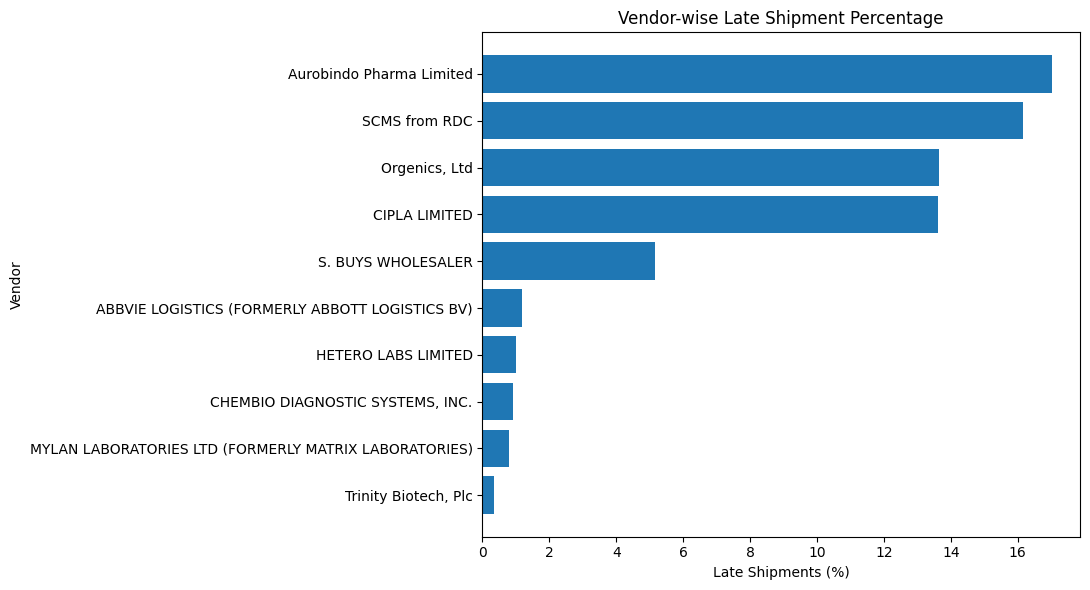

In [114]:
# Chart: Vendor-wise Late Shipment Percentage

vendor_chart = shipment_performance.sort_values(
    "LateShipmentPercentage",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    vendor_chart["VendorName"],
    vendor_chart["LateShipmentPercentage"]
)

plt.xlabel("Late Shipments (%)")
plt.ylabel("Vendor")
plt.title("Vendor-wise Late Shipment Percentage")
plt.tight_layout()
plt.show()


### Step 15C — Calculate Overall Shipment Delivery Performance

**Question:** Across all shipments, how many were early, on schedule, or late?

**What I am doing:** Calculate the difference between actual and scheduled delivery dates, classify each shipment, and aggregate counts and percentages.

In [115]:
#  Overall shipment-level delivery performance

query = """
WITH ShipmentDelays AS (
    SELECT
        s.ShipmentID,
        s.DeliveredToClientDate,
        MIN(tl.ScheduledDeliveryDate) AS ScheduledDate,
        MAX(tl.ScheduledDeliveryDate) AS LatestScheduledDate
    FROM Shipments s
    JOIN TransactionLines tl
        ON s.ShipmentID = tl.ShipmentID
    GROUP BY s.ShipmentID
)
SELECT
    COUNT(*) AS TotalShipments,

    SUM(
        CASE
            WHEN julianday(DeliveredToClientDate)
                 > julianday(ScheduledDate)
            THEN 1 ELSE 0
        END
    ) AS LateShipments,

    ROUND(
        100.0 * SUM(
            CASE
                WHEN julianday(DeliveredToClientDate)
                     > julianday(ScheduledDate)
                THEN 1 ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS LateShipmentPercentage,

    SUM(
        CASE
            WHEN julianday(DeliveredToClientDate)
                 = julianday(ScheduledDate)
            THEN 1 ELSE 0
        END
    ) AS OnScheduleShipments,

    SUM(
        CASE
            WHEN julianday(DeliveredToClientDate)
                 < julianday(ScheduledDate)
            THEN 1 ELSE 0
        END
    ) AS EarlyShipments,

    ROUND(
        AVG(
            julianday(DeliveredToClientDate)
            - julianday(ScheduledDate)
        ),
        2
    ) AS AverageDelayDays,

    SUM(
        CASE
            WHEN ScheduledDate <> LatestScheduledDate
            THEN 1 ELSE 0
        END
    ) AS ShipmentsWithMultipleScheduledDates

FROM ShipmentDelays;
"""

overall_performance = pd.read_sql_query(query, conn)
display(overall_performance)

,TotalShipments,LateShipments,LateShipmentPercentage,OnScheduleShipments,EarlyShipments,AverageDelayDays,ShipmentsWithMultipleScheduledDates
0,7030,805,11.45,4450,1775,-4.77,10


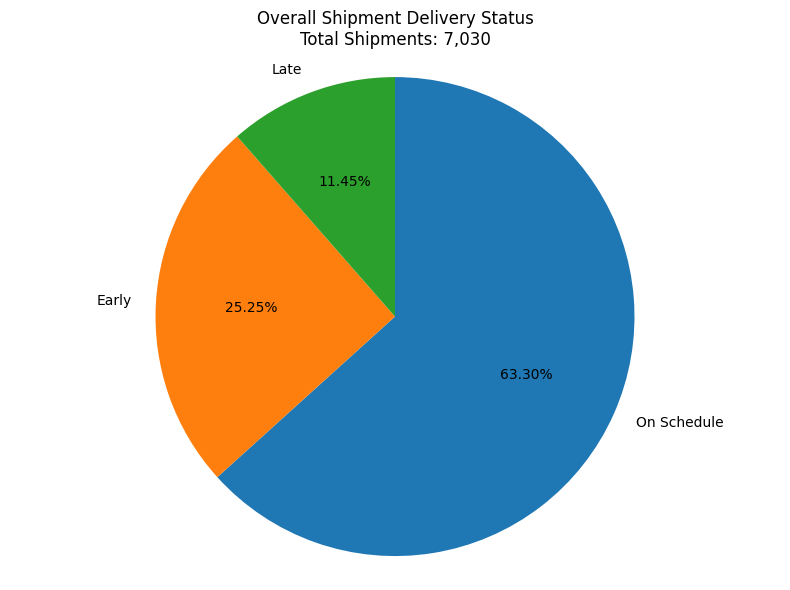

Shipment Delivery Summary
On Schedule: 4,450 (63.30%)
Early: 1,775 (25.25%)
Late: 805 (11.45%)
Total Shipments: 7,030


In [116]:
# Chart: Overall Shipment Delivery Status

# Extract counts directly from the existing Step 102 results
total_shipments = int(overall_performance["TotalShipments"].iloc[0])

status_labels = [
    "On Schedule",
    "Early",
    "Late"
]

status_values = [
    int(overall_performance["OnScheduleShipments"].iloc[0]),
    int(overall_performance["EarlyShipments"].iloc[0]),
    int(overall_performance["LateShipments"].iloc[0])
]

# Create the pie chart
plt.figure(figsize=(8, 6))

plt.pie(
    status_values,
    labels=status_labels,
    autopct="%1.2f%%",
    startangle=90,
    counterclock=False
)

plt.title(
    f"Overall Shipment Delivery Status\n"
    f"Total Shipments: {total_shipments:,}"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

# Display the underlying figures for verification
print("Shipment Delivery Summary")
for label, value in zip(status_labels, status_values):
    print(f"{label}: {value:,} ({value / total_shipments * 100:.2f}%)")

print(f"Total Shipments: {total_shipments:,}")


### Step 15D — Cross-Check the Delivery Results

**What I am doing:** Compare delivery-status summaries derived from the cleaned pandas data with results from SQLite.

**Why it matters:** Independent calculations provide a useful consistency check and may reveal differences caused by date handling, grouping, or missing values.

In [117]:
#  Compare cleaned dataset results with SQLite results

print("Cleaned dataset delivery status:")
print(df_clean["Delivery Status"].value_counts(dropna=False))

print("\nCleaned dataset delivery delay summary:")
print(df_clean["Delivery Delay Days"].describe())

print("\nSQLite transaction-line delivery status:")
query = """
SELECT
    CASE
        WHEN julianday(s.DeliveredToClientDate)
             < julianday(tl.ScheduledDeliveryDate)
            THEN 'Early'
        WHEN julianday(s.DeliveredToClientDate)
             = julianday(tl.ScheduledDeliveryDate)
            THEN 'On Schedule'
        ELSE 'Late'
    END AS DeliveryStatus,
    COUNT(*) AS TransactionLines
FROM Shipments s
JOIN TransactionLines tl
    ON s.ShipmentID = tl.ShipmentID
GROUP BY DeliveryStatus
ORDER BY DeliveryStatus;
"""

display(pd.read_sql_query(query, conn))

Cleaned dataset delivery status:
Delivery Status
On Schedule    6324
Early          2814
Late           1186
Name: count, dtype: int64

Cleaned dataset delivery delay summary:
count    10324.000000
mean        -6.023537
std         27.233640
min       -372.000000
25%         -3.000000
50%          0.000000
75%          0.000000
max        192.000000
Name: Delivery Delay Days, dtype: float64

SQLite transaction-line delivery status:


,DeliveryStatus,TransactionLines
0,Early,2814
1,Late,1186
2,On Schedule,6324


### Step 15E — Compare Delivery Performance by Shipment Mode

**Question:** Does the observed late-delivery rate vary by transportation mode?

**What I am doing:** Aggregate shipment-level outcomes by mode and compare shipment volume, late count, late percentage, and average delivery difference.

In [118]:
#  Delivery performance by shipment mode


query = """
WITH ShipmentDelays AS (
    SELECT
        s.ShipmentID,
        sm.ShipmentModeName,
        s.DeliveredToClientDate,
        MIN(tl.ScheduledDeliveryDate) AS ScheduledDate,
        MAX(tl.ScheduledDeliveryDate) AS LatestScheduledDate
    FROM Shipments s
    LEFT JOIN ShipmentModes sm
        ON s.ShipmentModeID = sm.ShipmentModeID
    JOIN TransactionLines tl
        ON s.ShipmentID = tl.ShipmentID
    GROUP BY
        s.ShipmentID,
        sm.ShipmentModeName
)
SELECT
    COALESCE(ShipmentModeName, 'Unknown / Not Recorded')
        AS ShipmentMode,
    COUNT(*) AS TotalShipments,

    SUM(
        CASE
            WHEN julianday(DeliveredToClientDate)
                 > julianday(ScheduledDate)
            THEN 1 ELSE 0
        END
    ) AS LateShipments,

    ROUND(
        100.0 * SUM(
            CASE
                WHEN julianday(DeliveredToClientDate)
                     > julianday(ScheduledDate)
                THEN 1 ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS LateShipmentPercentage,

    ROUND(
        AVG(
            julianday(DeliveredToClientDate)
            - julianday(ScheduledDate)
        ),
        2
    ) AS AverageDelayDays,

    SUM(
        CASE
            WHEN ScheduledDate <> LatestScheduledDate
            THEN 1 ELSE 0
        END
    ) AS ShipmentsWithMultipleScheduledDates

FROM ShipmentDelays
GROUP BY ShipmentModeName
ORDER BY TotalShipments DESC;
"""

mode_performance = pd.read_sql_query(query, conn)
display(mode_performance)

,ShipmentMode,TotalShipments,LateShipments,LateShipmentPercentage,AverageDelayDays,ShipmentsWithMultipleScheduledDates
0,Air,4541,388,8.54,-2.60,2
1,Truck,1442,299,20.74,-9.62,3
2,Air Charter,494,52,10.53,-19.15,0
3,Ocean,327,63,19.27,6.54,5
4,Unknown / Not Recorded,226,3,1.33,-2.48,0


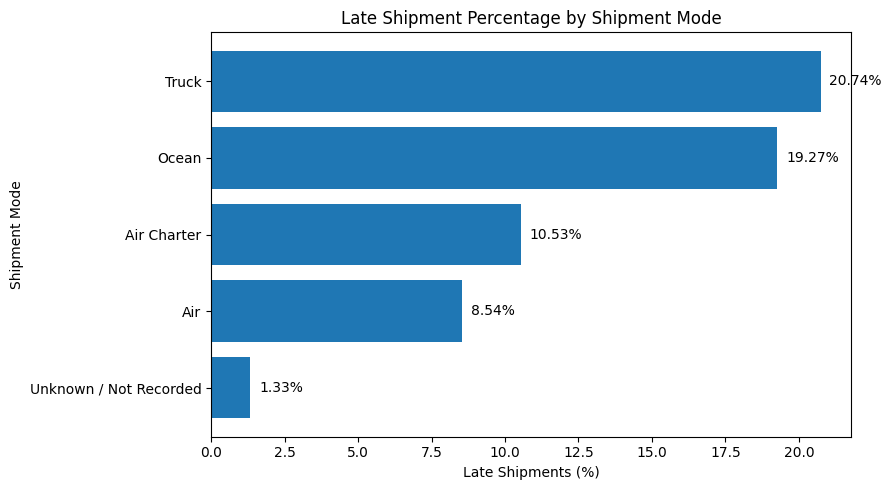

In [119]:
# Chart: Late Shipment Percentage by Shipment Mode

mode_chart = mode_performance.sort_values(
    "LateShipmentPercentage",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    mode_chart["ShipmentMode"],
    mode_chart["LateShipmentPercentage"]
)

plt.xlabel("Late Shipments (%)")
plt.ylabel("Shipment Mode")
plt.title("Late Shipment Percentage by Shipment Mode")

# Display percentage labels beside the bars
for index, value in enumerate(
    mode_chart["LateShipmentPercentage"]
):
    plt.text(
        value + 0.3,
        index,
        f"{value:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()


### Step 15F — Validate Shipment-Mode Counts

**What I am doing:** Check the overall shipment count and how many shipments have a recorded or missing shipment mode.

**Why it matters:** This helps interpret the mode comparison and makes missing classifications visible.

In [120]:
#  Validate shipment-mode counts

query = """
SELECT
    COUNT(*) AS TotalShipments,

    SUM(
        CASE
            WHEN ShipmentModeID IS NULL THEN 1
            ELSE 0
        END
    ) AS ShipmentsWithoutMode,

    COUNT(DISTINCT ShipmentModeID)
        AS DistinctRecordedModes

FROM Shipments;
"""

mode_validation = pd.read_sql_query(query, conn)
display(mode_validation)

print("\nShipment counts by stored mode:")
display(pd.read_sql_query("""
    SELECT
        COALESCE(sm.ShipmentModeName, 'Unknown / Not Recorded')
            AS ShipmentMode,
        COUNT(*) AS TotalShipments
    FROM Shipments s
    LEFT JOIN ShipmentModes sm
        ON s.ShipmentModeID = sm.ShipmentModeID
    GROUP BY sm.ShipmentModeName
    ORDER BY TotalShipments DESC;
""", conn))

,TotalShipments,ShipmentsWithoutMode,DistinctRecordedModes
0,7030,226,4



Shipment counts by stored mode:


,ShipmentMode,TotalShipments
0,Air,4541
1,Truck,1442
2,Air Charter,494
3,Ocean,327
4,Unknown / Not Recorded,226


### Step 15G — Examine Delivery Performance by Country

**Question:** How does delivery performance vary across countries?

**What I am doing:** Join shipments to the country/project information, calculate delivery delays, and summarize results geographically.

In [121]:
#  Delivery performance by country

import pandas as pd

query = """
WITH ShipmentDelays AS (
    SELECT
        s.ShipmentID,
        p.CountryID,
        s.DeliveredToClientDate,
        MIN(tl.ScheduledDeliveryDate) AS ScheduledDate,
        MAX(tl.ScheduledDeliveryDate) AS LatestScheduledDate
    FROM Shipments s
    JOIN PurchaseOrders po
        ON s.PurchaseOrderID = po.PurchaseOrderID
    JOIN Projects p
        ON po.ProjectID = p.ProjectID
    JOIN TransactionLines tl
        ON s.ShipmentID = tl.ShipmentID
    GROUP BY
        s.ShipmentID,
        p.CountryID
)
SELECT
    c.CountryName,
    COUNT(*) AS TotalShipments,

    SUM(
        CASE
            WHEN julianday(sd.DeliveredToClientDate)
                 > julianday(sd.ScheduledDate)
            THEN 1 ELSE 0
        END
    ) AS LateShipments,

    ROUND(
        100.0 * SUM(
            CASE
                WHEN julianday(sd.DeliveredToClientDate)
                     > julianday(sd.ScheduledDate)
                THEN 1 ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS LateShipmentPercentage,

    ROUND(
        AVG(
            julianday(sd.DeliveredToClientDate)
            - julianday(sd.ScheduledDate)
        ),
        2
    ) AS AverageDelayDays,

    SUM(
        CASE
            WHEN sd.ScheduledDate <> sd.LatestScheduledDate
            THEN 1 ELSE 0
        END
    ) AS ShipmentsWithMultipleScheduledDates

FROM ShipmentDelays sd
JOIN Countries c
    ON sd.CountryID = c.CountryID
GROUP BY c.CountryName
ORDER BY LateShipmentPercentage DESC, TotalShipments DESC;
"""

country_performance = pd.read_sql_query(query, conn)

print("Number of countries analyzed:", len(country_performance))
print("\nCountries with the highest late-shipment percentages:")
display(country_performance.head(10))

Number of countries analyzed: 43

Countries with the highest late-shipment percentages:


,CountryName,TotalShipments,LateShipments,LateShipmentPercentage,AverageDelayDays,ShipmentsWithMultipleScheduledDates
0,Senegal,3,1,33.33,1.00,0
1,Togo,3,1,33.33,5.33,0
2,Burundi,61,18,29.51,-6.69,0
3,Benin,8,2,25.00,3.13,0
4,Libya,4,1,25.00,-10.25,0
5,"Congo, DRC",113,24,21.24,7.26,0
6,South Africa,581,112,19.28,-3.14,8
7,Mozambique,404,72,17.82,-1.57,0
8,Ghana,45,7,15.56,1.91,0
9,Zambia,540,82,15.19,-4.44,0


### Step 15H — Focus on Countries with Sufficient Shipment Volume

**What I am doing:** Filter the country-level summary to countries meeting the query's minimum shipment threshold before comparing late-delivery rates.

**Why it matters:** Very small shipment counts can make percentages unstable or misleading.

In [122]:
# High-volume countries with late deliveries

query = """
WITH ShipmentDelays AS (
    SELECT
        s.ShipmentID,
        p.CountryID,
        s.DeliveredToClientDate,
        MIN(tl.ScheduledDeliveryDate) AS ScheduledDate
    FROM Shipments s
    JOIN PurchaseOrders po
        ON s.PurchaseOrderID = po.PurchaseOrderID
    JOIN Projects p
        ON po.ProjectID = p.ProjectID
    JOIN TransactionLines tl
        ON s.ShipmentID = tl.ShipmentID
    GROUP BY s.ShipmentID, p.CountryID
)
SELECT
    c.CountryName,
    COUNT(*) AS TotalShipments,
    SUM(
        CASE
            WHEN julianday(sd.DeliveredToClientDate)
                 > julianday(sd.ScheduledDate)
            THEN 1 ELSE 0
        END
    ) AS LateShipments,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN julianday(sd.DeliveredToClientDate)
                     > julianday(sd.ScheduledDate)
                THEN 1 ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS LateShipmentPercentage,
    ROUND(
        AVG(
            julianday(sd.DeliveredToClientDate)
            - julianday(sd.ScheduledDate)
        ),
        2
    ) AS AverageDelayDays
FROM ShipmentDelays sd
JOIN Countries c
    ON sd.CountryID = c.CountryID
GROUP BY c.CountryName
HAVING COUNT(*) >= 100
ORDER BY LateShipmentPercentage DESC, TotalShipments DESC;
"""

high_volume_countries = pd.read_sql_query(query, conn)
display(high_volume_countries)

,CountryName,TotalShipments,LateShipments,LateShipmentPercentage,AverageDelayDays
0,"Congo, DRC",113,24,21.24,7.26
1,South Africa,581,112,19.28,-3.14
2,Mozambique,404,72,17.82,-1.57
3,Zambia,540,82,15.19,-4.44
4,Zimbabwe,336,46,13.69,-8.76
5,Kenya,103,14,13.59,0.96
6,Nigeria,927,112,12.08,-11.52
7,Uganda,584,69,11.82,-6.42
8,Tanzania,434,50,11.52,-4.63
9,Côte d'Ivoire,760,82,10.79,-5.43


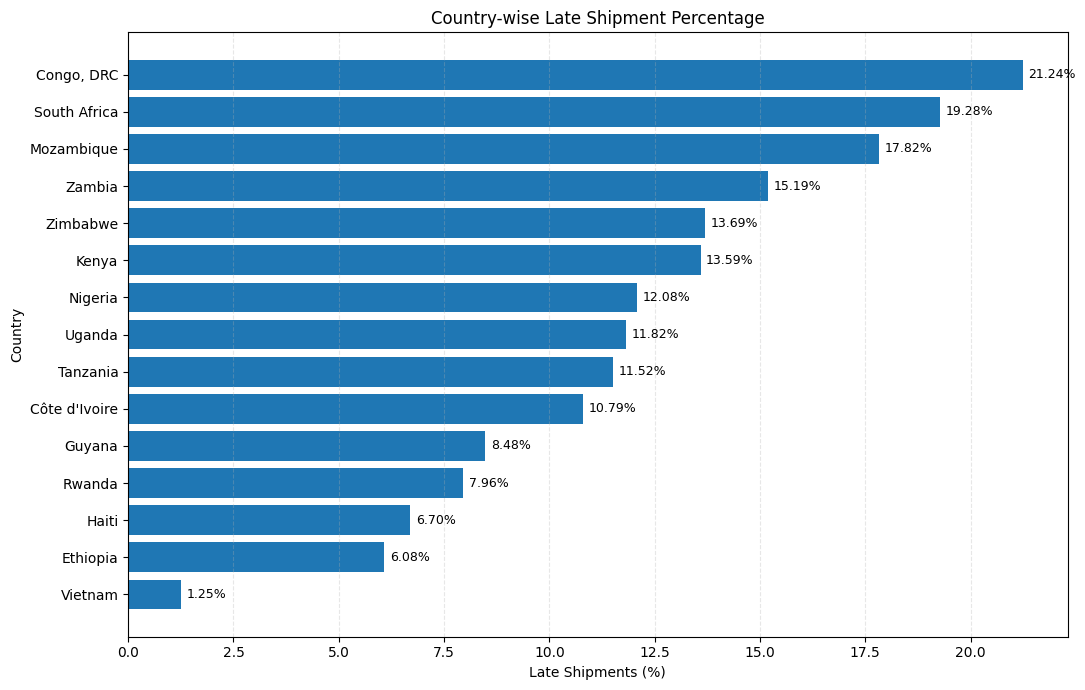

In [123]:
# Chart: Country-wise Late Shipment Percentage with Data Labels

country_chart = high_volume_countries.sort_values(
    "LateShipmentPercentage",
    ascending=True
)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    country_chart["CountryName"],
    country_chart["LateShipmentPercentage"]
)

plt.xlabel("Late Shipments (%)")
plt.ylabel("Country")
plt.title("Country-wise Late Shipment Percentage")

# Add percentage labels at the end of each bar
plt.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in country_chart["LateShipmentPercentage"]
    ],
    padding=4,
    fontsize=9
)

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### Step 15I — Compare Country and Shipment Mode Together

**Question:** Does the pattern by transportation mode look different across countries?

**What I am doing:** Group shipment outcomes by both country and mode and calculate late-delivery measures for each combination.

**Why it matters:** A combined breakdown can reveal patterns that a country-only or mode-only summary may hide.

In [124]:
#  Delivery performance by country and shipment mode

query = """
WITH ShipmentDelays AS (
    SELECT
        s.ShipmentID,
        p.CountryID,
        s.ShipmentModeID,
        s.DeliveredToClientDate,
        MIN(tl.ScheduledDeliveryDate) AS ScheduledDate
    FROM Shipments s
    JOIN PurchaseOrders po
        ON s.PurchaseOrderID = po.PurchaseOrderID
    JOIN Projects p
        ON po.ProjectID = p.ProjectID
    JOIN TransactionLines tl
        ON s.ShipmentID = tl.ShipmentID
    GROUP BY
        s.ShipmentID,
        p.CountryID,
        s.ShipmentModeID
)
SELECT
    c.CountryName,
    COALESCE(sm.ShipmentModeName, 'Unknown / Not Recorded')
        AS ShipmentMode,
    COUNT(*) AS TotalShipments,
    SUM(
        CASE
            WHEN julianday(sd.DeliveredToClientDate)
                 > julianday(sd.ScheduledDate)
            THEN 1 ELSE 0
        END
    ) AS LateShipments,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN julianday(sd.DeliveredToClientDate)
                     > julianday(sd.ScheduledDate)
                THEN 1 ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS LateShipmentPercentage,
    ROUND(
        AVG(
            julianday(sd.DeliveredToClientDate)
            - julianday(sd.ScheduledDate)
        ),
        2
    ) AS AverageDelayDays
FROM ShipmentDelays sd
JOIN Countries c
    ON sd.CountryID = c.CountryID
LEFT JOIN ShipmentModes sm
    ON sd.ShipmentModeID = sm.ShipmentModeID
GROUP BY
    c.CountryName,
    sm.ShipmentModeName
HAVING COUNT(*) >= 20
ORDER BY
    LateShipmentPercentage DESC,
    TotalShipments DESC;
"""

country_mode_performance = pd.read_sql_query(query, conn)

print("Country–shipment-mode combinations with at least 20 shipments:",
      len(country_mode_performance))

display(country_mode_performance.head(15))

Country–shipment-mode combinations with at least 20 shipments: 39


,CountryName,ShipmentMode,TotalShipments,LateShipments,LateShipmentPercentage,AverageDelayDays
0,Rwanda,Truck,52,17,32.69,-10.75
1,Mozambique,Truck,201,64,31.84,-2.94
2,Burundi,Air,61,18,29.51,-6.69
3,South Africa,Ocean,223,63,28.25,9.93
4,South Africa,Air,144,39,27.08,-16.76
5,Tanzania,Truck,145,36,24.83,-9.94
6,Zambia,Truck,272,64,23.53,-7.78
7,Côte d'Ivoire,Truck,166,37,22.29,-18.14
8,"Congo, DRC",Air,112,24,21.43,7.32
9,Zimbabwe,Truck,197,40,20.30,-13.89


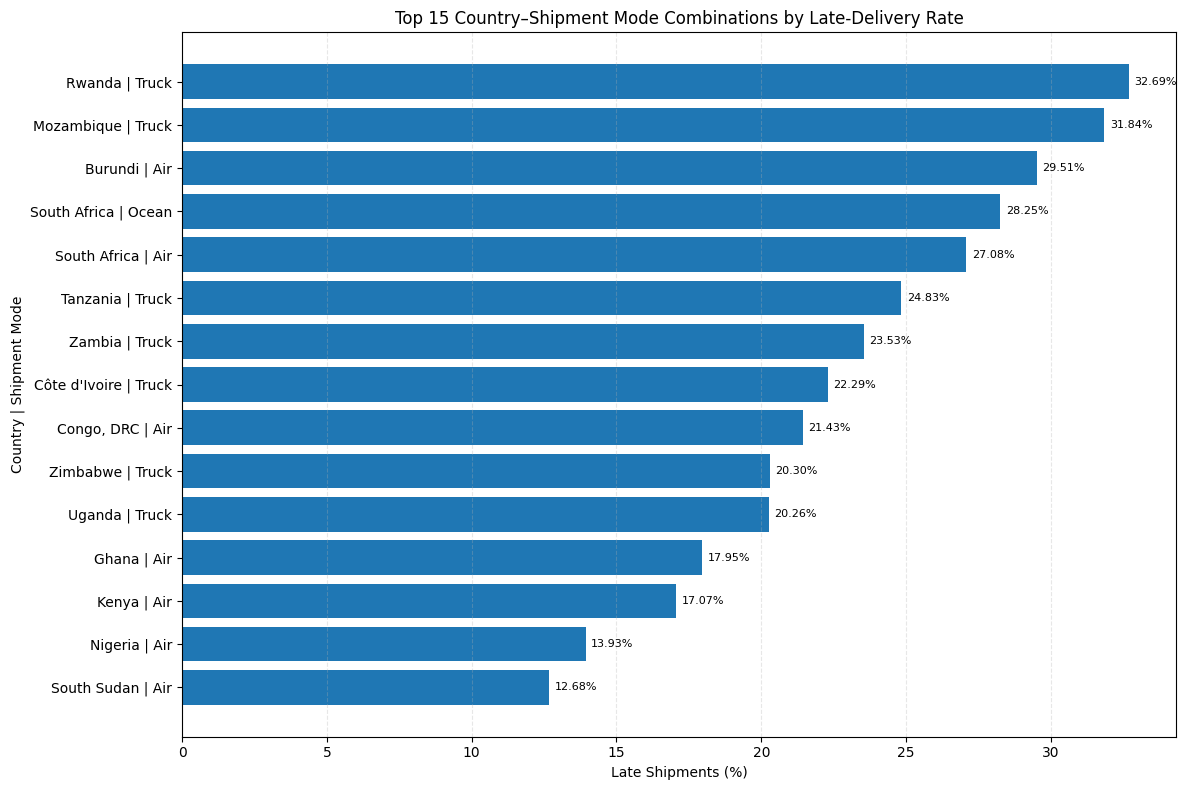

In [125]:
# Chart: Late Shipment Percentage by Country and Shipment Mode

country_mode_chart = (
    country_mode_performance
    .sort_values("LateShipmentPercentage", ascending=True)
    .tail(15)
    .copy()
)

# Combine country and shipment mode for clear labels
country_mode_chart["Country_Mode"] = (
    country_mode_chart["CountryName"]
    + " | "
    + country_mode_chart["ShipmentMode"]
)

plt.figure(figsize=(12, 8))

bars = plt.barh(
    country_mode_chart["Country_Mode"],
    country_mode_chart["LateShipmentPercentage"]
)

plt.xlabel("Late Shipments (%)")
plt.ylabel("Country | Shipment Mode")
plt.title("Top 15 Country–Shipment Mode Combinations by Late-Delivery Rate")

# Add percentage labels to each bar
plt.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in country_mode_chart["LateShipmentPercentage"]
    ],
    padding=4,
    fontsize=8
)

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### Step 15J — Identify the Largest Contributors to Late Shipments

**Question:** Which country–shipment-mode combinations account for the largest numbers of late shipments?

**What I am doing:** Use CTEs to summarize shipment-level delays by country and mode, exclude combinations with fewer than 20 shipments, sort by late-shipment count, and return the top 15.

In [126]:
# Largest contributors to late shipments

query = """
WITH ShipmentDelays AS (
    SELECT
        s.ShipmentID,
        p.CountryID,
        s.ShipmentModeID,
        s.DeliveredToClientDate,
        MIN(tl.ScheduledDeliveryDate) AS ScheduledDate
    FROM Shipments s
    JOIN PurchaseOrders po
        ON s.PurchaseOrderID = po.PurchaseOrderID
    JOIN Projects p
        ON po.ProjectID = p.ProjectID
    JOIN TransactionLines tl
        ON s.ShipmentID = tl.ShipmentID
    GROUP BY
        s.ShipmentID,
        p.CountryID,
        s.ShipmentModeID
),
CountryMode AS (
    SELECT
        c.CountryName,
        COALESCE(sm.ShipmentModeName, 'Unknown / Not Recorded')
            AS ShipmentMode,
        COUNT(*) AS TotalShipments,
        SUM(
            CASE
                WHEN julianday(sd.DeliveredToClientDate)
                     > julianday(sd.ScheduledDate)
                THEN 1 ELSE 0
            END
        ) AS LateShipments
    FROM ShipmentDelays sd
    JOIN Countries c
        ON sd.CountryID = c.CountryID
    LEFT JOIN ShipmentModes sm
        ON sd.ShipmentModeID = sm.ShipmentModeID
    GROUP BY c.CountryName, sm.ShipmentModeName
)
SELECT
    CountryName,
    ShipmentMode,
    TotalShipments,
    LateShipments,
    ROUND(
        100.0 * LateShipments / TotalShipments, 2
    ) AS LateShipmentPercentage
FROM CountryMode
WHERE TotalShipments >= 20
ORDER BY LateShipments DESC, TotalShipments DESC
LIMIT 15;
"""

late_contributors = pd.read_sql_query(query, conn)
display(late_contributors)

,CountryName,ShipmentMode,TotalShipments,LateShipments,LateShipmentPercentage
0,Zambia,Truck,272,64,23.53
1,Mozambique,Truck,201,64,31.84
2,South Africa,Ocean,223,63,28.25
3,Nigeria,Air,438,61,13.93
4,Nigeria,Air Charter,466,51,10.94
5,Côte d'Ivoire,Air,514,44,8.56
6,Zimbabwe,Truck,197,40,20.30
7,South Africa,Air,144,39,27.08
8,Uganda,Air,418,38,9.09
9,Côte d'Ivoire,Truck,166,37,22.29


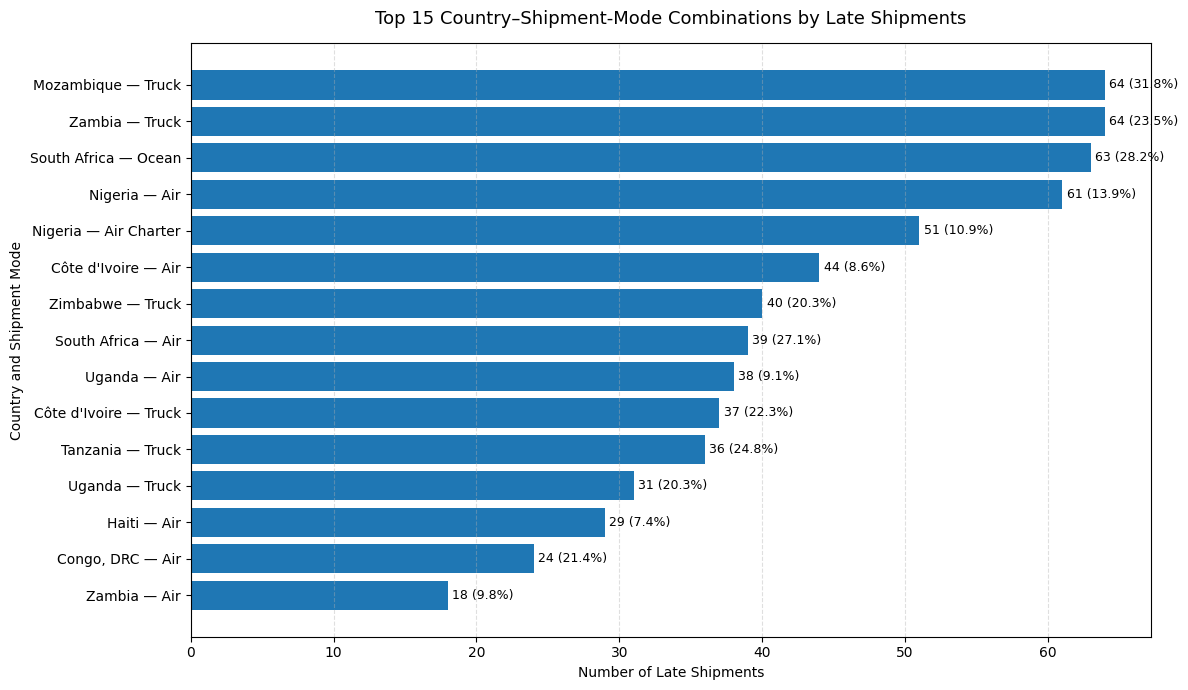

,CountryName,ShipmentMode,TotalShipments,LateShipments,LateShipmentPercentage
0,Zambia,Truck,272,64,23.53
1,Mozambique,Truck,201,64,31.84
2,South Africa,Ocean,223,63,28.25
3,Nigeria,Air,438,61,13.93
4,Nigeria,Air Charter,466,51,10.94
5,Côte d'Ivoire,Air,514,44,8.56
6,Zimbabwe,Truck,197,40,20.30
7,South Africa,Air,144,39,27.08
8,Uganda,Air,418,38,9.09
9,Côte d'Ivoire,Truck,166,37,22.29


In [127]:
# Chart: Largest Contributors to Late Shipments

import matplotlib.pyplot as plt

# Prepare data for visualization
chart_data = late_contributors.copy()

chart_data["Country_Mode"] = (
    chart_data["CountryName"].astype(str)
    + " — "
    + chart_data["ShipmentMode"].astype(str)
)

# Sort so the largest contributor appears at the top
chart_data = chart_data.sort_values(
    by="LateShipments",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    chart_data["Country_Mode"],
    chart_data["LateShipments"]
)

# Add late-shipment counts and percentages to each bar
for bar, (_, row) in zip(bars, chart_data.iterrows()):
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{int(row["LateShipments"])} ({row["LateShipmentPercentage"]:.1f}%)',
        va="center",
        fontsize=9
    )

plt.title(
    "Top 15 Country–Shipment-Mode Combinations by Late Shipments",
    fontsize=13,
    pad=14
)
plt.xlabel("Number of Late Shipments")
plt.ylabel("Country and Shipment Mode")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Display the chart data for verification
display(
    chart_data[
        [
            "CountryName",
            "ShipmentMode",
            "TotalShipments",
            "LateShipments",
            "LateShipmentPercentage"
        ]
    ].sort_values(
        by="LateShipments",
        ascending=False
    ).reset_index(drop=True)
)


## Key Findings from SQL Analysis

The SQL analysis examines shipment-level delivery performance across vendors, shipment modes, countries, and country–shipment-mode combinations. The findings highlight overall delivery outcomes and areas that may warrant further operational investigation.

### 1. Overall Delivery Performance

The analysis covers **7,030 shipments**. Of these, **4,450 (63.30%) were delivered on schedule, 1,775 (25.25%) were delivered early, and 805 (11.45%) were delivered late**.

The average delivery delay was **−4.77 days**, indicating that shipments were delivered earlier than their scheduled dates on average. However, the 11.45% late-delivery rate shows that a meaningful proportion of shipments did not meet their scheduled delivery dates. Overall averages should therefore be considered alongside the proportion of late shipments.

### 2. Vendor Performance

Vendor-level analysis compares shipment volumes and late-delivery rates to distinguish between vendors handling large volumes and those experiencing a higher proportion of late deliveries.

SCMS from RDC handled **3,440 shipments**, of which **556 were late (16.16%)**. This makes it important to assess vendor performance using both shipment volume and late-delivery percentage rather than the number of late shipments alone.

Further investigation into vendor-specific delivery patterns may help identify areas for operational review. The observed differences should not, on their own, be interpreted as evidence that a particular vendor caused delays.

### 3. Shipment-Mode Performance

Late-delivery rates differed across shipment modes:

- **Air:** 8.54%
- **Truck:** 20.74%
- **Ocean:** 19.27%

Among these modes, Truck had the highest late-delivery percentage, followed by Ocean, while Air had the lowest. These results indicate that delivery outcomes vary across transportation modes in this dataset.

Further analysis of shipment volumes, routes, scheduled delivery dates, and operational constraints would be needed to understand the reasons behind these differences.

### 4. Geographical and Combined Analysis

The country-level analysis compares late-delivery rates among countries with at least 100 shipments. The combined country–shipment-mode analysis examines combinations with at least 20 shipments.

These analyses help identify geographical and transportation patterns that may warrant closer investigation. However, the results should be interpreted alongside shipment volumes, as percentages based on smaller groups can be more sensitive to individual late deliveries.

The country and combined analyses are useful for identifying potential priorities for further review; specific country-level conclusions should be based on the corresponding query outputs.

### Overall Interpretation

The analysis demonstrates how a normalized relational database can connect procurement, vendor, product, shipment, transportation, and geographical information to support logistics performance monitoring.

The findings highlight three areas for further investigation: late deliveries across vendors, differences in performance across shipment modes, and variation across countries and country–shipment-mode combinations. These insights can inform more targeted operational analysis, while recognizing that the descriptive results alone do not establish the causes of delivery delays.

## Step 17 — Entity Relationship Diagram (ERD)

The ER diagram illustrates the structure of the 12 normalized tables in the SQLite database. It identifies primary keys (PKs) and foreign keys (FKs) and shows the relationships between entities. The diagram provides a visual overview of how the database organizes and connects logistics information.

**What I am doing:** Present the diagram of the 12 normalized tables, their primary keys, foreign keys, and relationships.

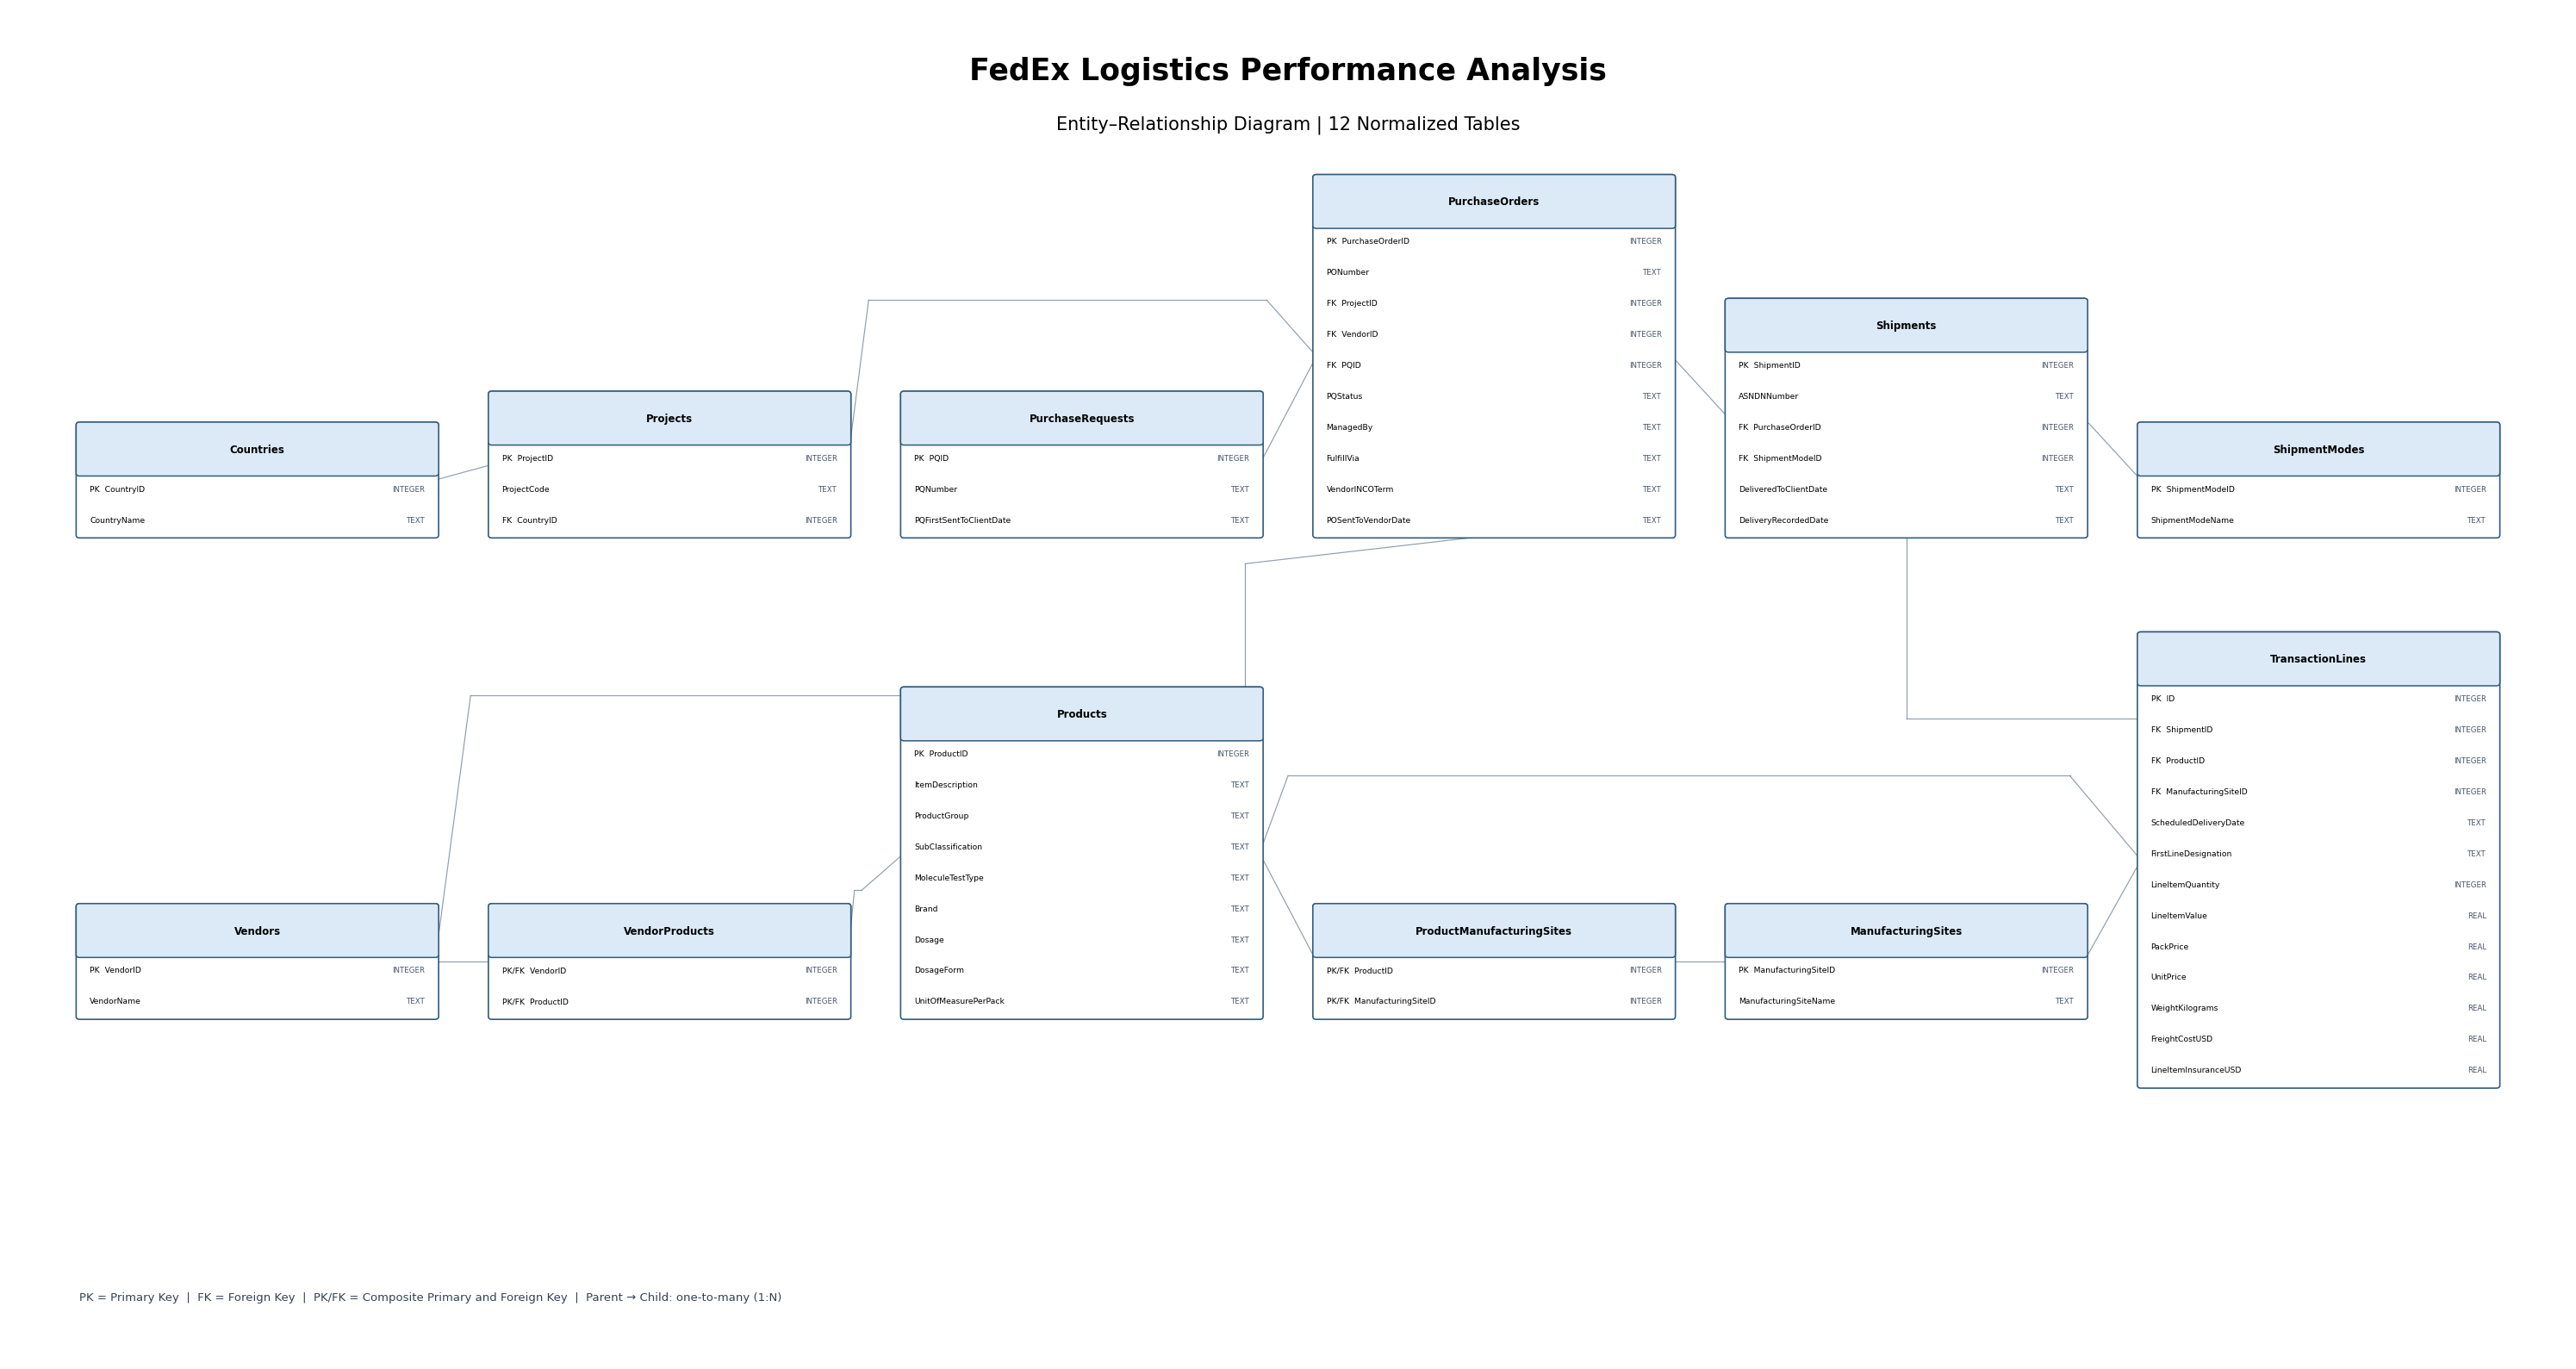

ER diagram generated.
Tables: 12
PNG: /content/fedex_logistics_erd_final.png
PDF: /content/fedex_logistics_erd_final.pdf


In [128]:
import sqlite3
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Image

# ------------------------------------------------------------
# 1. USE EXISTING SQLITE DATABASE
# ------------------------------------------------------------

try:
    conn.execute("SELECT name FROM sqlite_master LIMIT 1")
except NameError:
    conn = sqlite3.connect("/content/fedex_logistics.db")

tables = [
    r[0] for r in conn.execute("""
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
          AND name NOT LIKE 'sqlite_%'
        ORDER BY name
    """).fetchall()
]

metadata = {}

for table in tables:
    metadata[table] = {
        "columns": conn.execute(
            f'PRAGMA table_info("{table}")'
        ).fetchall(),
        "foreign_keys": conn.execute(
            f'PRAGMA foreign_key_list("{table}")'
        ).fetchall()
    }

# ------------------------------------------------------------
# 2. TABLE LAYOUT
# ------------------------------------------------------------

# The layout keeps procurement and shipment flow in the top row,
# and product/vendor/manufacturing relationships in the bottom.
# Coordinates are lower-left corners.

positions = {
    "Countries": (0.5, 7.2),
    "Projects": (3.4, 7.2),
    "PurchaseRequests": (6.3, 7.2),
    "PurchaseOrders": (9.2, 7.2),
    "Shipments": (12.1, 7.2),
    "ShipmentModes": (15.0, 7.2),

    "Vendors": (0.5, 3.0),
    "VendorProducts": (3.4, 3.0),
    "Products": (6.3, 3.0),
    "ProductManufacturingSites": (9.2, 3.0),
    "ManufacturingSites": (12.1, 3.0),
    "TransactionLines": (15.0, 2.4),
}

missing = set(tables) - set(positions)
if missing:
    raise ValueError(f"Missing table positions: {missing}")

box_w = 2.5
header_h = 0.42
row_h = 0.27

table_h = {
    t: header_h + row_h * len(metadata[t]["columns"])
    for t in tables
}

# ------------------------------------------------------------
# 3. CANVAS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(30, 16))
ax.set_xlim(0, 18)
ax.set_ylim(0, 11.8)
ax.axis("off")

ax.text(
    9, 11.25,
    "FedEx Logistics Performance Analysis",
    ha="center", va="center",
    fontsize=25, fontweight="bold"
)

ax.text(
    9, 10.78,
    "Entity–Relationship Diagram | 12 Normalized Tables",
    ha="center", va="center",
    fontsize=15
)

# ------------------------------------------------------------
# 4. DRAW TABLES
# ------------------------------------------------------------

for table in tables:
    x, y = positions[table]
    h = table_h[table]

    ax.add_patch(FancyBboxPatch(
        (x, y), box_w, h,
        boxstyle="round,pad=0.025",
        facecolor="white",
        edgecolor="#315B7D",
        linewidth=1.2,
        zorder=3
    ))

    ax.add_patch(FancyBboxPatch(
        (x, y + h - header_h), box_w, header_h,
        boxstyle="round,pad=0.025",
        facecolor="#DCEAF7",
        edgecolor="#315B7D",
        linewidth=1.1,
        zorder=4
    ))

    ax.text(
        x + box_w / 2,
        y + h - header_h / 2,
        table,
        ha="center", va="center",
        fontsize=8.5, fontweight="bold",
        zorder=5
    )

    columns = sorted(
        metadata[table]["columns"],
        key=lambda c: (c[5] == 0, c[5] if c[5] else c[0])
    )

    pk_cols = {c[1] for c in columns if c[5] > 0}
    fk_cols = {fk[3] for fk in metadata[table]["foreign_keys"]}

    for i, col in enumerate(columns):
        name = col[1]
        dtype = col[2] or "ANY"

        if name in pk_cols and name in fk_cols:
            key = "PK/FK"
        elif name in pk_cols:
            key = "PK"
        elif name in fk_cols:
            key = "FK"
        else:
            key = ""

        yy = y + h - header_h - (i + 0.5) * row_h

        ax.text(
            x + 0.07, yy,
            f"{key}  {name}" if key else name,
            ha="left", va="center",
            fontsize=6.7, zorder=5
        )

        ax.text(
            x + box_w - 0.07, yy,
            dtype,
            ha="right", va="center",
            fontsize=6.2, color="#475569",
            zorder=5
        )

# ------------------------------------------------------------
# 5. RELATIONSHIP ROUTING
# ------------------------------------------------------------

def bounds(table):
    x, y = positions[table]
    h = table_h[table]

    return {
        "left": x,
        "right": x + box_w,
        "bottom": y,
        "top": y + h,
        "cx": x + box_w / 2,
        "cy": y + h / 2
    }


def edge_anchor(table, side, offset=0):
    b = bounds(table)

    if side == "left":
        return (b["left"], b["cy"] + offset)
    if side == "right":
        return (b["right"], b["cy"] + offset)
    if side == "top":
        return (b["cx"] + offset, b["top"])
    return (b["cx"] + offset, b["bottom"])


# Define routing corridors for important connections.
# All parent-child pairs still come from actual SQLite FKs.
# Routes are presentation only, not additional relationships.

manual_routes = {
    ("Countries", "Projects"): (
        "right", "left", []
    ),
    ("Projects", "PurchaseOrders"): (
        "right", "left",
        [(6.05, 9.25), (8.85, 9.25)]
    ),
    ("Vendors", "PurchaseOrders"): (
        "right", "bottom",
        [(3.25, 5.8), (8.7, 5.8), (8.7, 6.95)]
    ),
    ("PurchaseRequests", "PurchaseOrders"): (
        "right", "left", []
    ),
    ("PurchaseOrders", "Shipments"): (
        "right", "left", []
    ),
    ("ShipmentModes", "Shipments"): (
        "left", "right", []
    ),
    ("Shipments", "TransactionLines"): (
        "bottom", "top",
        [(13.35, 5.6), (16.25, 5.6)]
    ),
    ("Products", "TransactionLines"): (
        "right", "left",
        [(9.0, 5.1), (14.5, 5.1)]
    ),
    ("ManufacturingSites", "TransactionLines"): (
        "right", "left", []
    ),
    ("Vendors", "VendorProducts"): (
        "right", "left", []
    ),
    ("Products", "VendorProducts"): (
        "left", "right",
        [(6.0, 4.1), (5.95, 4.1)]
    ),
    ("Products", "ProductManufacturingSites"): (
        "right", "left", []
    ),
    ("ManufacturingSites", "ProductManufacturingSites"): (
        "left", "right", []
    ),
}

# Track relationship-line offsets where several FKs share a table pair.
pair_counts = {}

for child in tables:
    for fk in metadata[child]["foreign_keys"]:
        parent = fk[2]

        if parent not in positions:
            continue

        pair = (parent, child)
        idx = pair_counts.get(pair, 0)
        pair_counts[pair] = idx + 1

        if pair in manual_routes:
            start_side, end_side, bends = manual_routes[pair]
            start = edge_anchor(parent, start_side, idx * 0.07)
            end = edge_anchor(child, end_side, idx * 0.07)

            # Use explicit orthogonal bends where supplied.
            points = [start] + bends + [end]
        else:
            # Default to a short elbow path between table edges.
            pb = bounds(parent)
            cb = bounds(child)

            if cb["cx"] >= pb["cx"]:
                start = edge_anchor(parent, "right")
                end = edge_anchor(child, "left")
            else:
                start = edge_anchor(parent, "left")
                end = edge_anchor(child, "right")

            mid_x = (start[0] + end[0]) / 2
            points = [
                start,
                (mid_x, start[1]),
                (mid_x, end[1]),
                end
            ]

        for a, b in zip(points[:-1], points[1:]):
            ax.plot(
                [a[0], b[0]],
                [a[1], b[1]],
                color="#71869B",
                linewidth=0.85,
                alpha=0.8,
                zorder=1
            )

# ------------------------------------------------------------
# 6. CARDINALITY KEY
# ------------------------------------------------------------

# A child FK references one parent record.
# The parent may be related to many child records.
ax.text(
    0.5, 0.55,
    "PK = Primary Key  |  FK = Foreign Key  |  "
    "PK/FK = Composite Primary and Foreign Key  |  "
    "Parent → Child: one-to-many (1:N)",
    ha="left", va="center",
    fontsize=9.5, color="#334155"
)

# ------------------------------------------------------------
# 7. EXPORT PNG AND PDF
# ------------------------------------------------------------

plt.tight_layout()

png_path = "/content/fedex_logistics_erd_final.png"
pdf_path = "/content/fedex_logistics_erd_final.pdf"

fig.savefig(
    png_path, dpi=300,
    bbox_inches="tight", facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight", facecolor="white"
)

plt.show()

print("ER diagram generated.")
print("Tables:", len(tables))
print("PNG:", png_path)
print("PDF:", pdf_path)

## Conclusion

This project demonstrates the design and implementation of a relational database for the FedEx Logistics Performance Analysis case study using the SCMS Delivery History dataset. The original logistics data was organized into 12 related tables, with primary keys and foreign keys used to establish relationships between entities.

The database was implemented in SQLite and assessed through integrity checks and record-count validation. An Entity Relationship Diagram (ERD) was also developed to illustrate the database structure and relationships.

SQL queries were used to examine shipment-level delivery performance across vendors, shipment modes, and countries. The results showed that 11.45% of the 7,030 shipments were late, while delivery outcomes varied across shipment modes and other operational dimensions. Visualizations helped communicate these patterns and identify areas for further investigation.

Overall, the project demonstrates how relational database design, data integrity checks, SQL analysis, and data visualization can work together to organize logistics information and support evidence-based operational review. Further analysis would be required to establish the underlying causes of late deliveries and evaluate potential improvements.